# 22 · Réseaux récurrents (RNN, LSTM, GRU) — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch22_rnn/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 22.Q1 à 22.Q12, 22.R1 à 22.R3, 22.1 à 22.5, 22.8 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 22.12 | build_vocab, encode et decode sur Holmes et Verne | 🔨 | ★★ | 30 |
|  | 22.13 | make_windows et make_sequence_pairs | 🔨 | ★★ | 30 |
|  | 22.14 | Un MLP sur des fenêtres : l'ordre compte-t-il ? | 🔮 | ★★ | 20 |
| B | 22.15 | rnn_cell_forward et rnn_forward | 🔨 | ★★ | 30 |
|  | 22.16 | lstm_cell_forward et lstm_forward (portes i, f, g, o) | 🔨 | ★★★ | 45 |
|  | 22.17 | gru_cell_forward (portes r, z, n) | 🔨 | ★★ | 25 |
|  | 22.18 | Benchmark : ta cellule NumPy contre nn.LSTM | 🛠️ | ★★ | 20 |
|  | 22.19 | Mesurer la disparition du gradient : RNN tanh contre LSTM | 🔬 | ★★ | 30 |
| C | 22.20 | temperature_softmax et sample_from_logits | 🔨 | ★★ | 25 |
|  | 22.21 | Série temporelle piégée : fuite, mélange et batch_first | 🐛 | ★★ | 25 |
|  | 22.22 | RNN profonds et bidirectionnels : formes de output et h_n | 📦 | ★★ | 25 |
|  | 22.23 | Prévoir les taches solaires avec nn.LSTM, face à la persistance | 📦 | ★★★ | 45 |
|  | 22.24 | Température : prédire l'allure du texte généré | 🔮 | ★ | 10 |
| D | 22.25 | Générer du Holmes caractère par caractère (deux LSTM, many-to-one) | 📦 | ★★★ | 60 |
|  | 22.26 | Lire la courbe de loss et la perplexité du générateur | 📈 | ★★ | 15 |
|  | 22.27 | Holmes contre Verne : même réseau, deux langues | 🔬 | ★★★ | 40 |
|  | 22.28 | CNN-LSTM : la balle monte-t-elle ou descend-elle ? | 📦 | ★★★ | 50 |
|  | 22.29 | Défi taches solaires : battre la persistance de 20 % à six mois | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Découper une série ou un texte en fenêtres, compter les exemples, et valider une prévision sans fuite de données.
- Programmer en NumPy, dans `mylearn.rnn`, les cellules RNN, LSTM et GRU, et les comparer à `nn.RNN`, `nn.LSTM` et `nn.GRU`.
- Mesurer la disparition du gradient, puis entraîner un LSTM qui prévoit les taches solaires et un autre qui écrit du Holmes caractère par caractère.

**Rappel express.** Cellule RNN : $h_t = \tanh(x_t W_{ih} + b_{ih} + h_{t-1} W_{hh} + b_{hh})$. LSTM (portes $i, f, g, o$) : $c_t = f_t \odot c_{t-1} + i_t \odot g_t$, $h_t = o_t \odot \tanh(c_t)$. GRU (portes $r, z, n$) : $h_t = (1 - z_t) \odot n_t + z_t \odot h_{t-1}$. Paramètres d'une couche PyTorch : $k\,(DH + H^2 + 2H)$, $k = 1, 4, 3$. Fenêtres : $N = \lfloor (T - w - h)/s \rfloor + 1$. Température : $p = \mathrm{softmax}(z/T)$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 22.1 à 22.5 et 🧮 22.8)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme : entre guillemets (`"(3, 5, 1)"`) ; un mot : entre guillemets (`"fit"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les preuves ∂ 22.6 et 22.7, la réflexion (🗣️ 22.9, ⚖️ 22.10, 📄 22.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np


def sigmoid(z):
    return 1 / (1 + math.exp(-z))


def n_windows(T, w, h=1, s=1):
    """Number of windows of w values whose target lies h steps after the window (starts s apart)."""
    return (T - w - h) // s + 1


def n_recurrent(d, h, blocks):
    """Parameters of one PyTorch recurrent layer: blocks of H columns, two bias vectors."""
    return blocks * (d * h + h * h + 2 * h)


def softmax_t(z, t):
    e = np.exp((np.asarray(z, float) - max(z)) / t)
    return e / e.sum()


# Ex 22.2: a scalar RNN cell h_t = tanh(u x_t + w h_{t-1} + b), y_t = v h_t
def scalar_rnn(xs, u=1.0, w=0.5, b=0.0, h=0.0):
    states = []
    for x in xs:
        h = math.tanh(u * x + w * h + b)
        states.append(h)
    return states


H_222 = scalar_rnn([2, 0, -1])
H_REV_222 = scalar_rnn([-1, 0, 2])

# Ex 22.4: one LSTM step, gates in the order i, f, g, o
W_IH_224, W_HH_224, B_224 = [-0.5, 1, 1, -1], [1, -2, 0, 3], [0, 1, 0, 0]
A_224 = [W_IH_224[k] * 1 + W_HH_224[k] * 0.5 + B_224[k] for k in range(4)]
I_224, F_224, G_224, O_224 = sigmoid(A_224[0]), sigmoid(A_224[1]), math.tanh(A_224[2]), sigmoid(A_224[3])
C_224 = F_224 * 2 + I_224 * G_224
H_224 = O_224 * math.tanh(C_224)
C_OPEN_224 = sigmoid(A_224[1] + 20) * 2 + sigmoid(A_224[0] - 20) * G_224

# Ex 22.5: the logits of « k », « e », « a » after « Sherloc »
Z_225 = [3.0, 1.0, 0.5]

# Ex 22.8: the CNN-LSTM of the book (128 x 128 frames, 8 filters 5 x 5, stride 2, padding 2, LSTM 128, 9 classes)
SIDE_228 = (128 + 2 * 2 - 5) // 2 + 1
D_228 = SIDE_228 * SIDE_228 * 8
CONV_228 = 8 * (5 * 5 + 1)
LSTM_228 = n_recurrent(D_228, 128, 4)
DENSE_228 = 128 * 9 + 9
MACS_228 = D_228 * 4 * 128

**22.Q1 — Pourquoi un réseau dense ignore l'ordre**

In [3]:
wb.record("22.Q1a", True, mistakes={"une permutation FIXE des entrées : le réseau peut-il permuter ses poids de la même façon ?": False})
wb.record("22.Q1b", "B", mistakes={"une couche dense ne trie rien : elle multiplie chaque entrée par son poids": "A",
          "la loss dépend bien des entrées, à travers les prédictions": "C",
          "c'est le RNN qui garde un état, pas la couche dense": "D"})
wb.record("22.Q1c", False, mistakes={"si l'ordre change d'une fenêtre à l'autre, une entrée porte-t-elle encore toujours la même position ?": True})
wb.record("22.Q1d", "B", mistakes={"des nombres sans lien entre eux ne forment pas une séquence": "A",
          "la quantité de données ne fait pas une séquence": "C", "les labels ne font pas une séquence": "D"})
wb.record("22.Q1e", True, mistakes={"écris les positions des fenêtres qui démarrent en 0 et en 1": False})

WB_ANSWER {"hash": "d8293619dc0f06fde351660650bfffbbf0b507cd82467f521ec2316beffdb41e", "id": "22.Q1a", "kind": "bool", "mistakes": {"577a7c4dc2ba2a784a5af12e3d21dfaad7742273de71a59e8df0966d700b4af7": "une permutation FIXE des entrées : le réseau peut-il permuter ses poids de la même façon ?"}}
📝 Ex 22.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "3cc7dc91d2fa894f31008ff4aa2b7dd192c976506e5e5e2409450fcf1f6b5370", "id": "22.Q1b", "kind": "str", "mistakes": {"2837ec752f979bc3e0e2105b9d93ddc5008245b627df29f791ca7d591f8591a0": "c'est le RNN qui garde un état, pas la couche dense", "305b588926a38fd29ce590132253488ea0f22f7866b082498551235799a94223": "la loss dépend bien des entrées, à travers les prédictions", "a85312deb378aa44b11ea012c7dc553d019f645237070871a779d6bc4d449b14": "une couche dense ne trie rien : elle multiplie chaque entrée par son poids"}}
📝 Ex 22.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "dddb0cb7c0c228676d0f16fd854f4402b1b358e186c140804fbca2160a0ff49a", "id"

**22.Q2 — État ou poids : qu'est-ce qui change en production ?**

In [4]:
wb.record("22.Q2a", False, mistakes={"sans optimiseur, qu'est-ce qui modifierait les poids ?": True})
wb.record("22.Q2b", True, mistakes={"relis le §22.3 : que calcule la cellule à chaque nouvelle entrée ?": False})
wb.record("22.Q2c", True, mistakes={"mêmes poids, mêmes entrées, même état de départ : qu'est-ce qui pourrait différer ?": False})
wb.record("22.Q2d", False, mistakes={"après la phrase A, l'état de départ de B est-il encore nul ?": True})
wb.record("22.Q2e", "B", mistakes={"qu'est-ce qui est recalculé à chaque entrée ?": "A",
          "les gradients ne servent qu'à l'entraînement": "C", "le learning rate est un hyperparamètre fixe": "D"})

WB_ANSWER {"hash": "545d59f07f237da45349a0bbf96696253ed0007cb3b46b5333d97aaf856a4509", "id": "22.Q2a", "kind": "bool", "mistakes": {"f44cff714dafa5a636c6b2004761d0138514bc8793b53d1c883a9e52f3f3908f": "sans optimiseur, qu'est-ce qui modifierait les poids ?"}}
📝 Ex 22.Q2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f71dc6ae0bd888635a9a663757183ecad26524db19ca3d273f202b7916a3bb33", "id": "22.Q2b", "kind": "bool", "mistakes": {"5dd6ed674d9ec36ff01ec3f726ddcb424bbb273efda37434b85e76a42e813174": "relis le §22.3 : que calcule la cellule à chaque nouvelle entrée ?"}}
📝 Ex 22.Q2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "76c2c5c43ef80c308b2127082fda9d2f6b668402d9c1c8393cb96ba1a8f63c43", "id": "22.Q2c", "kind": "bool", "mistakes": {"f538c4ada8efec8e2211d1a2a50635685403f71c10b9a482368cf9366865a752": "mêmes poids, mêmes entrées, même état de départ : qu'est-ce qui pourrait différer ?"}}
📝 Ex 22.Q2c : réponse enregistrée (bool).
WB_ANSWER {"hash": "a785df1316fe9c0a670ece6f6d3a1827ecb7

**22.Q3 — Délai, déroulement et pas de temps**

In [5]:
wb.record("22.Q3a", "B", mistakes={"l'activation est dans la cellule, pas dans le petit carré": "A",
          "le biais est un poids de la cellule": "C", "le dropout n'apparaît pas dans ce schéma": "D"})
wb.record("22.Q3b", 1, mistakes={"les copies du schéma déroulé ont-elles leurs propres poids ?": 12})
wb.record("22.Q3c", 12, mistakes={"une application de la cellule par pas de temps": 1})
wb.record("22.Q3d", False, mistakes={"relis le paragraphe « Enroulé et déroulé » : les copies partagent-elles leurs poids ?": True})
wb.record("22.Q3e", 2, mistakes={"une matrice pour l'entrée, une pour l'état précédent": 1,
          "l'énoncé ne compte pas les biais": 4})

WB_ANSWER {"hash": "a77a241d980dc44f554562eb199a31938fd0c099c439b63c78a3e8376c5b8d74", "id": "22.Q3a", "kind": "str", "mistakes": {"2bfac4e714110dfcc57724cb5ab826bb2d783dd928f3bb7b93a42f5424f2ef9e": "le dropout n'apparaît pas dans ce schéma", "3765b56658b33f7214401607a4b543c65c1fd1010c85424f6f5ee9bacf9dad63": "l'activation est dans la cellule, pas dans le petit carré", "c72a9593042a53ab9b435c4bd9fe903e15122f68e0e6259c9253ec5a8279a538": "le biais est un poids de la cellule"}}
📝 Ex 22.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "9f4bc4e56487bc76085dc6a1f2f991a4eee0bc0d72c0da1c21e1777dd6c219b9", "id": "22.Q3b", "kind": "int", "magnitude": 0, "mistakes": {"0b4496389b65a061a9acf4819e81ff33630ed85088fd7461d8d9c921d6569274": "les copies du schéma déroulé ont-elles leurs propres poids ?"}, "sign": 1}
📝 Ex 22.Q3b : réponse enregistrée (int).
WB_ANSWER {"hash": "a3182a481d9b00ad24abdd748fcc85594eb45b62264271305766a316b7133874", "id": "22.Q3c", "kind": "int", "magnitude": 1, "mistakes": {

**22.Q4 — Entrée one-hot, taille de l'état et sens de ses valeurs**

In [6]:
wb.record("22.Q4a", 3000, mistakes={"la longueur du vecteur, pas son nombre de 1": 1})
wb.record("22.Q4b", 1, mistakes={"un vecteur one-hot n'a qu'un seul 1": 3000})
wb.record("22.Q4c", False, mistakes={"W_ih a la forme (D, H) : D et H sont-ils liés ?": True})
wb.record("22.Q4d", 30 * 64, mistakes={"tu as additionné D et H : chaque entrée est reliée à chaque valeur d'état": 30 + 64,
          "c'est la taille de W_hh, (H, H)": 64 * 64, "sans les biais": 30 * 64 + 64})
wb.record("22.Q4e", "B", mistakes={"personne ne fixe le contenu de l'état à l'avance": "A",
          "l'état résume ce qui a été lu, il ne range pas les caractères un par un": "C",
          "la loss n'est pas stockée dans l'état": "D"})

WB_ANSWER {"hash": "9db2183c976b6e5661f3cae0f1d2af1da28e00fe1d43cafbad0331403be388ef", "id": "22.Q4a", "kind": "int", "magnitude": 3, "mistakes": {"91f7b643698e1d08e816c5868d00ee3cd15377a0afe10229dacf83fc8807a151": "la longueur du vecteur, pas son nombre de 1"}, "sign": 1}
📝 Ex 22.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "846675236a12439199c60d2d1a184bc4d711ad1dddc05b1475d32d2345e6ae58", "id": "22.Q4b", "kind": "int", "magnitude": 0, "mistakes": {"ade1abe9f555242798707f1d4c1fe30a8db8d5f46fdff97ea46461a1898af0ce": "un vecteur one-hot n'a qu'un seul 1"}, "sign": 1}
📝 Ex 22.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "8f9d782a7d5c7f1b50b717634cef0609cc0ca341d457581a30ba35f4df3ee021", "id": "22.Q4c", "kind": "bool", "mistakes": {"bf233d2a84ad94622901fc9262c027652edd9fcb34d94320d06f47811f096fd5": "W_ih a la forme (D, H) : D et H sont-ils liés ?"}}
📝 Ex 22.Q4c : réponse enregistrée (bool).
WB_ANSWER {"hash": "7a970a9cfd63b17b4e2b90fee858e0a9459cd90b0f895cfb7bd0543310ec68d0

**22.Q5 — (échantillons, pas de temps, features) : la bonne organisation**

In [7]:
wb.record("22.Q5a", "(10, 6, 2)", mistakes={"relis l'ordre demandé : (N, T, D), le batch d'abord": "(6, 10, 2)",
          "(N, T, D) : les pas de temps avant les features": "(10, 2, 6)",
          "les nuits ne sont pas mesurées : une séquence par journée": "(1, 60, 2)"})
wb.record("22.Q5b", "(6, 10, 2)", mistakes={"sans batch_first, quel axe vient en premier ?": "(10, 6, 2)",
          "(T, N, D) : les features en dernier": "(6, 2, 10)"})
wb.record("22.Q5c", False, mistakes={"reshape relit les nombres dans le même ordre : essaie sur np.arange(12).reshape(2, 3, 2)": True})
wb.record("22.Q5d", "B", mistakes={"les nuits manquent : 18 h ne précède pas directement 8 h": "A",
          "une mesure seule n'est pas une séquence": "C", "les mesures successives sont des pas de temps, pas des features": "D"})
wb.record("22.Q5e", 1, mistakes={"le deuxième nombre de (N, T, D)": 6})

WB_ANSWER {"hash": "854f65e0116cc1715ef0cf4a0a332f1da9048fb63dd38605568d8d746d515a8a", "id": "22.Q5a", "kind": "str", "mistakes": {"1e8642dfdd20d6cd0e02f7a49282c8ba51e923a7a029e406a1113650da28cb62": "relis l'ordre demandé : (N, T, D), le batch d'abord", "21bcf0f188a69682ecac854aefa58351bc9bbc20568393b595102a6381f013e6": "les nuits ne sont pas mesurées : une séquence par journée", "66f89b6ac5362e790738f825e6e7662fd28279cdfe9f9e45d5a1ef8ac3743953": "(N, T, D) : les pas de temps avant les features"}}
📝 Ex 22.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "816c29efaada8d8b68146a9c23ef97e909c1c1422d56ca63ceadb23e504f2c8b", "id": "22.Q5b", "kind": "str", "mistakes": {"232802b8cbe442b1031eba9541a659c69d5d0bf44c91952cdc2151abaad97973": "sans batch_first, quel axe vient en premier ?", "a16fb268cda50b3a1f15c9d842788501b1aa27146fedae63d6bd173bf252d5cd": "(T, N, D) : les features en dernier"}}
📝 Ex 22.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "bf34b2ba5d002b60987cfdf77c5d16f2af9d17c

**22.Q6 — BPTT, gradients évanescents et explosifs, dépendances longues**

In [8]:
wb.record("22.Q6a", "B", mistakes={"la BPTT calcule le gradient ; l'optimiseur s'en sert ensuite": "A",
          "l'initialisation précède l'entraînement": "C", "le dropout est une régularisation": "D"})
wb.record("22.Q6b", "C", mistakes={"50 facteurs de 0,9 réduisent bien plus qu'on ne le croit : estime le produit par le logarithme": "A",
          "estime 0,9⁵⁰ par le logarithme, puis reviens par l'exponentielle": "B",
          "refais l'estimation par le logarithme, puis vérifie la puissance de 10": "D"})
wb.record("22.Q6c", "C", mistakes={"50 facteurs de 1,1 grandissent bien plus qu'on ne le croit : estime le produit par le logarithme": "A",
          "estime 1,1⁵⁰ par le logarithme, puis reviens par l'exponentielle": "B",
          "refais l'estimation par le logarithme, puis vérifie la puissance de 10": "D"})
wb.record("22.Q6d", False, mistakes={"le clipping agrandit-il un gradient trop petit ?": True})
wb.record("22.Q6e", "B", mistakes={"il s'agit de la séquence, pas des poids": "A", "il s'agit d'une entrée lointaine": "C",
          "relis le paragraphe « Les dépendances à long terme » du §22.6 : mémoire ou apprentissage ?": "D"})

WB_ANSWER {"hash": "ad82e6809b9cbb58360f998e176cc411b8f3d32ecb130cb94210be3ca850f5cf", "id": "22.Q6a", "kind": "str", "mistakes": {"68ae3d47ccc3678d24dd47496ac4b027fb1254f9936542366b785c455a012c87": "l'initialisation précède l'entraînement", "69ca6fe93c9d29b24b0af88791d1a6fd42c2329637cd4504885e1840f826cbee": "la BPTT calcule le gradient ; l'optimiseur s'en sert ensuite", "d745f8dd368972c969ecdbc2c13adb8dbdbbd852d8cf203aab9a56781afcdeeb": "le dropout est une régularisation"}}
📝 Ex 22.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "e0006a7a28f5b82c1a6a5df13b384f4513dfdff3e763872e2a0e995fa96bbd53", "id": "22.Q6b", "kind": "str", "mistakes": {"6a63fd460e2780274ac8db9ef569467027177d176d8c63a53129bb5475a58f15": "estime 0,9⁵⁰ par le logarithme, puis reviens par l'exponentielle", "92475bbb8dd8a6fb3b4abff1a89d19f890357d27ada0237c6f38760d0d9001f5": "50 facteurs de 0,9 réduisent bien plus qu'on ne le croit : estime le produit par le logarithme", "a4a0b83e30eaad2d95a9f94c2a1b671db2a8c0f708110

**22.Q7 — Une porte, c'est une multiplication**

In [9]:
wb.record("22.Q7a", 20, mistakes={"une porte multiplie la valeur, elle ne la divise pas": 320, "une porte multiplie la valeur, elle ne la remplace pas": 80})
wb.record("22.Q7b", "B", mistakes={"la tanh va de −1 à 1": "A", "la ReLU n'est pas bornée": "C",
          "la softmax normalise un vecteur entier": "D"})
wb.record("22.Q7c", False, mistakes={"une porte est entre 0 et 1 : que fait-elle au signe ?": True})
wb.record("22.Q7d", False, mistakes={"un facteur inférieur à 1 peut-il agrandir ?": True})
wb.record("22.Q7e", "A", mistakes={"le learning rate n'intervient qu'à l'entraînement": "B",
          "la loss n'est connue qu'après la sortie": "C", "relis l'équation d'une porte : rien n'y est tiré au hasard": "D"})

WB_ANSWER {"hash": "9363076f914b278eb0f4ee7fb05cf32949e49c1cd61a5c014db357c532254662", "id": "22.Q7a", "kind": "int", "magnitude": 1, "mistakes": {"e21bcdce96649f175d0f4e5764817ecaa069c27a8b9afe6b1d22d6b16e7bbbca": "une porte multiplie la valeur, elle ne la divise pas", "ffb718033a8c9062d1a0f09f4609ae54bd8e670728a56504405a61c43465274d": "une porte multiplie la valeur, elle ne la remplace pas"}, "sign": 1}
📝 Ex 22.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "75d60c74f447b602c5d20ef9458abca9cb85c65dcb5d3077e38d301ff7a692b7", "id": "22.Q7b", "kind": "str", "mistakes": {"46c7409c8ef5a4a3ab75e25006c70452312cc7cd15484f3e9d94ee3af2dd71ce": "la tanh va de −1 à 1", "4f86d16a4720374431033b07580dfd36d295bd99bf15952f1bbac506b58e1255": "la softmax normalise un vecteur entier", "6b03d697e60ba5c7e862072048651614c5bb3016f7c6ecc100d3c8f85d606bbf": "la ReLU n'est pas bornée"}}
📝 Ex 22.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "1fc97f062086f79114bd00bf8c49c085e065ba05d55edd1590944ffe103

**22.Q8 — Oublier, se souvenir, sélectionner**

In [10]:
wb.record("22.Q8a", "B", mistakes={"« se souvenir », c'est faire entrer du neuf dans la mémoire": "A",
          "relis ce que fait chaque porte au §22.7.1": "C", "le candidat est la valeur proposée, pas la porte": "D"})
wb.record("22.Q8b", "C", mistakes={"« sélectionner » choisit ce que voit le reste du réseau": "A",
          "« se souvenir » et « sélectionner » sont deux portes différentes": "B", "le candidat n'est pas une porte": "D"})
wb.record("22.Q8c", False, mistakes={"relis l'histoire des portes au §22.7.2 : 1997 ou 2000 ?": True})
wb.record("22.Q8d", "B", mistakes={"avec f ≈ 0, la mémoire est effacée": "A", "avec i ≈ 1, on ajoute du neuf à chaque pas": "C",
          "la porte de sortie ne touche pas la mémoire": "D"})
wb.record("22.Q8e", "C", mistakes={"le bloc 0 est i : compte à partir de 0": "A", "i, f, g, o : le bloc 1 est f": "B",
          "i, f, g, o : le bloc 3 est o": "D"})

WB_ANSWER {"hash": "420757484b3d81aa332a267c6b8e3cecd1a8439f69d2dfa7f74194e2a85f9cd8", "id": "22.Q8a", "kind": "str", "mistakes": {"1e2b426b4f65f0539fd6cf1e6563edaebf04d321875eb6620f403fa844219e9b": "relis ce que fait chaque porte au §22.7.1", "427aa000da2ac9716b3c4d6ff7687f3570cb33f2c8e3cf42a74f096685de55c1": "« se souvenir », c'est faire entrer du neuf dans la mémoire", "894d448d60011c009e3e24844718f42fa411490a03289fab861c414752347785": "le candidat est la valeur proposée, pas la porte"}}
📝 Ex 22.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "792eb2c74a38e23a7048b606b0755123175d53b505531df2e51623f37b7b3399", "id": "22.Q8b", "kind": "str", "mistakes": {"27e90b6bd831530f77f4866ad21dd858ffbd666ccf04a53c408ae4f03e99ecd3": "le candidat n'est pas une porte", "4c8c113bead343a30adc9eb8dbe659e2c1d4fd3287393b22e3aa93fc0681cfb9": "« se souvenir » et « sélectionner » sont deux portes différentes", "6d87af08675402937c722723fe2b017f773ef8101ac1d3d92ed1243e7ad87de5": "« sélectionner » choisit

**22.Q9 — LSTM ou GRU ?**

In [11]:
wb.record("22.Q9a", 3, mistakes={"4 blocs, c'est le LSTM": 4, "deux portes, plus le candidat n": 2})
wb.record("22.Q9b", False, mistakes={"cherche une variable c_t dans les équations du GRU": True})
wb.record("22.Q9c", "B", mistakes={"compare le nombre de blocs de poids des deux cellules : lequel en a le plus ?": "A", "compare le nombre de blocs de poids des deux cellules : en ont-elles autant ?": "C"})
wb.record("22.Q9d", False, mistakes={"relis le paragraphe « LSTM ou GRU ? »": True})

WB_ANSWER {"hash": "34395d8a81c24a85e9b3d48298ff732f5163fc5be8c13515d3d142b9faf29682", "id": "22.Q9a", "kind": "int", "magnitude": 0, "mistakes": {"40a6b07d8902b195cdd58e6a3b082253faee9bd2da5a0e0a2f0f7f58ed033c71": "4 blocs, c'est le LSTM", "56bb5e82e82363ffa0f04463f64abb722cc9726cc7749d8bee8c2a022c21cca5": "deux portes, plus le candidat n"}, "sign": 1}
📝 Ex 22.Q9a : réponse enregistrée (int).
WB_ANSWER {"hash": "f15f2704c773b5d4dc76abbbc368773ecccd0377a80436b241a450c668a43e15", "id": "22.Q9b", "kind": "bool", "mistakes": {"b56cf15997ad4577b49ac13d94b58ecf628023304883c540e7ff5bb37bec02fb": "cherche une variable c_t dans les équations du GRU"}}
📝 Ex 22.Q9b : réponse enregistrée (bool).
WB_ANSWER {"hash": "4288237fe754a836cd6111906b251a67766eef7da3557d67d661cf87c0f8fb58", "id": "22.Q9c", "kind": "str", "mistakes": {"2cde2a2b79902e7fef71b0849f9791b81333d4a6eac185204cc9b9e17d38f4a9": "compare le nombre de blocs de poids des deux cellules : lequel en a le plus ?", "a4285edada382b2aa4876ef11

**22.Q10 — One-to-many, many-to-one, many-to-many**

In [12]:
wb.record("22.Q10a", "B", mistakes={"une critique entière, un seul verdict": "A", "un verdict pour toute la critique, pas par mot": "C",
          "il n'y a qu'une sortie": "D"})
wb.record("22.Q10b", "A", mistakes={"une seule entrée, une séquence en sortie": "B", "une seule note en entrée : y a-t-il une sortie par entrée ?": "C",
          "une seule note en entrée : y a-t-il toute une séquence à lire avant de produire ?": "D"})
wb.record("22.Q10c", "D", mistakes={"une phrase entière en entrée": "A", "une phrase entière en sortie": "B",
          "peut-on traduire le premier mot sans avoir lu la fin de la phrase ?": "C"})
wb.record("22.Q10d", "C", mistakes={"une vidéo en entrée": "A", "un label par image, pas un pour toute la vidéo": "B",
          "chaque image a son label au même instant : pas besoin d'attendre la fin": "D"})
wb.record("22.Q10e", "B", mistakes={"40 caractères en entrée": "A", "combien de caractères le générateur rend-il pour ses 40 caractères lus ?": "C",
          "une seule sortie par fenêtre : est-ce une séquence produite après la lecture ?": "D"})

WB_ANSWER {"hash": "b46daacbda9ef836d70a8676ed3594fa0e032bd905e2ef0b64ee2a99fb147c2c", "id": "22.Q10a", "kind": "str", "mistakes": {"188f75221c62491a45e67b1a35d15bc8b15fda9a35df6386ef68f4b9015a21c7": "un verdict pour toute la critique, pas par mot", "952c590bbd8c0bdfeb4ded45bd545e8e18b8d27d2aeb2c76702adb95d765de63": "il n'y a qu'une sortie", "c9be5fd148b96e51c855a816a3a766edd4850e7beb6d56b500d3314627d34a0b": "une critique entière, un seul verdict"}}
📝 Ex 22.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "73cc0407880b14ac92e2a15112a82cec22a8b75387fe7bcc012ecbda92ecdef3", "id": "22.Q10b", "kind": "str", "mistakes": {"62bddc8d64684ce8dfc2aa06390ba8faf140efeacadd8b5f15ac0bd5f802f35a": "une seule entrée, une séquence en sortie", "e26cfdcfdafd21f8e1262820f16b57af90a9f781145f6b53ad31ad989bf0ee2e": "une seule note en entrée : y a-t-il toute une séquence à lire avant de produire ?", "f1273c19cc82f861739b2b3234aa04b7412c18ac044cf7397c7b8f557af849c8": "une seule note en entrée : y a-t-il un

**22.Q11 — RNN profond et bidirectionnel : quand et à quel prix ?**

In [13]:
wb.record("22.Q11a", False, mistakes={"le sens arrière a besoin de la fin de la séquence : l'a-t-on en temps réel ?": True})
wb.record("22.Q11b", "B", mistakes={"une couche RNN lit une séquence, pas une valeur": "A", "les couches ne s'échangent pas leurs poids": "C",
          "une couche reçoit des valeurs de la couche du dessous, à chaque pas": "D"})
wb.record("22.Q11c", "C", mistakes={"une somme garderait H valeurs par pas, or output en a 2H": "A",
          "une moyenne garderait H valeurs par pas, or output en a 2H": "B", "un produit garderait H valeurs par pas": "D"})
wb.record("22.Q11d", True, mistakes={"compte les paramètres d'une couche bidirectionnelle (weight_ih_l0_reverse…)": False})
wb.record("22.Q11e", "B", mistakes={"chaque couche et chaque sens ont leurs propres poids": "A", "il s'entraîne toujours par BPTT": "C",
          "rien ne limite la longueur des séquences": "D"})

WB_ANSWER {"hash": "da22c6b3684a2b0e7407c60e2d89d509a2c6a87751cd177018c3bd6ef45acb80", "id": "22.Q11a", "kind": "bool", "mistakes": {"74bff389449d228c3d9f081f545af80074f9ec651deb6671a03f10e3a027b53e": "le sens arrière a besoin de la fin de la séquence : l'a-t-on en temps réel ?"}}
📝 Ex 22.Q11a : réponse enregistrée (bool).
WB_ANSWER {"hash": "8fb6eb998f5b051e9dc25ef5018f6b63e491421be92ce97ef11b432f9211215a", "id": "22.Q11b", "kind": "str", "mistakes": {"2b57f5fcbe6cd706d382f0503c4e65076c20140bb752953750ac3b3b6cc3c1f4": "une couche reçoit des valeurs de la couche du dessous, à chaque pas", "501df621ac819a21f3be7d141d0cd6d0b42f5dc62752e0ed50b2aea26fa3f9db": "une couche RNN lit une séquence, pas une valeur", "7b9cab3a2bd745082dfe73bd0edee82b86de7b533b77deea2dc0b4512ba06884": "les couches ne s'échangent pas leurs poids"}}
📝 Ex 22.Q11b : réponse enregistrée (str).
WB_ANSWER {"hash": "63395d5b28a77b6aed2e1292bbeb8a6b504a599fdd7d6c675153a8107f70285b", "id": "22.Q11c", "kind": "str", "mistakes

**22.Q12 — 🕰️ Transformers, RNN légers et modèles à espace d'états**

In [14]:
wb.record("22.Q12a", 2017, mistakes={"1997, c'est le LSTM": 1997, "2014, c'est le GRU": 2014})
wb.record("22.Q12b", True, mistakes={"un RNN peut-il calculer h_t avant h_{t−1} ?": False})
wb.record("22.Q12c", "B", mistakes={"les grands modèles de langage sont des Transformers": "A",
          "pour de très longs textes, l'attention l'emporte": "C", "la génération d'images n'est pas une affaire de RNN": "D"})
wb.record("22.Q12d", "B", mistakes={"un SSM est défini par sa récurrence linéaire sur un état, pas par des convolutions : relis la section « Au-delà du livre : après les RNN »": "A", "un SSM est un réseau de neurones": "C",
          "un modèle à espace d'états a, par définition, un état": "D"})
wb.record("22.Q12e", True, mistakes={"relis la première règle de la section sur les séries temporelles": False})

WB_ANSWER {"hash": "b732e37a3349c57234552e6c82ed63be9f94062e0643504fa136a256fc08b81d", "id": "22.Q12a", "kind": "int", "magnitude": 3, "mistakes": {"9bf6aab617e2a5b87d3a7af901e41228b8182c4a3369240e91a6fa75f2334dc6": "1997, c'est le LSTM", "fc6e4fd7a9d4d574490f3e7f60156481989dcbb557115d2fc0d07f1498ce441f": "2014, c'est le GRU"}, "sign": 1}
📝 Ex 22.Q12a : réponse enregistrée (int).
WB_ANSWER {"hash": "f92a431240dad3f92fe482328b7d4454886a469888c84401ebf7fe506def62d0", "id": "22.Q12b", "kind": "bool", "mistakes": {"dff2adb37db95d35ba2acbe893751361121f8e0701cf4f01cfd68b749203a818": "un RNN peut-il calculer h_t avant h_{t−1} ?"}}
📝 Ex 22.Q12b : réponse enregistrée (bool).
WB_ANSWER {"hash": "6e018df63368fe67be87b2bcb63d8621a09217f6d7774824ea01f8cd99414c0c", "id": "22.Q12c", "kind": "str", "mistakes": {"2aa2132fdcb0cb2ce63c43d1909ff001d4f9b46c2aed524d1342e01a5d456ca4": "les grands modèles de langage sont des Transformers", "7cbee73d96f488592a826e3e682efe1e05c1691dda750611c112386dd7951f7f": "l

**22.R1 — Une convolution 1D peut-elle lire une séquence ?**

In [15]:
wb.record("22.R1a", 20 - 4 + 1, mistakes={"tu as oublié le + 1 de la formule": 16, "sans padding, la sortie raccourcit": 20})
wb.record("22.R1b", True, mistakes={"relis le partage de poids (ch. 21)": False})
wb.record("22.R1c", 3 + 2, mistakes={"chaque couche ajoute moins que son noyau au champ récepteur": 6,
          "les champs ne se multiplient pas d'une couche à l'autre : chaque couche ajoute son débord": 9})
wb.record("22.R1d", 500, mistakes={"écris le champ récepteur de n couches, puis cherche le plus petit n qui convient": 1000,
          "« au moins 1 001 valeurs » : relis l'inégalité, ≥ et non >": 501, "combien chaque couche de noyau 3 ajoute-t-elle au champ ?": 334})

WB_ANSWER {"hash": "2c1694bd18964211b5f4ce3efc36460a9aa5efbd3de6ff0c40562e3296d3d3e4", "id": "22.R1a", "kind": "int", "magnitude": 1, "mistakes": {"a9bf0853bdfc4e273229d61043784154b4dc2a8a6b6a939d89ea7e876c31b761": "sans padding, la sortie raccourcit", "c62a05b21a47f68d16d28c7e87355e16b72f896f7980a3eba1736a1544f32377": "tu as oublié le + 1 de la formule"}, "sign": 1}
📝 Ex 22.R1a : réponse enregistrée (int).
WB_ANSWER {"hash": "ddbfe9f97b54f05347d0c4516bc5e1b27f1f09518feeb42937cae7b53e5d5a94", "id": "22.R1b", "kind": "bool", "mistakes": {"582b9234b5cdbd5d6bf7fc01794bd224dbfcfe43c6b68a6d1c7fcd6043826cee": "relis le partage de poids (ch. 21)"}}
📝 Ex 22.R1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "fa44519d315c77e1c1be08d0db57d35d33d380af5a9921fd6730d3a1ee1f83d6", "id": "22.R1c", "kind": "int", "magnitude": 0, "mistakes": {"0712877ecf929f67edbc0b8679109dad33e91ef6157f12365858afe25baf1d53": "les champs ne se multiplient pas d'une couche à l'autre : chaque couche ajoute son débord", 

**22.R2 — Gradient clipping et optimiseurs adaptatifs**

In [16]:
wb.record("22.R2a", 5, mistakes={"la norme euclidienne, pas la somme": 7})
wb.record("22.R2b", 3 / math.hypot(3, 4), decimals=2, mistakes={"la norme dépasse 1 : il faut réduire le gradient": 3,
          "tu as divisé par une composante : relis par quoi le clipping divise le vecteur": 0.75})
wb.record("22.R2c", False, mistakes={"on multiplie tout le vecteur par un même nombre positif": True})
wb.record("22.R2d", "A", mistakes={"RMSprop regarde les gradients, pas les poids": "B", "le pas ne dépend pas de l'epoch": "C",
          "le learning rate est le numérateur du pas, pas ce par quoi on divise": "D"})
wb.record("22.R2e", True, mistakes={"écris le premier pas d'Adam : g apparaît en haut et en bas": False})

WB_ANSWER {"hash": "97fff806db99ddb9d23065059f0eddd48a99e8abb28ead08b62a59c1642e55d0", "id": "22.R2a", "kind": "int", "magnitude": 0, "mistakes": {"ad9e7906fdb33516b7f84c5366bfecf31f3e381a099bc34e2c9e2a5436b10d41": "la norme euclidienne, pas la somme"}, "sign": 1}
📝 Ex 22.R2a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "15d485039702b68a0a43274517a0541a2e75de65736e76e3abd139e98a57ca18", "hash_coarse": "50447e75748536b3a2da0cf09945e8cc0db8cd14a9d8b4381dffa4e46d020209", "id": "22.R2b", "kind": "float", "magnitude": -1, "mistakes": {"0edb51059fb9fbe8c259015564b1728cb6bc23752a69073749271f0999e12582": "la norme dépasse 1 : il faut réduire le gradient", "28bd1b212b7739451cb9938f4141f5a31924354334dbf95c3d4c12baa8ea86ae": "tu as divisé par une composante : relis par quoi le clipping divise le vecteur"}, "sign": 1}
📝 Ex 22.R2b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "7e20d9dd75f98bb70e8ca865ff332f3015befaca892df0fd5baf2bea0726bf2a", "id": "22.R2c", "ki

**22.R3 — Ajuster le scaler sur le train seulement**

In [17]:
wb.record("22.R3a", False, mistakes={"le test doit venir après l'entraînement, comme en production": True})
wb.record("22.R3b", "B", mistakes={"ajuster sur les 100 valeurs fait entrer le test dans le scaler": "A",
          "le scaler s'ajuste sur l'entraînement": "C", "un seul scaler pour toute la série": "D"})
wb.record("22.R3c", (250 - 0) / (200 - 0), decimals=2, mistakes={"le scaler ne coupe pas les valeurs à 1": 1.0, "tu as inversé le rapport du min-max scaler": 0.8})
wb.record("22.R3d", False, mistakes={"en production, réajusterais-tu le scaler sur chaque nouvelle valeur ?": True})
wb.record("22.R3e", "transform", mistakes={"on ne réajuste pas le scaler sur le test": "fit_transform", "fit ajuste ; il faut appliquer": "fit"})

WB_ANSWER {"hash": "8ed88bf497581eb19359507fbd7538593f0266976d4c81e4c47b221a75b31630", "id": "22.R3a", "kind": "bool", "mistakes": {"df63134c271ce0a6e37ee8d2ded9dbe00e50a89b62739ce357aaada38cdc2b8e": "le test doit venir après l'entraînement, comme en production"}}
📝 Ex 22.R3a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f7e5772c387d6cec2192e803501dfdae9353e86e54da8b40e24e1cd83825fd7e", "id": "22.R3b", "kind": "str", "mistakes": {"2213f5d6f32073714b1e8e0d357a469c93838ce2902348849a4d6643d8e1131b": "ajuster sur les 100 valeurs fait entrer le test dans le scaler", "a843975f5fa92d3817e3a6ddfed07c9bd6aceec6dc3b39715fa96129cc89d6ed": "un seul scaler pour toute la série", "dfeb1f96c1bcd7bab523b03a95f914837869b13e6ac6582ddacea890918612b1": "le scaler s'ajuste sur l'entraînement"}}
📝 Ex 22.R3b : réponse enregistrée (str).
WB_ANSWER {"alt_coarse": ["16a0660f65e6e475a130ba69aa9474ff591909d84cbff8b97f33b53539238ef4"], "decimals": 2, "hash": "70c3cccab126fff62e957dba50c40406f4f71d4894fac0c54d3d

**Ex 22.1 — Combien de fenêtres ? Températures, taches solaires et Holmes**

In [18]:
wb.record("22.1a", n_windows(24, 4, 1, 1), mistakes={"la cible doit exister : n'oublie pas l'horizon": 21, "n'oublie pas le + 1": 19})
wb.record("22.1b", n_windows(24, 4, 1, 2), mistakes={"n'oublie pas le + 1 de la formule": 9})
wb.record("22.1c", (2024 - 1749 + 1) * 12, mistakes={"de 1749 à 2024 inclus : as-tu compté les deux années extrêmes ?": 275 * 12, "en mois, pas en années": 276})
wb.record("22.1d", n_windows(3312, 120, 6, 1), mistakes={"l'horizon h = 6 compte": 3193, "n'oublie pas le + 1": 3186})
wb.record("22.1e", n_windows(3312 - 600, 120, 6, 1), mistakes={"la cible aussi doit être avant le test : l'horizon compte": 2593, "en fenêtres, pas en mois": 2712})
wb.record("22.1f", n_windows(575_000, 40, 1, 3), mistakes={"une fenêtre tous les 3 caractères": 574_960, "n'oublie pas le + 1": 191_653})
wb.record("22.1g", "C", mistakes={"tu as divisé par le pas : on cherche le nombre de caractères, pas celui des fenêtres": "A",
          "chaque fenêtre démarre 3 caractères après la précédente": "B",
          "recompte les zéros de ton estimation": "D"})

WB_ANSWER {"hash": "9587d8a1fbcad32a6e97b263c187cde95414240bf35e4a5e643cfe2aaa43f564", "id": "22.1a", "kind": "int", "magnitude": 1, "mistakes": {"40eb74e42aaf85662a6d567657f25feb2e17cf64ce5d5930250de76103118bec": "la cible doit exister : n'oublie pas l'horizon", "e8c914f54e5e4ec2b657ec83968c62eb4a347f23a0de590f591df96541d35608": "n'oublie pas le + 1"}, "sign": 1}
📝 Ex 22.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "4da5dc54b07c2a354c4705da747cb3cd8ce32b58527747dfd280a35093aa869e", "id": "22.1b", "kind": "int", "magnitude": 1, "mistakes": {"6d78379def8df3ab29e786ad56bc8bcc67b3cf2ad0987c163a47292e777239c5": "n'oublie pas le + 1 de la formule"}, "sign": 1}
📝 Ex 22.1b : réponse enregistrée (int).
WB_ANSWER {"hash": "35b6937f1c07ec06002dc1dd297f19cbd8a49408615f7f1ff0578bc92d05c9b1", "id": "22.1c", "kind": "int", "magnitude": 3, "mistakes": {"67195a40e59f9af4374955a19ee0a9f198ebe2b4de2ca472ae012067c4f22787": "en mois, pas en années", "89065f6298c6965012bef8b316557ecdbee66b3aeb1357c45

**Ex 22.2 — Dérouler à la main une cellule RNN scalaire sur trois pas**

In [19]:
wb.record("22.2a", H_222[0], decimals=4, mistakes={"applique la tanh": 2.0})
wb.record("22.2b", H_222[1], decimals=4, mistakes={"x₂ = 0, mais l'état précédent compte": 0.0})
wb.record("22.2c", H_222[2], decimals=4, mistakes={"ajoute w h₂ à u x₃": math.tanh(-1)})
wb.record("22.2d", 2 * H_222[2], decimals=4, mistakes={"tu as oublié le poids de sortie v": H_222[2]})
wb.record("22.2e", H_REV_222[2], decimals=4, mistakes={"n'oublie pas l'état h₂ dans le dernier pas": math.tanh(2)})
wb.record("22.2f", 0.5 ** 2 * 1, decimals=2, mistakes={"compte combien de fois x₁ est multiplié par w jusqu'au pas 3": 0.5, "x₁ entre au pas 1 : combien de pas reste-t-il ensuite ?": 0.125})

WB_ANSWER {"decimals": 4, "hash": "b7a08b2a842c613dc84363d99a47ee351ff2255bd56eb2680a5b34d818698564", "hash_coarse": "72eca5a2dae0172f3b52f87a7a54cf2e153c2330d777964da55ecc3f73bf96c5", "id": "22.2a", "kind": "float", "magnitude": -1, "mistakes": {"08eb28c19dec52e7c9c9314917b818e83888f3332b53cf693b8d4356f34fee0d": "applique la tanh"}, "sign": 1}
📝 Ex 22.2a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "cc0c01badac905c6ace356e2d8728ab35aedd44d9d7a76951f89f37e78551c1d", "hash_coarse": "783fc37682311cb1765903e7b5410abff93a14c9ad8d039109ae89b18f9ce396", "id": "22.2b", "kind": "float", "magnitude": -1, "mistakes": {"b69265a8840c2e8298dc40569f0361baba3b1de7dd4b6a439de461478ba50103": "x₂ = 0, mais l'état précédent compte"}, "sign": 1}
📝 Ex 22.2b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "2dc864118069170485280d0ee5956895038d0297d74542f212e3579cdc32cacf", "hash_coarse": "d14e8f32d9256fa396a1e78a70c4bedb6a0a6289430c426e0c0512

**Ex 22.3 — Compter les poids : la cellule à 69 poids du livre, puis nn.RNN et nn.LSTM**

In [20]:
wb.record("22.3a", 8 * 10, mistakes={"les neurones A n'ont pas de biais": 88, "tu as additionné : chaque neurone a un poids par entrée": 18})
wb.record("22.3b", 8 * 8, mistakes={"les neurones B n'ont pas de biais": 72, "tu as additionné : chaque neurone a un poids par valeur lue": 16})
wb.record("22.3c", 3 * 8 + 3, mistakes={"les neurones C ont un biais": 24})
wb.record("22.3d", 80 + 64 + 8 + 27, mistakes={"n'oublie pas les 8 biais de l'état": 171, "ajoute les neurones de sortie C": 152})
wb.record("22.3e", n_recurrent(10, 8, 1), mistakes={"PyTorch a deux vecteurs de biais, b_ih et b_hh": 152, "n'oublie pas les biais": 144})
wb.record("22.3f", n_recurrent(10, 8, 1) + 8 * 3 + 3 - 179, mistakes={"l'écart, pas le total": 187, "PyTorch compte un vecteur de biais de plus": 0})
wb.record("22.3g", n_recurrent(10, 8, 4), mistakes={"4 blocs de portes": 160, "PyTorch a deux vecteurs de biais par couche": 608})
wb.record("22.3h", n_recurrent(89, 128, 4) + n_recurrent(128, 128, 4) + 128 * 89 + 89, mistakes={"la deuxième couche LSTM reçoit 128 valeurs, pas 89": 2 * n_recurrent(89, 128, 4) + 128 * 89 + 89,
          "compte comme PyTorch : deux vecteurs de biais par couche LSTM": 254_681,
          "n'oublie pas la couche dense": n_recurrent(89, 128, 4) + n_recurrent(128, 128, 4)})
wb.record("22.3i", 2 * 4 * 128, mistakes={"il y a deux couches LSTM": 512, "un vecteur de biais d'un LSTM a une tranche par bloc de portes": 256, "l'écart entre les deux décomptes exacts, pas avec 250 000": 5705})

WB_ANSWER {"hash": "6fe044b0f699fb0e9c18d2a223d9dafb8b2266adffe6457e30d49f3e56b8200e", "id": "22.3a", "kind": "int", "magnitude": 1, "mistakes": {"90d0de4242aedbc53feaaf04a9a50144da54509e83f4f47cb9ac483197d29230": "tu as additionné : chaque neurone a un poids par entrée", "d2c6e2c1a315541624170a1e3af7ac56d6e12eaa14cfa40a7b39c0ce23511904": "les neurones A n'ont pas de biais"}, "sign": 1}
📝 Ex 22.3a : réponse enregistrée (int).
WB_ANSWER {"hash": "30626a8d077f0cc9ce3686a269da968c05c8ddbf91675e6f0e16035324e51b1a", "id": "22.3b", "kind": "int", "magnitude": 1, "mistakes": {"607627c3df2dedfddd5c49e3a52bdcf57d59187301cd629ae79149b78db5b640": "tu as additionné : chaque neurone a un poids par valeur lue", "d8c44d00229251dd833f127f5e1b8aae2d69f38b9609feb84514cf699f7866d7": "les neurones B n'ont pas de biais"}, "sign": 1}
📝 Ex 22.3b : réponse enregistrée (int).
WB_ANSWER {"hash": "a8aed1a7907a147e095baac921c037875b8696254b1d163241c2b007aa2d5bd3", "id": "22.3c", "kind": "int", "magnitude": 1, "mi

**Ex 22.4 — Un pas de LSTM à la main**

In [21]:
wb.record("22.4a", I_224, decimals=4, mistakes={"tu as rendu l'argument de la porte : applique la sigmoïde": 0.0, "n'oublie pas W_hh h_{t−1}": sigmoid(-0.5)})
wb.record("22.4b", F_224, decimals=4, mistakes={"le biais de f vaut 1": 0.5, "attention au signe de W_hh (−2)": sigmoid(3)})
wb.record("22.4c", G_224, decimals=4, mistakes={"le candidat g passe par une tanh, pas une sigmoïde": sigmoid(1)})
wb.record("22.4d", O_224, decimals=4, mistakes={"n'oublie pas le terme W_hh h_{t−1}": sigmoid(-1)})
wb.record("22.4e", C_224, decimals=4, mistakes={"la porte d'oubli multiplie c_{t−1}": 2 + I_224 * G_224, "ajoute i g": F_224 * 2})
wb.record("22.4f", H_224, decimals=4, mistakes={"tu as oublié la tanh de c_t": O_224 * C_224, "tu as oublié la porte de sortie": math.tanh(C_224)})
wb.record("22.4g", C_OPEN_224, decimals=4, mistakes={"relis le signe du décalage de la porte d'entrée : est-elle ouverte ou fermée ?": 2 + G_224})
wb.record("22.4h", F_224, decimals=4, mistakes={"la dérivée de f c_{t−1} par rapport à c_{t−1} n'est pas 1": 1.0})
wb.record("22.4i", "(4, 1)", mistakes={"relis l'ordre des axes de weight_ih_l0 dans PyTorch : les blocs sont-ils en lignes ou en colonnes ?": "(1, 4)",
          "4 blocs de portes": "(1, 1)"})

WB_ANSWER {"decimals": 4, "hash": "e806cd9bdba8a37943e4e4ac57ef6d73cf7a41eb2b0da754c2186a313eade49d", "hash_coarse": "df90642484a7fcf9c04ee468b5748d91b536c38b043bf26b7314e634dc0a92d4", "id": "22.4a", "kind": "float", "magnitude": -1, "mistakes": {"a9dae256f734309c3dfe3b26ff63876db752b5f7edca378defb63fd6a2f33ed9": "n'oublie pas W_hh h_{t−1}", "c2ed18a81d14acc0726ceca5e001e4483a1e8cf43a9053b732a73ec522dd4034": "tu as rendu l'argument de la porte : applique la sigmoïde"}, "sign": 1}
📝 Ex 22.4a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "e460fb87991489fbea6141705752ee5b5aa29409ea1f460c7147d72c0ac03901", "hash_coarse": "d568196f25c28141df5387c2c05d8205c6d391abec42f9e7b6b08e46f3044419", "id": "22.4b", "kind": "float", "magnitude": -1, "mistakes": {"261c867d887b4bceffbdb1ead790189d0e8c9a77ccd57d8f1dff0332ccd0b20c": "le biais de f vaut 1", "ef270108a78ef040d55b316396a941294389a754fd7a99428d4209946028b857": "attention au signe de W_hh (−2)"}, "sign": 1}
📝 Ex

**Ex 22.5 — Softmax avec température à la main**

In [22]:
wb.record("22.5a", softmax_t(Z_225, 1)[0], decimals=4, mistakes={"la softmax prend des exponentielles, pas les logits eux-mêmes": 3 / 4.5})
wb.record("22.5b", softmax_t(Z_225, 0.5)[0], decimals=4, mistakes={"n'oublie pas le troisième caractère": 1 / (1 + math.exp(-4))})
wb.record("22.5c", softmax_t(Z_225, 2)[0], decimals=4, mistakes={"n'oublie pas le troisième caractère": 1 / (1 + math.exp(-1))})
wb.record("22.5d", 1.0, decimals=4, mistakes={"quand T tend vers 0, le caractère le plus probable perd-il ou gagne-t-il de la probabilité ?": 0.0})
wb.record("22.5e", 1 / 3, decimals=4, mistakes={"quand T grandit, la distribution s'aplatit : aucune probabilité ne tombe à 0": 0.0})
wb.record("22.5f", math.exp((3 - 1) / 0.5), decimals=2, mistakes={"tu as oublié la température : les logits sont divisés par T": math.exp(2), "le rapport des probabilités, pas des logits": 3.0})
wb.record("22.5g", True, mistakes={"diviser tous les logits par un même T > 0 change-t-il leur ordre ?": False})

WB_ANSWER {"decimals": 4, "hash": "e0a9493784b7b7be18452fbb669807f288466d6d53574b8325f1f03326a6be34", "hash_coarse": "8e5cdfd71b900be66befc6c6d8d9bb597a16ca254e45beffb26424cf1680e496", "id": "22.5a", "kind": "float", "magnitude": -1, "mistakes": {"8319b801e64080c73de0f75122063cb3240d3eccde5bec499a31a7061807f9ac": "la softmax prend des exponentielles, pas les logits eux-mêmes"}, "sign": 1}
📝 Ex 22.5a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "98d1b59ea6d73751fa106e751fdfdabcb4cebd9d6b07d670d4bbd98a990ced3b", "hash_coarse": "5f6b670672c7ef9ecfb12db4773153fa1436f164f41806dbaabd41fe5fff40af", "id": "22.5b", "kind": "float", "magnitude": -1, "mistakes": {"6f9f5a6c2761f2dbd80a7add0c566dfe9693e9f6472c60551afe4252f26b207e": "n'oublie pas le troisième caractère"}, "sign": 1}
📝 Ex 22.5b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "7b77536e08a5954a2e4e95626094e57a400aff608c9a7e30a22be5680d4bbc26", "hash_coarse": "b1b75367b0

**Ex 22.8 — Fermi : les 17 millions de poids du CNN-LSTM et le prix d'une epoch**

In [23]:
wb.record("22.8a", D_228, mistakes={"le stride 2 divise chaque côté par 2": 128 * 128 * 8, "n'oublie pas les 8 canaux": SIDE_228 ** 2})
wb.record("22.8b", CONV_228, mistakes={"un biais par filtre": 8 * 25, "les images n'ont qu'un canal": 8 * (25 * 3 + 1)})
wb.record("22.8c", LSTM_228, mistakes={"4 blocs de portes": n_recurrent(D_228, 128, 1),
          "tu as oublié les biais : PyTorch en compte deux vecteurs": 4 * (D_228 * 128 + 128 * 128)})
wb.record("22.8d", DENSE_228, mistakes={"n'oublie pas les 9 biais": 128 * 9})
wb.record("22.8e", CONV_228 + LSTM_228 + DENSE_228, mistakes={"additionne les trois couches": LSTM_228})
wb.record("22.8f", n_recurrent(D_228, 32, 4), mistakes={"4 blocs de portes": n_recurrent(D_228, 32, 1)})
wb.record("22.8g", MACS_228, mistakes={"tu as oublié les 4 blocs de portes": D_228 * 128})
wb.record("22.8h", int(math.log10(MACS_228 * 1000 * 16)), fractional="un nombre entier : l'exposant n de l'écriture a × 10ⁿ, avec 1 ≤ a < 10", mistakes={"c'est pour une seule image : on demande toute l'epoch": 7, "chaque vidéo a plusieurs images : relis le nombre d'images de l'epoch": 10})

WB_ANSWER {"hash": "260a7d79b2245aa2e156c0da0d52c0f07db2fa2508b47d014a6f37b8a66ce365", "id": "22.8a", "kind": "int", "magnitude": 4, "mistakes": {"caa31e3978f300524c39a6edb97ab630e70ad26d3474dd954123806067717828": "n'oublie pas les 8 canaux", "e6074e1d23a2b270e98fa0ceca5d880b5150ac25cad2b9a3206b3619db7836e1": "le stride 2 divise chaque côté par 2"}, "sign": 1}
📝 Ex 22.8a : réponse enregistrée (int).
WB_ANSWER {"hash": "165c76c266e7c5339a826a8153315967ff0c05a9820ec93a681835659bd3f5ad", "id": "22.8b", "kind": "int", "magnitude": 2, "mistakes": {"9e10d177fdfa6a7d8c797eb821075971aba7c45082efd0e0e05dd16af2de109d": "un biais par filtre", "b605f3f8376ed801148240e5c8c2043bee386ccb0b51dbd09033a190533f8a9f": "les images n'ont qu'un canal"}, "sign": 1}
📝 Ex 22.8b : réponse enregistrée (int).
WB_ANSWER {"hash": "7ffca0930eb6d85db5ffac165f770b4d5e451356454ec227688e191704e0cee1", "id": "22.8c", "kind": "int", "magnitude": 7, "mistakes": {"7c9c71b33a9d23e5c6d8ba592518d7e18df4cac4f016e0c9c68596c0769cb

## Partie A · Ta librairie sequences.py : vocabulaire, fenêtres, et ce que voit un réseau dense

Tu écris en NumPy, dans `sequences.py`, ce qui transforme un texte ou une série en exemples : le vocabulaire et l'encodage (22.12), les fenêtres et les paires « morceau, morceau décalé » (22.13) ; puis tu mesures ce que perd une couche dense quand l'ordre d'une fenêtre disparaît (22.14). La cellule suivante importe PyTorch et les outils des parties A à D, et charge les textes de Holmes et de Verne et la série des taches solaires. Ne recopie jamais un nombre à la main : chaque réponse vérifiée est calculée par ton code.

In [24]:
# Tools for the notebook exercises (parts A to D)
import math
import re
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import softmax
from wb.nbtools import (StopCheck, as_numpy, checked, filled, fr, pair, refuses, returned, run_pytest_group, same,
                        shape_text, verdict, written)

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md). Les "
          "cellules qui utilisent PyTorch affichent ⏳ au lieu de s'exécuter ; les tests de tes librairies tournent "
          "sans lui : python -m pytest tests/test_ch22_sequences.py tests/test_ch22_rnn.py -q")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])(nn|F)\.", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

DEVICE = cfg.device                       # "cuda" if a GPU is available, else "cpu" (wb.setup)
TEST_SEQ = "tests/test_ch22_sequences.py"  # the tests of your library sequences.py
TEST_RNN = "tests/test_ch22_rnn.py"        # the tests of your library rnn.py
HOLMES = wb.datasets.load_holmes()         # The Adventures of Sherlock Holmes, a str of 562 203 characters
VERNE = wb.datasets.load_verne()           # Le Tour du monde en quatre-vingts jours, a str of 421 336 characters
SUNSPOTS = wb.datasets.load_sunspots(definitive_only=True)   # monthly sunspot numbers since January 1749 (SILSO)
SPOTS = SUNSPOTS["sunspots"].to_numpy(dtype=float)          # the series alone, one value per month
I86 = int(np.flatnonzero(SUNSPOTS["year"].to_numpy() >= 1986)[0])   # index of January 1986
I06 = int(np.flatnonzero(SUNSPOTS["year"].to_numpy() >= 2006)[0])   # index of January 2006


def n_params(model):
    """The number of parameters (learned numbers) of a torch module."""
    return sum(p.numel() for p in model.parameters())


def numpy_weights(module):
    """The parameters of a torch module as NumPy arrays, by name (weight_ih_l0, bias_hh_l0...)."""
    return {name: p.detach().cpu().numpy() for name, p in module.named_parameters()}


print(f"tools ready · torch {torch.__version__ if torch is not None else 'absent'} · device {DEVICE} · "
      f"{len(SPOTS)} months, {SUNSPOTS['date'].iloc[0]:%Y-%m} to {SUNSPOTS['date'].iloc[-1]:%Y-%m}")

tools ready · torch 2.11.0+cpu · device cpu · 3327 months, 1749-01 to 2026-03


### Ex 22.12 — build_vocab, encode et decode sur Holmes et Verne 🔨 ★★ ⏱️ 30 min
**Objectif :** numéroter les tokens d'un texte, du plus fréquent au plus rare, et passer d'un texte à ses ids et retour.  
**Prérequis :** 0A (dictionnaires, `sorted`) · ch. 6 (fréquences des lettres) · fiche §22.9 · **Fil rouge :** Holmes/Verne · **mylearn :** `sequences.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/sequences.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_sequences.py -q` les lance tous dans un terminal.

**Contrat commun de `sequences.py`** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux et ne modifient **jamais** leurs entrées ; un argument « entier » refuse un `bool` (`True` n'est pas un nombre de pas) et toute valeur < 1, avec `ValueError`.

Écris `build_vocab(tokens, max_size=None, min_freq=1, unk_token=None)`, `encode(tokens, stoi, unk_token=None)` et `decode(ids, itos, sep="")`. **Contrat** propre à ces trois fonctions :
- `build_vocab` reçoit les caractères d'une `str`, ou n'importe quel itérable de `str` (une liste de mots, un générateur aussi) ; elle rend `(stoi, itos)` : un dictionnaire token → id et la liste id → token ; les ids suivent l'effectif **décroissant**, et deux tokens de même effectif se rangent dans l'ordre de `sorted` ; `unk_token`, s'il est donné, prend l'id 0 (même s'il apparaît dans le texte) et **compte** dans `max_size` ; elle refuse un texte vide, un token vide, et un `max_size` ou un `min_freq` qui n'est pas un entier ≥ 1 ;
- `encode` rend un tableau `int64` (de forme `(0,)` pour un texte vide) ; un token absent de `stoi` est remplacé par `unk_token` s'il est donné, sinon c'est une `ValueError` (pas une `KeyError`) ; un `unk_token` absent de `stoi` est aussi une `ValueError` ;
- `decode` recolle les tokens avec `sep` entre eux ; elle refuse des ids négatifs ou ≥ `len(itos)` (Python lirait `itos[-1]` sans rien dire), des ids qui ne sont pas 1-D, et des ids qui ne sont pas des entiers (`1.7`, `True`).

La cellule suivante découpe le roman de Verne en mots. La première cellule de vérification construit le vocabulaire des caractères de Holmes, puis celui des 2 000 mots les plus fréquents de Verne (token inconnu compris), et vérifie, calculés par tes fonctions : a) le nombre de caractères distincts de Holmes, b) l'id de « e », c) l'encodage de « Watson », d) la part des mots de Verne remplacés par `<unk>`, e) le mot d'id 1 du vocabulaire de Verne. La seconde lance les tests (`-k "test_build_vocab_ or test_encode_ or test_decode_"`).

Dans tes notes : avec un vocabulaire de 2 000 mots, quelle part du texte de Verne devient inconnue ? Pourquoi le livre préfère-t-il les caractères pour son générateur (fiche §22.9), et que proposent les modèles de langue actuels entre les deux ?

In [25]:
VERNE_WORDS = re.findall(r"[^\W\d_]+", VERNE.lower())    # the words of Verne: runs of letters, accents kept
print(len(VERNE_WORDS), "words ·", VERNE_WORDS[:8])

72367 words · ['jules', 'verne', 'le', 'tour', 'du', 'monde', 'en', 'quatre']


In [26]:
with checked("22.12"):
    S = mylearn.sequences
    stoi_12, itos_12 = pair("22.12", "build_vocab(HOLMES)", S.build_vocab(HOLMES), names=("stoi", "itos"))
    verdict("22.12", isinstance(stoi_12, dict) and isinstance(itos_12, list) and len(stoi_12) == len(itos_12)
            and all(stoi_12.get(token) == i for i, token in enumerate(itos_12)),
            "build_vocab(HOLMES) rend un dict et une list tels que itos[stoi[t]] == t.",
            "build_vocab doit rendre (stoi, itos) : un dict et une list, avec itos[stoi[t]] == t pour chaque token.")
    counts_12 = Counter(HOLMES)
    verdict("22.12", set(itos_12) == set(counts_12)
            and all(counts_12[a] >= counts_12[b] for a, b in zip(itos_12, itos_12[1:])),
            "chaque caractère de HOLMES a un id, du plus fréquent au plus rare.",
            "les ids doivent suivre l'effectif décroissant : chaque caractère de HOLMES une fois, le plus fréquent en 0.")
    ids_12 = S.encode(HOLMES[:5000], stoi_12)
    verdict("22.12", isinstance(ids_12, np.ndarray) and ids_12.dtype == np.int64
            and S.decode(ids_12, itos_12) == HOLMES[:5000],
            "decode(encode(texte)) redonne le texte, avec des ids int64.",
            "encode doit rendre un tableau int64, et decode(encode(texte), itos) doit redonner le texte exact.")
    wb.check("22.12a", len(itos_12), computed=True)
    wb.check("22.12b", stoi_12.get("e"), computed=True)
    wb.check("22.12c", S.encode("Watson", stoi_12), computed=True)
    stoi_w_12, itos_w_12 = pair("22.12", "build_vocab(VERNE_WORDS, max_size=2000, unk_token='<unk>')",
                                S.build_vocab(VERNE_WORDS, max_size=2000, unk_token="<unk>"), names=("stoi", "itos"))
    ids_w_12 = S.encode(VERNE_WORDS, stoi_w_12, unk_token="<unk>")
    if returned("22.12", "encode(VERNE_WORDS, stoi, unk_token='<unk>')", ids_w_12):
        wb.check("22.12d", float(np.mean(np.asarray(ids_w_12) == stoi_w_12.get("<unk>"))), computed=True)
    wb.check("22.12e", itos_w_12[1] if len(itos_w_12) > 1 else None, computed=True)
    refuses("22.12", "encode('Holmes!', stoi) sans unk_token, « ! » absent du vocabulaire",
            lambda: S.encode("Holmes!", S.build_vocab("Holmes")[0]))
    refuses("22.12", "decode([len(itos)], itos)", lambda: S.decode([len(itos_12)], itos_12))
    refuses("22.12", "build_vocab('') (un texte vide)", lambda: S.build_vocab(""))

✅ Ex 22.12 : build_vocab(HOLMES) rend un dict et une list tels que itos[stoi[t]] == t.
✅ Ex 22.12 : chaque caractère de HOLMES a un id, du plus fréquent au plus rare.
✅ Ex 22.12 : decode(encode(texte)) redonne le texte, avec des ids int64.
✅ Ex 22.12a : Bien joué !
✅ Ex 22.12b : C'est ça !
✅ Ex 22.12c : Parfait !
✅ Ex 22.12d : Bravo !
✅ Ex 22.12e : Exact !
✅ Ex 22.12 : encode('Holmes!', stoi) sans unk_token, « ! » absent du vocabulaire : ValueError levée (token '!' is not in the vocabulary (pass unk_token to map it)).
✅ Ex 22.12 : decode([len(itos)], itos) : ValueError levée (ids must be in [0, 88), got min 88 and max 88).
✅ Ex 22.12 : build_vocab('') (un texte vide) : ValueError levée (tokens is empty: nothing to build a vocabulary from).


In [27]:
stoi_12, itos_12 = mylearn.sequences.build_vocab(HOLMES)
stoi_w_12, itos_w_12 = mylearn.sequences.build_vocab(VERNE_WORDS, max_size=2000, unk_token="<unk>")
ids_w_12 = mylearn.sequences.encode(VERNE_WORDS, stoi_w_12, unk_token="<unk>")
wb.record("22.12a", len(itos_12), mistakes={"le vocabulaire n'a pas de token inconnu ici (unk_token=None)": len(itos_12) + 1})
wb.record("22.12b", stoi_12["e"], mistakes={"les ids partent de 0, comme les indices de Python": stoi_12["e"] + 1,
          "le plus fréquent d'abord : quel caractère est encore plus fréquent que « e » ?": 0})
wb.record("22.12c", mylearn.sequences.encode("Watson", stoi_12))
share_2001_12 = float(np.mean(mylearn.sequences.encode(VERNE_WORDS, mylearn.sequences.build_vocab(VERNE_WORDS, max_size=2001, unk_token="<unk>")[0], unk_token="<unk>") == 0))
wb.record("22.12d", float(np.mean(ids_w_12 == stoi_w_12["<unk>"])), decimals=4,
          mistakes={"unk_token compte dans max_size : 2 000 entrées en tout, <unk> compris": share_2001_12})
wb.record("22.12e", itos_w_12[1], mistakes={"<unk> prend l'id 0, même s'il n'apparaît pas dans le texte : l'id 1 est le mot le plus fréquent": itos_w_12[2]})

WB_ANSWER {"hash": "56c50896ce933f44427bd85b6955f694ed00f4d7628d5b085c02270ec3f469a7", "id": "22.12a", "kind": "int", "magnitude": 1, "mistakes": {"08af2d7d4ddddb5f4c9643a4490c67df3eac63877d2251bf36d7aaeee021e3c5": "le vocabulaire n'a pas de token inconnu ici (unk_token=None)"}, "sign": 1}
📝 Ex 22.12a : réponse enregistrée (int).
WB_ANSWER {"hash": "23073fabc1c75395654042b0c6d10add4b12eb5c636c85f87423931831c72077", "id": "22.12b", "kind": "int", "magnitude": 0, "mistakes": {"77dc33f1e14369a27d57c956e57bc369883a8030e285ffb68b2ef808ab4fbc95": "les ids partent de 0, comme les indices de Python", "7f1f1410cf5edcad9f54c0ff129aeec62e3d85bf3698b62621d8baf5349690ed": "le plus fréquent d'abord : quel caractère est encore plus fréquent que « e » ?"}, "sign": 1}
📝 Ex 22.12b : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["a19afb693c22a0161f2719f132a07b240b170abdf6fcfa9e1860941c3f660af9", "85557d79caa3e25425436111f9da4856ed0129f66874cf79e0d9887b465e27ce", "78801b90e50e72e

WB_ANSWER {"decimals": 4, "hash": "cf7e2b6cd2fa63a9966c5834df3231024de87f24d3d89d92ad7c829e40015f1e", "hash_coarse": "b76ecab676fddb888b779d8c691d7f9342bdec363bec238ae8ebe72659997a17", "id": "22.12d", "kind": "float", "magnitude": -1, "mistakes": {"ff782413cebd9be86308de86a99415b33f3bd6fc51b81956e8876ea36763f18a": "unk_token compte dans max_size : 2 000 entrées en tout, <unk> compris"}, "sign": 1}
📝 Ex 22.12d : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "58f71816d34bfac5997f07dd3d5dc709382e89d9dc356d1f0e0495b9db650f5d", "id": "22.12e", "kind": "str", "mistakes": {"4996a2c16c6b1827f360f0969b4009c340ff6f0cb6dd0cc7c38595b017dd3955": "<unk> prend l'id 0, même s'il n'apparaît pas dans le texte : l'id 1 est le mot le plus fréquent"}}
📝 Ex 22.12e : réponse enregistrée (str).


In [28]:
if written(lambda: mylearn.sequences.build_vocab("ab")):
    run_pytest_group(TEST_SEQ, impl="ref", keyword="test_build_vocab_ or test_encode_ or test_decode_")
else:
    print("⏳ Ex 22.12 : les tests attendent tes fonctions.")

pytest: 32 passed, 85 deselected in 1.33s


### Ex 22.13 — make_windows et make_sequence_pairs 🔨 ★★ ⏱️ 30 min
**Objectif :** découper une série en fenêtres et leurs cibles, et un texte en morceaux et leurs suites, au format (N, T, D).  
**Prérequis :** ✏️ 22.1 · Ex 22.12 · fiche §22.2, §22.5 · **Fil rouge :** taches solaires · **mylearn :** `sequences.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/sequences.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_sequences.py -q` les lance tous dans un terminal.

**Contrat commun de `sequences.py`** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux et ne modifient **jamais** leurs entrées ; un argument « entier » refuse un `bool` (`True` n'est pas un nombre de pas) et toute valeur < 1, avec `ValueError`.

Écris `make_windows(series, window, horizon=1, stride=1)` et `make_sequence_pairs(seq, seq_len, stride=None)`. **Contrat** :
- `make_windows` : l'exemple $i$ démarre en $i \cdot s$ ; son entrée est `series[start:start + w]` et sa cible la valeur `horizon` pas après la dernière valeur de la fenêtre ; il rend `(X, y)` avec `X` de forme `(N, w, D)` (D = 1 pour une série 1-D, au format batch-first de la fiche) et `y` de forme `(N,)` ou `(N, D)`, $N = \lfloor (T - w - h)/s \rfloor + 1$ (✏️ 22.1) ;
- `make_sequence_pairs` : le morceau $i$ démarre en $i \cdot s$ (`stride=None` vaut `seq_len`, des morceaux sans recouvrement) ; `X[i]` contient `seq_len` valeurs et `Y[i]` les mêmes, décalées d'un pas (`Y[:, :-1] == X[:, 1:]`) ;
- les deux rendent de **nouveaux** tableaux, du dtype de la série ; elles n'acceptent qu'une série `(T,)` ou `(T, D)` (une série 3-D est refusée) ; une série trop courte pour un seul exemple lève `ValueError`.

La première cellule compare tes fenêtres des taches solaires à `sliding_window_view` de NumPy, essaie un pas de 12 et des paires de morceaux, puis trois refus ; la seconde lance les tests (`-k "test_make_windows_ or test_make_sequence_pairs_"`).

Dans tes notes : pourquoi `make_windows` rend-elle des copies plutôt que des vues de la série (pense à ce qui arriverait si l'on normalisait ensuite `X` sur place) ? Combien d'exemples d'entraînement par morceau de 40 caractères donne `make_sequence_pairs`, contre combien pour une fenêtre de `make_windows` ?

In [29]:
with checked("22.13"):
    S = mylearn.sequences
    spots_13 = SPOTS.copy()                    # make_windows receives a copy: SPOTS stays intact for the whole notebook
    X_13, y_13 = pair("22.13", "make_windows(SPOTS, 120, horizon=6)", S.make_windows(spots_13, 120, horizon=6), names=("X", "y"))
    if not np.array_equal(spots_13, SPOTS, equal_nan=True):
        verdict("22.13", False, "make_windows laisse la série intacte.",
                "make_windows a modifié la série reçue : ne la modifie pas, écris dans de nouveaux tableaux.")
    view_13 = np.lib.stride_tricks.sliding_window_view(SPOTS, 120)[:len(SPOTS) - 125]   # windows that keep a target
    same("22.13", "X de make_windows(SPOTS, 120, horizon=6) contre sliding_window_view, en (N, w, 1)", X_13, view_13[:, :, None])
    same("22.13", "y : la valeur 6 mois après la dernière valeur de chaque fenêtre", y_13, SPOTS[125:])
    X2_13, y2_13 = pair("22.13", "make_windows(SPOTS[:100], 12, stride=12)", S.make_windows(SPOTS[:100].copy(), 12, stride=12), names=("X", "y"))
    same("22.13", "les cibles de make_windows(SPOTS[:100], 12, stride=12)", y2_13, SPOTS[12:100:12])
    ids_13 = np.arange(1001)
    X3_13, Y3_13 = pair("22.13", "make_sequence_pairs(np.arange(1001), 40)", S.make_sequence_pairs(ids_13.copy(), 40), names=("X", "Y"))
    same("22.13", "X de make_sequence_pairs(np.arange(1001), 40) : 25 morceaux disjoints", X3_13, ids_13[:1000].reshape(25, 40))
    same("22.13", "Y : les mêmes morceaux décalés d'un pas", Y3_13, ids_13[1:1001].reshape(25, 40))
    refuses("22.13", "make_windows(SPOTS[:5], 5) (pas de place pour une cible)", lambda: S.make_windows(SPOTS[:5], 5))
    refuses("22.13", "make_windows(SPOTS, 12, horizon=True) (un bool n'est pas un entier)", lambda: S.make_windows(SPOTS, 12, horizon=True))
    refuses("22.13", "make_sequence_pairs(ids, 40, stride=0)", lambda: S.make_sequence_pairs(ids_13, 40, stride=0))

✅ Ex 22.13 : X de make_windows(SPOTS, 120, horizon=6) contre sliding_window_view, en (N, w, 1) : un tableau (3202, 120, 1), comme attendu.
✅ Ex 22.13 : y : la valeur 6 mois après la dernière valeur de chaque fenêtre : un tableau (3202,), comme attendu.
✅ Ex 22.13 : les cibles de make_windows(SPOTS[:100], 12, stride=12) : un tableau (8,), comme attendu.
✅ Ex 22.13 : X de make_sequence_pairs(np.arange(1001), 40) : 25 morceaux disjoints : un tableau (25, 40), comme attendu.
✅ Ex 22.13 : Y : les mêmes morceaux décalés d'un pas : un tableau (25, 40), comme attendu.
✅ Ex 22.13 : make_windows(SPOTS[:5], 5) (pas de place pour une cible) : ValueError levée (a series of 5 steps is too short for one window of 5 steps and a horizon of 1).
✅ Ex 22.13 : make_windows(SPOTS, 12, horizon=True) (un bool n'est pas un entier) : ValueError levée (horizon must be an int >= 1, got True).
✅ Ex 22.13 : make_sequence_pairs(ids, 40, stride=0) : ValueError levée (stride must be >= 1, got 0).


In [30]:
if written(lambda: mylearn.sequences.make_windows(np.arange(5.0), 2)):
    run_pytest_group(TEST_SEQ, impl="ref", keyword="test_make_windows_ or test_make_sequence_pairs_")
else:
    print("⏳ Ex 22.13 : les tests attendent tes fonctions.")

pytest: 39 passed, 78 deselected in 1.46s


### Ex 22.14 — Un MLP sur des fenêtres : l'ordre compte-t-il ? 🔮 ★★ ⏱️ 20 min
**Objectif :** prédire ce que perd un réseau dense quand on mélange l'ordre des valeurs de ses fenêtres, puis le mesurer.  
**Prérequis :** Ex 22.13 · ch. 16 (réseau dense) · ch. 15 (`MLPRegressor`) · fiche §22.2 · **Fil rouge :** synthétique · **Parcours :** C

Une série synthétique : un sinus de période 24 pas, plus un bruit d'écart-type 0,1 (1 200 pas). On prédit chaque valeur à partir des 8 précédentes, avec un petit réseau dense de scikit-learn (`MLPRegressor`, 32 neurones cachés), entraîné sur les 900 premières fenêtres et testé sur les autres. Quatre façons de lui présenter les fenêtres :
- **1** : l'ordre naturel ;
- **2** : une même permutation des 8 positions pour toutes les fenêtres (fiche §22.2 : le réseau peut l'apprendre aussi bien) ;
- **3** : les 8 valeurs de chaque fenêtre dans un ordre au hasard, **différent pour chaque fenêtre** ;
- **4** : seulement les deux dernières valeurs, dans l'ordre.

On compare l'erreur quadratique moyenne de test (MSE) à deux références : la **persistance** (prédire la dernière valeur de la fenêtre) et la **constante** (prédire la moyenne des cibles d'entraînement). Prédis, **avant** d'exécuter :
a) `shuffled_14` : l'erreur de la variante 3 est `"A"` plus petite que celle de la persistance, `"B"` entre 1 et 3 fois celle de la persistance, `"C"` plus de 3 fois celle de la persistance ;
b) `two_beats_14` : la variante 4 bat-elle la persistance ? (`True` ou `False`)
c) `c_vs_mean_14` : l'erreur de la variante 3 est-elle plus petite que 70 % de celle de la constante ? (`True` ou `False`)

L'expérience utilise ta `make_windows` (22.13), entraîne les quatre réseaux (quelques secondes) et affiche les six erreurs.

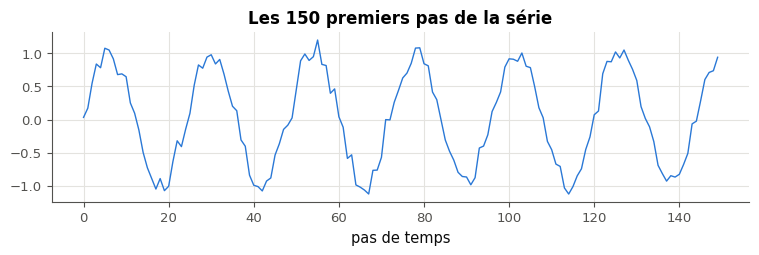

In [31]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor

T_14, WAVE_14 = wb.synth.noisy_sine(n=1200, freq=1 / 24, noise=0.1, t_max=1199, seed=2214)   # period: 24 steps
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.plot(T_14[:150], WAVE_14[:150], lw=1)
ax.set_xlabel("pas de temps")
ax.set_title("Les 150 premiers pas de la série")
plt.show()

In [32]:
shuffled_14, two_beats_14, c_vs_mean_14 = "C", True, False

In [33]:
wb.record("22.14a", "C", mistakes={"dans la variante 3, le réseau a les huit valeurs, mais sait-il si la série monte ou descend ?": "A", "compare la variante 3 à la persistance : combien de fois plus grande est son erreur ?": "B"})
wb.record("22.14b", True, mistakes={"deux valeurs dans l'ordre donnent la pente : la persistance, elle, n'en a qu'une": False})
wb.record("22.14c", False, mistakes={"compare l'erreur de la variante 3 à celle de la prédiction constante : est-elle beaucoup plus petite ?": True})

WB_ANSWER {"hash": "3a2ac47f73a9a18ac0583efdec5e263959aee5e8c6350f29ff3732aa7f605c40", "id": "22.14a", "kind": "str", "mistakes": {"1e0a422e18b96abe4ad7fe98be717145eb500279562eca78a58d28cbdc6f9d14": "dans la variante 3, le réseau a les huit valeurs, mais sait-il si la série monte ou descend ?", "a6364335e78af692d0d5a48f8f1f31114c775d23004ddfd43d855169f0b8f7bd": "compare la variante 3 à la persistance : combien de fois plus grande est son erreur ?"}}
📝 Ex 22.14a : réponse enregistrée (str).
WB_ANSWER {"hash": "55d75a77fe0b6fa3797f143abb8a12ae1c1e9e3c9168a385367bd376d7a7cc84", "id": "22.14b", "kind": "bool", "mistakes": {"ee6bf6940e3135d4e4f844e60e30f807b11dbacaab44448d4a441098a8993cb3": "deux valeurs dans l'ordre donnent la pente : la persistance, elle, n'en a qu'une"}}
📝 Ex 22.14b : réponse enregistrée (bool).
WB_ANSWER {"hash": "4544912793b90760034df3205be30b5bb2109629bc1d35c1360fe398c823d41d", "id": "22.14c", "kind": "bool", "mistakes": {"63999fca5d14a87c52790037237b33902e6df3083d9af

In [34]:
if any(answer is ... or answer is None for answer in [shuffled_14, two_beats_14, c_vs_mean_14]):
    print("⏳ Ex 22.14 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    ran_14 = False
    with checked("22.14"):
        X_14, y_14 = mylearn.sequences.make_windows(WAVE_14, 8)        # your make_windows: (N, 8, 1) and (N,)
        X_14, y_14 = np.asarray(X_14)[:, :, 0], np.asarray(y_14)
        N_TRAIN_14 = 900                                               # the first 900 windows train, the others test
        rng_14 = np.random.default_rng(14)
        variants_14 = {"1 · ordre naturel": X_14,
                       "2 · une même permutation pour toutes les fenêtres": X_14[:, rng_14.permutation(8)],
                       "3 · un ordre au hasard propre à chaque fenêtre": np.array([row[rng_14.permutation(8)] for row in X_14]),
                       "4 · seulement les deux dernières valeurs, dans l'ordre": X_14[:, -2:]}
        target_14 = y_14[N_TRAIN_14:]
        mse_14 = {"persistance (la dernière valeur)": np.mean((X_14[N_TRAIN_14:, -1] - target_14) ** 2),
                  "constante (la moyenne d'entraînement)": np.mean((y_14[:N_TRAIN_14].mean() - target_14) ** 2)}
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            for name_14, inputs_14 in variants_14.items():
                mlp_14 = MLPRegressor(hidden_layer_sizes=(32,), max_iter=3000, random_state=0)
                mlp_14.fit(inputs_14[:N_TRAIN_14], y_14[:N_TRAIN_14])
                mse_14[name_14] = np.mean((mlp_14.predict(inputs_14[N_TRAIN_14:]) - target_14) ** 2)
        for name_14, value_14 in mse_14.items():
            print(f"{name_14:55s} MSE de test {value_14:.4f}")
        ran_14 = True
    if ran_14:
        wb.check("22.14a", shuffled_14)
        wb.check("22.14b", two_beats_14)
        wb.check("22.14c", c_vs_mean_14)
    else:
        print("⏳ Ex 22.14 : tes prédictions se vérifient après l'expérience : écris d'abord make_windows (22.13).")

persistance (la dernière valeur)                        MSE de test 0.0528
constante (la moyenne d'entraînement)                   MSE de test 0.5109
1 · ordre naturel                                       MSE de test 0.0190
2 · une même permutation pour toutes les fenêtres       MSE de test 0.0167
3 · un ordre au hasard propre à chaque fenêtre          MSE de test 0.4484
4 · seulement les deux dernières valeurs, dans l'ordre  MSE de test 0.0385
✅ Ex 22.14a : Parfait !
✅ Ex 22.14b : Bravo !
✅ Ex 22.14c : Exact !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Que garde la variante 3 des huit valeurs, et que perd-elle ? Pourquoi deux valeurs dans l'ordre valent-elles mieux que huit valeurs en vrac ?

💡 Mélangées fenêtre par fenêtre, les huit valeurs disent à quelle hauteur se trouve la série, mais plus si elle monte ou si elle descend : deux tronçons symétriques du sinus donnent le même ensemble de valeurs et deux suites opposées. Le réseau ne peut que viser la moyenne des deux, et fait à peine mieux que la constante, environ huit fois et demie plus mal que la persistance. Avec seulement les deux dernières valeurs dans l'ordre, il connaît la pente et extrapole mieux que la persistance. Ce n'est pas le nombre de valeurs qui compte, c'est l'ordre : ce que la couche dense ne sait pas exploiter d'elle-même et que l'état d'un RNN porte naturellement.

## Partie B · Ta librairie rnn.py : RNN, LSTM et GRU contre PyTorch, et le gradient qui s'évanouit

Tu écris en NumPy les trois cellules du chapitre et leur boucle sur le temps (22.15 à 22.17), avec les conventions de PyTorch, pour pouvoir y copier ses poids et comparer au milliardième près ; tu mesures ce que coûte ta version face à `nn.LSTM` (22.18), puis, avec l'autograd de PyTorch, ce que devient le gradient qui remonte 80 pas (22.19).

### Ex 22.15 — rnn_cell_forward et rnn_forward 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire la cellule d'Elman et sa boucle sur le temps, avec les poids et le format de PyTorch.  
**Prérequis :** ✏️ 22.2 · Ex 22.13 · fiche §22.4, §22.4.1, §22.5 · **Fil rouge :** synthétique · **mylearn :** `rnn.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rnn.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_rnn.py -q` les lance tous dans un terminal.

**Contrat commun de `rnn.py`** (les docstrings, plus ces précisions que vérifient les tests) : les entrées peuvent être des listes et ne sont jamais modifiées ; les résultats sont de **nouveaux** tableaux `float64`, même pour des entrées entières ou `float32`, jamais une vue d'un autre résultat ; les poids sont dans la disposition de `mylearn`, `W_ih` de forme `(D, kH)` et `W_hh` de forme `(H, kH)` (les `weight_ih.T` et `weight_hh.T` de PyTorch, $k = 1$, 4 ou 3), avec des blocs de $H$ colonnes dans l'ordre de PyTorch ; un biais a la forme `(kH,)` exactement, et `None` vaut zéro ; `x_t` et les états sont 2-D avec le même nombre de lignes $N$, une séquence `x` est 3-D `(N, T, D)` avec $T \geq 1$. Tu vérifies toi-même les formes : celles que NumPy diffuserait sans erreur (un poids d'une seule colonne, un `x_t` d'une ligne face à un état de deux, un biais `(1,)`) lèvent aussi `ValueError`, comme la disposition de PyTorch.

Écris `rnn_cell_forward(x_t, h_prev, W_ih, W_hh, b_ih=None, b_hh=None, nonlinearity="tanh")` et `rnn_forward(x, W_ih, W_hh, b_ih=None, b_hh=None, h0=None, nonlinearity="tanh")`. **Contrat** propre à ces deux fonctions :
- la cellule calcule $h_t = f(x_t W_{ih} + b_{ih} + h_{t-1} W_{hh} + b_{hh})$, avec $f$ = tanh ou ReLU (`nonlinearity` vaut `"tanh"` ou `"relu"`, rien d'autre) ; elle rend `h_t`, de forme `(N, H)` ;
- `rnn_forward` applique la cellule à chaque pas de `x` `(N, T, D)`, en partant de `h0` (des zéros si `None`, sinon de forme `(N, H)`) ; elle rend `(outputs, h_T)` : `outputs` `(N, T, H)` empile les états, `h_T` `(N, H)` est le dernier, un tableau **à part** (pas une vue de `outputs`).

La première cellule copie les poids d'une `nn.RNN` (et d'une `nn.RNNCell` en ReLU), compare tes sorties aux siennes, et essaie deux refus ; la seconde lance les tests (`-k "test_rnn_cell_forward_ or test_rnn_forward_"`).

In [35]:
with checked("22.15"):
    R = mylearn.rnn
    torch.manual_seed(2215)
    torch_15 = nn.RNN(3, 4, batch_first=True).double()           # the oracle; its weights are copied with .T
    w_15 = numpy_weights(torch_15)
    x_15 = torch.randn(2, 6, 3, dtype=torch.float64)
    h0_15 = torch.randn(1, 2, 4, dtype=torch.float64)
    outputs_15, h_T_15 = pair("22.15", "rnn_forward", R.rnn_forward(
        x_15.numpy(), w_15["weight_ih_l0"].T, w_15["weight_hh_l0"].T, w_15["bias_ih_l0"], w_15["bias_hh_l0"],
        h0=h0_15[0].numpy()), names=("outputs", "h_T"))
    want_out_15, want_h_15 = torch_15(x_15, h0_15)
    same("22.15", "outputs de rnn_forward contre nn.RNN(batch_first=True), (N, T, H)", outputs_15, want_out_15.detach())
    same("22.15", "h_T contre h_n[0] de nn.RNN", h_T_15, want_h_15[0].detach())
    cell_15 = nn.RNNCell(3, 4, nonlinearity="relu").double()
    wc_15 = numpy_weights(cell_15)
    same("22.15", "rnn_cell_forward(..., nonlinearity='relu') contre nn.RNNCell",
         R.rnn_cell_forward(x_15[:, 0].numpy(), h0_15[0].numpy(), wc_15["weight_ih"].T, wc_15["weight_hh"].T,
                            wc_15["bias_ih"], wc_15["bias_hh"], nonlinearity="relu"),
         cell_15(x_15[:, 0], h0_15[0]).detach())
    refuses("22.15", "W_ih dans la disposition de PyTorch, (H, D) = (4, 3)",
            lambda: R.rnn_cell_forward(x_15[:, 0].numpy(), h0_15[0].numpy(), w_15["weight_ih_l0"], w_15["weight_hh_l0"].T))
    refuses("22.15", "nonlinearity='sigmoid'",
            lambda: R.rnn_cell_forward(np.ones((1, 3)), np.zeros((1, 4)), np.ones((3, 4)), np.ones((4, 4)), nonlinearity="sigmoid"))

✅ Ex 22.15 : outputs de rnn_forward contre nn.RNN(batch_first=True), (N, T, H) : un tableau (2, 6, 4), comme attendu.
✅ Ex 22.15 : h_T contre h_n[0] de nn.RNN : un tableau (2, 4), comme attendu.
✅ Ex 22.15 : rnn_cell_forward(..., nonlinearity='relu') contre nn.RNNCell : un tableau (2, 4), comme attendu.
✅ Ex 22.15 : W_ih dans la disposition de PyTorch, (H, D) = (4, 3) : ValueError levée (W_ih must have shape (D, 1H) = (3, 4), got (4, 3)).
✅ Ex 22.15 : nonlinearity='sigmoid' : ValueError levée (nonlinearity must be 'tanh' or 'relu', got 'sigmoid').


In [36]:
if written(lambda: mylearn.rnn.rnn_cell_forward([[1.0]], [[0.0]], [[1.0]], [[1.0]])):
    run_pytest_group(TEST_RNN, impl="ref", keyword="test_rnn_cell_forward_ or test_rnn_forward_")
else:
    print("⏳ Ex 22.15 : les tests attendent tes fonctions.")

pytest: 49 passed, 75 deselected in 1.36s


### Ex 22.16 — lstm_cell_forward et lstm_forward (portes i, f, g, o) 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire un pas de LSTM et sa boucle sur le temps, portes rangées comme dans PyTorch.  
**Prérequis :** Ex 22.15 · ✏️ 22.4 · fiche §22.7.1, §22.7.2 · **Fil rouge :** synthétique · **mylearn :** `rnn.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rnn.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_rnn.py -q` les lance tous dans un terminal.

**Contrat commun de `rnn.py`** (les docstrings, plus ces précisions que vérifient les tests) : les entrées peuvent être des listes et ne sont jamais modifiées ; les résultats sont de **nouveaux** tableaux `float64`, même pour des entrées entières ou `float32`, jamais une vue d'un autre résultat ; les poids sont dans la disposition de `mylearn`, `W_ih` de forme `(D, kH)` et `W_hh` de forme `(H, kH)` (les `weight_ih.T` et `weight_hh.T` de PyTorch, $k = 1$, 4 ou 3), avec des blocs de $H$ colonnes dans l'ordre de PyTorch ; un biais a la forme `(kH,)` exactement, et `None` vaut zéro ; `x_t` et les états sont 2-D avec le même nombre de lignes $N$, une séquence `x` est 3-D `(N, T, D)` avec $T \geq 1$. Tu vérifies toi-même les formes : celles que NumPy diffuserait sans erreur (un poids d'une seule colonne, un `x_t` d'une ligne face à un état de deux, un biais `(1,)`) lèvent aussi `ValueError`, comme la disposition de PyTorch.

Écris `lstm_cell_forward(x_t, h_prev, c_prev, W_ih, W_hh, b_ih=None, b_hh=None)` et `lstm_forward(x, W_ih, W_hh, b_ih=None, b_hh=None, h0=None, c0=None)`. **Contrat** :
- `W_ih` a la forme `(D, 4H)` et `W_hh` la forme `(H, 4H)`, leurs colonnes en quatre blocs de $H$ dans l'ordre $i, f, g, o$ ; $i, f, o$ passent par une sigmoïde, $g$ par une tanh ; $c_t = f \odot c_{t-1} + i \odot g$ et $h_t = o \odot \tanh(c_t)$ (fiche §22.7.2) ;
- ta sigmoïde est **stable** : des pré-activations de ±1 000 ne déclenchent aucun `RuntimeWarning` ;
- `lstm_cell_forward` rend le couple `(h_t, c_t)`, dans cet ordre ; `c_prev` a la forme de `h_prev` ;
- `lstm_forward` part de `h0` et `c0` (des zéros si `None`) et rend `(outputs, (h_T, c_T))`, comme `nn.LSTM` : la paire finale est un **tuple**, et `h_T`, `c_T` sont des tableaux à part.

La première cellule copie les poids d'une `nn.LSTM` et d'une `nn.LSTMCell` et compare tes résultats, puis essaie un refus ; la seconde lance les tests (`-k "test_lstm_cell_forward_ or test_lstm_forward_"`).

Dans tes notes : écris l'expression de `outputs[:, -1]` en fonction de `h_T`. Que deviendrait ta cellule si l'on oubliait la tanh de $h_t$ ?

In [37]:
with checked("22.16"):
    R = mylearn.rnn
    torch.manual_seed(2216)
    torch_16 = nn.LSTM(3, 5, batch_first=True).double()
    w_16 = numpy_weights(torch_16)
    x_16 = torch.randn(2, 7, 3, dtype=torch.float64)
    h0_16, c0_16 = torch.randn(1, 2, 5, dtype=torch.float64), torch.randn(1, 2, 5, dtype=torch.float64)
    result_16 = R.lstm_forward(x_16.numpy(), w_16["weight_ih_l0"].T, w_16["weight_hh_l0"].T, w_16["bias_ih_l0"],
                               w_16["bias_hh_l0"], h0=h0_16[0].numpy(), c0=c0_16[0].numpy())
    outputs_16, final_16 = pair("22.16", "lstm_forward", result_16, names=("outputs", "(h_T, c_T)"))
    verdict("22.16", isinstance(final_16, tuple), "le second élément de lstm_forward est un tuple (h_T, c_T), comme nn.LSTM.",
            f"le second élément de lstm_forward doit être le tuple (h_T, c_T), reçu un {type(final_16).__name__}.")
    h_T_16, c_T_16 = pair("22.16", "le second élément de lstm_forward", final_16, names=("h_T", "c_T"))
    want_out_16, (want_h_16, want_c_16) = torch_16(x_16, (h0_16, c0_16))
    same("22.16", "outputs de lstm_forward contre nn.LSTM(batch_first=True)", outputs_16, want_out_16.detach())
    same("22.16", "h_T contre h_n[0]", h_T_16, want_h_16[0].detach())
    same("22.16", "c_T contre c_n[0]", c_T_16, want_c_16[0].detach())
    cell_16 = nn.LSTMCell(3, 5).double()
    wc_16 = numpy_weights(cell_16)
    h_t_16, c_t_16 = pair("22.16", "lstm_cell_forward", R.lstm_cell_forward(
        x_16[:, 0].numpy(), h0_16[0].numpy(), c0_16[0].numpy(), wc_16["weight_ih"].T, wc_16["weight_hh"].T,
        wc_16["bias_ih"], wc_16["bias_hh"]), names=("h_t", "c_t"))
    want_ht_16, want_ct_16 = cell_16(x_16[:, 0], (h0_16[0], c0_16[0]))
    same("22.16", "h_t de lstm_cell_forward contre nn.LSTMCell", h_t_16, want_ht_16.detach())
    same("22.16", "c_t de lstm_cell_forward contre nn.LSTMCell", c_t_16, want_ct_16.detach())
    refuses("22.16", "W_ih avec 3H colonnes au lieu de 4H",
            lambda: R.lstm_cell_forward(np.ones((1, 3)), np.zeros((1, 5)), np.zeros((1, 5)), np.ones((3, 15)), np.ones((5, 20))))

✅ Ex 22.16 : le second élément de lstm_forward est un tuple (h_T, c_T), comme nn.LSTM.
✅ Ex 22.16 : outputs de lstm_forward contre nn.LSTM(batch_first=True) : un tableau (2, 7, 5), comme attendu.
✅ Ex 22.16 : h_T contre h_n[0] : un tableau (2, 5), comme attendu.
✅ Ex 22.16 : c_T contre c_n[0] : un tableau (2, 5), comme attendu.
✅ Ex 22.16 : h_t de lstm_cell_forward contre nn.LSTMCell : un tableau (2, 5), comme attendu.
✅ Ex 22.16 : c_t de lstm_cell_forward contre nn.LSTMCell : un tableau (2, 5), comme attendu.
✅ Ex 22.16 : W_ih avec 3H colonnes au lieu de 4H : ValueError levée (W_ih must have shape (D, 4H) = (3, 20), got (3, 15)).


In [38]:
if written(lambda: mylearn.rnn.lstm_cell_forward([[1.0]], [[0.0]], [[0.0]], np.ones((1, 4)), np.ones((1, 4)))):
    run_pytest_group(TEST_RNN, impl="ref", keyword="test_lstm_cell_forward_ or test_lstm_forward_")
else:
    print("⏳ Ex 22.16 : les tests attendent tes fonctions.")

pytest: 50 passed, 74 deselected in 1.29s


### Ex 22.17 — gru_cell_forward (portes r, z, n) 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire un pas de GRU dans la convention de PyTorch, où la porte de réinitialisation agit après $W_{hn}$.  
**Prérequis :** Ex 22.16 · fiche §22.7.2 (le GRU) · **Fil rouge :** synthétique · **mylearn :** `rnn.py` · **Parcours :** C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rnn.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_rnn.py -q` les lance tous dans un terminal.

**Contrat commun de `rnn.py`** (les docstrings, plus ces précisions que vérifient les tests) : les entrées peuvent être des listes et ne sont jamais modifiées ; les résultats sont de **nouveaux** tableaux `float64`, même pour des entrées entières ou `float32`, jamais une vue d'un autre résultat ; les poids sont dans la disposition de `mylearn`, `W_ih` de forme `(D, kH)` et `W_hh` de forme `(H, kH)` (les `weight_ih.T` et `weight_hh.T` de PyTorch, $k = 1$, 4 ou 3), avec des blocs de $H$ colonnes dans l'ordre de PyTorch ; un biais a la forme `(kH,)` exactement, et `None` vaut zéro ; `x_t` et les états sont 2-D avec le même nombre de lignes $N$, une séquence `x` est 3-D `(N, T, D)` avec $T \geq 1$. Tu vérifies toi-même les formes : celles que NumPy diffuserait sans erreur (un poids d'une seule colonne, un `x_t` d'une ligne face à un état de deux, un biais `(1,)`) lèvent aussi `ValueError`, comme la disposition de PyTorch.

Écris `gru_cell_forward(x_t, h_prev, W_ih, W_hh, b_ih=None, b_hh=None)`. **Contrat** :
- `W_ih` `(D, 3H)` et `W_hh` `(H, 3H)` ont trois blocs de $H$ colonnes dans l'ordre $r, z, n$ ;
- $r$ et $z$ sont des sigmoïdes de la somme des deux contributions ; le candidat est $n = \tanh\big(x_t W_{in} + b_{in} + r \odot (h_{t-1} W_{hn} + b_{hn})\big)$ : la porte $r$ multiplie **aussi** $b_{hn}$, c'est pourquoi les deux biais ne se fusionnent pas ;
- elle rend $h_t = (1 - z) \odot n + z \odot h_{t-1}$, de forme `(N, H)`.

La première cellule compare ta cellule à `nn.GRUCell`, puis à un cas où seul $b_{hn}$ est non nul (la porte $r$ vaut 0,5 et doit le multiplier), et essaie un refus ; la seconde lance les tests (`-k "test_gru_cell_forward_"`).

In [39]:
with checked("22.17"):
    R = mylearn.rnn
    torch.manual_seed(2217)
    cell_17 = nn.GRUCell(3, 4).double()
    wc_17 = numpy_weights(cell_17)
    x_17 = torch.randn(5, 3, dtype=torch.float64)
    h_17 = torch.randn(5, 4, dtype=torch.float64)
    got_17 = R.gru_cell_forward(x_17.numpy(), h_17.numpy(), wc_17["weight_ih"].T, wc_17["weight_hh"].T,
                                wc_17["bias_ih"], wc_17["bias_hh"])
    same("22.17", "gru_cell_forward contre nn.GRUCell", got_17, cell_17(x_17, h_17).detach())
    big_17 = np.zeros(12)
    big_17[8:] = 3.0                                   # b_hh only on the n block: r multiplies it
    same("22.17", "gru_cell_forward avec un b_hh non nul sur le bloc n seulement",
         R.gru_cell_forward(np.zeros((1, 3)), np.ones((1, 4)), np.zeros((3, 12)), np.zeros((4, 12)), None, big_17),
         np.full((1, 4), 0.5 * np.tanh(0.5 * 3.0) + 0.5))
    refuses("22.17", "W_hh de forme (4, 16) : un GRU a 3H colonnes",
            lambda: R.gru_cell_forward(np.ones((1, 3)), np.zeros((1, 4)), np.ones((3, 12)), np.ones((4, 16))))

✅ Ex 22.17 : gru_cell_forward contre nn.GRUCell : un tableau (5, 4), comme attendu.
✅ Ex 22.17 : gru_cell_forward avec un b_hh non nul sur le bloc n seulement : [[0.95257413, 0.95257413, 0.95257413, 0.95257413]], comme attendu.
✅ Ex 22.17 : W_hh de forme (4, 16) : un GRU a 3H colonnes : ValueError levée (W_hh must have shape (H, 3H) = (4, 12), got (4, 16)).


In [40]:
if written(lambda: mylearn.rnn.gru_cell_forward([[1.0]], [[0.0]], np.ones((1, 3)), np.ones((1, 3)))):
    run_pytest_group(TEST_RNN, impl="ref", keyword="test_gru_cell_forward_")
else:
    print("⏳ Ex 22.17 : les tests attendent ta fonction.")

pytest: 25 passed, 99 deselected in 1.21s


### Ex 22.18 — Benchmark : ta cellule NumPy contre nn.LSTM 🛠️ ★★ ⏱️ 20 min
**Objectif :** mesurer proprement le temps d'une fonction (chauffe, plusieurs mesures, la plus courte) et comparer ta `lstm_forward` à celle de PyTorch.  
**Prérequis :** Ex 22.16 · ch. 0B (ordre des produits, mesure du temps) · fiche §22.7.2 · **Fil rouge :** synthétique · **Parcours :** C

Mesurer un temps d'exécution est une compétence de métier : une seule mesure ne veut rien dire (le premier appel paie l'allocation de la mémoire et les caches, et le système d'exploitation peut interrompre n'importe quel appel). La méthode courante, celle du module `timeit` de Python : un appel de chauffe, puis plusieurs mesures, et l'on garde la **plus courte**, la moins perturbée.

**Contrat**
- `best_time_18(fn, *args, repeat=5)` appelle `fn(*args)` une fois sans le mesurer, puis `repeat` fois en mesurant chaque appel avec `time.perf_counter()` ; elle rend la plus courte de ces `repeat` durées, en secondes (un `float` Python).

La vérification essaie ta fonction sur un faux calcul aux durées connues, compare ta `lstm_forward` (22.16) à `nn.LSTM` sur les entrées du benchmark (32 séquences de 100 pas, $D = 32$, $H = 64$, en `float64`), puis mesure les deux et affiche leur rapport.

Dans tes notes : quel est le rapport entre le temps de ta version et celui de `nn.LSTM` sur ta machine ? Lance la cellule deux fois : le rapport bouge-t-il ? Où passe le temps dans ta boucle (pense au nombre de produits matriciels par pas, et à ce que fait l'interpréteur Python entre deux) ? Pourquoi garde-t-on la plus courte des mesures plutôt que leur moyenne ?

In [41]:
def best_time_18(fn, *args, repeat=5):
    """Call fn(*args) once to warm up, then `repeat` more times, each one timed with time.perf_counter.
    Return the shortest of these `repeat` durations, in seconds (a Python float)."""
    fn(*args)                                       # warm-up: caches, memory allocation, lazy initialisation
    durations = []
    for _ in range(repeat):
        start = time.perf_counter()
        fn(*args)
        durations.append(time.perf_counter() - start)
    return float(min(durations))                    # the least disturbed run: the others only add noise


bench_18 = None
with checked("22.18"):
    sleeps_18 = iter([0.03, 0.02, 0.01, 0.025, 0.015, 0.02, 0.05, 0.05])
    calls_18 = []

    def fake_18(x):
        calls_18.append(x)
        time.sleep(next(sleeps_18))

    best_18 = best_time_18(fake_18, "x", repeat=5)
    if returned("22.18", "best_time_18", best_18):
        verdict("22.18", len(calls_18) == 6, "best_time_18 appelle la fonction 6 fois : une de chauffe, puis 5 mesures.",
                f"best_time_18(fn, x, repeat=5) a appelé fn {len(calls_18)} fois : attendu 6 (une de chauffe, puis repeat).")
        verdict("22.18", isinstance(best_18, float) and 0.009 <= best_18 < 0.0145,
                "best_time_18 rend la plus courte des 5 durées mesurées, un float Python.",
                f"best_time_18 rend {best_18!r} pour des durées de 0,020, 0,010, 0,025, 0,015 et 0,020 s après une chauffe de "
                "0,030 s : attendu la plus courte des mesures, en float Python.")
        R = mylearn.rnn
        torch.manual_seed(2218)
        lstm_18 = nn.LSTM(32, 64, batch_first=True).double()
        w_18 = numpy_weights(lstm_18)
        x_18 = torch.randn(32, 100, 32, dtype=torch.float64)
        args_18 = (x_18.numpy(), w_18["weight_ih_l0"].T, w_18["weight_hh_l0"].T, w_18["bias_ih_l0"], w_18["bias_hh_l0"])
        with torch.no_grad():
            same("22.18", "ta lstm_forward contre nn.LSTM sur les entrées du benchmark", R.lstm_forward(*args_18)[0],
                 lstm_18(x_18)[0])
            t_numpy_18 = best_time_18(R.lstm_forward, *args_18, repeat=5)
            t_torch_18 = best_time_18(lstm_18, x_18, repeat=5)
        bench_18 = (t_numpy_18, t_torch_18)
        print(f"lstm_forward (NumPy) : {t_numpy_18 * 1e3:.1f} ms · nn.LSTM : {t_torch_18 * 1e3:.1f} ms · "
              f"rapport {t_numpy_18 / t_torch_18:.1f} (N = 32, T = 100, D = 32, H = 64, float64)")

✅ Ex 22.18 : best_time_18 appelle la fonction 6 fois : une de chauffe, puis 5 mesures.
✅ Ex 22.18 : best_time_18 rend la plus courte des 5 durées mesurées, un float Python.


✅ Ex 22.18 : ta lstm_forward contre nn.LSTM sur les entrées du benchmark : un tableau (32, 100, 64), comme attendu.


lstm_forward (NumPy) : 26.9 ms · nn.LSTM : 10.5 ms · rapport 2.6 (N = 32, T = 100, D = 32, H = 64, float64)


💡 Sur deux cœurs, `nn.LSTM` est en général plusieurs fois plus rapide que la boucle NumPy : PyTorch calcule les quatre portes en un seul produit matriciel par pas, comme toi, mais dans une boucle compilée en C++ qui évite de passer par l'interpréteur et d'allouer de nouveaux tableaux à chaque pas ; sur GPU, cuDNN va plus loin en calculant d'un coup les produits $x_t W_{ih}$ de tous les pas, qui ne dépendent pas de l'état. Le rapport varie d'une exécution à l'autre et d'une machine à l'autre : on le donne en ordre de grandeur. La plus courte mesure est la meilleure estimation du coût du calcul lui-même : les autres y ajoutent des interruptions, jamais l'inverse.

### Ex 22.19 — Mesurer la disparition du gradient : RNN tanh contre LSTM 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer avec l'autograd la norme du gradient par rapport à chaque entrée, et la comparer d'une cellule et d'une initialisation à l'autre.  
**Prérequis :** Ex 22.15 · ∂ 22.6 · ∂ 22.7 · ch. 20 (autograd) · fiche §22.6, §22.7.2 · **Fil rouge :** synthétique · **Parcours :** M, C

∂ 22.6 et ∂ 22.7 ont montré sur le papier que le gradient qui remonte le temps est un produit de facteurs. Ici, tu le mesures. On prend la somme des sorties du **dernier** pas, $L = \sum$ `output[:, -1]`, et l'on regarde, pour chaque pas $t$, la taille du gradient de $L$ par rapport à l'entrée de ce pas.

**Contrat**
- `input_grad_norms_19(model, x)` reçoit un module récurrent batch-first de PyTorch (`nn.RNN`, `nn.LSTM` ou `nn.GRU`, qui rend `(output, état)`) et des entrées `x` de forme `(N, T, D)` ; elle rend un tableau NumPy de forme `(T,)` : pour chaque pas $t$, la norme de $\partial L / \partial x[:, t, :]$, prise sur toute la tranche (tous les exemples et toutes les features) ;
- elle ne modifie pas `x` (pas de `requires_grad` ni de `.grad` laissé sur lui).

La vérification compare ta fonction à la jacobienne calculée par `torch.autograd.functional.jacobian` sur un petit RNN. L'expérience la lance ensuite sur quatre réseaux **non entraînés**, à 80 pas et 32 valeurs d'état : un RNN tanh avec l'initialisation par défaut de PyTorch, le même avec $W_{hh}$ orthogonale (toutes ses valeurs singulières valent 1), un LSTM par défaut et le même LSTM avec un biais d'oubli de 1. Elle trace $\log_{10}$ du rapport entre la norme à la distance $T - t$ et celle du dernier pas.

Dans tes notes : à quelle distance le gradient du RNN par défaut a-t-il perdu un facteur $10^{6}$ ? Le LSTM par défaut fait-il beaucoup mieux, et pourquoi (que vaut $f$ au départ, fiche §22.7.2) ? Que change le biais d'oubli ? L'initialisation orthogonale règle-t-elle le problème pour de bon, une fois l'entraînement lancé (pense à ce que deviennent les valeurs singulières et à la saturation) ?

In [42]:
def input_grad_norms_19(model, x):
    """For a batch-first recurrent module (nn.RNN, nn.LSTM or nn.GRU) and inputs x of shape (N, T, D), return the
    T norms ||dL/dx_t||, a NumPy array of shape (T,), where L = output[:, -1].sum() is the sum of the outputs of the
    last step and the norm of step t is taken over the whole slice dL/dx[:, t, :]. x itself is left unchanged."""
    inputs = x.detach().clone().requires_grad_(True)      # a leaf of its own: x keeps no gradient
    output, _ = model(inputs)
    output[:, -1].sum().backward()
    return inputs.grad.norm(dim=(0, 2)).numpy()           # one norm per time step, over the batch and the features


grads_ok_19 = False
with checked("22.19"):
    torch.manual_seed(2219)
    small_19 = nn.RNN(3, 4, batch_first=True)
    x_small_19 = torch.randn(2, 5, 3)
    jacobian_19 = torch.autograd.functional.jacobian(lambda inputs: small_19(inputs)[0][:, -1].sum(), x_small_19)
    got_19 = input_grad_norms_19(small_19, x_small_19)
    if returned("22.19", "input_grad_norms_19", got_19):
        grads_ok_19 = same("22.19", "input_grad_norms_19 contre la jacobienne de PyTorch (5 pas)", got_19,
                           jacobian_19.norm(dim=(0, 2)), rtol=1e-5, atol=1e-8)
        verdict("22.19", not x_small_19.requires_grad and x_small_19.grad is None,
                "x n'a pas été modifié (ni requires_grad, ni gradient).",
                "input_grad_norms_19 a modifié x (requires_grad ou .grad) : travaille sur une copie détachée.")

✅ Ex 22.19 : input_grad_norms_19 contre la jacobienne de PyTorch (5 pas) : [0.0106853, 0.04710326, 0.17635615, 0.39107698, 0.72993451], comme attendu.
✅ Ex 22.19 : x n'a pas été modifié (ni requires_grad, ni gradient).


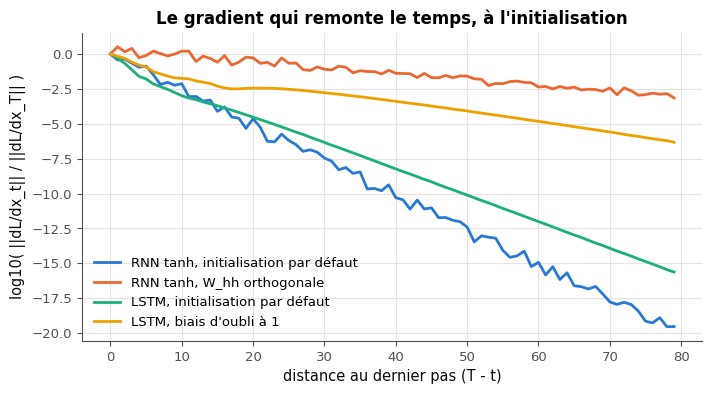

RNN tanh, initialisation par défaut    distance 10 :   -2.1 · distance 40 :  -10.3 · distance 79 :  -19.5
RNN tanh, W_hh orthogonale             distance 10 :    0.2 · distance 40 :   -1.4 · distance 79 :   -3.1
LSTM, initialisation par défaut        distance 10 :   -3.0 · distance 40 :   -8.2 · distance 79 :  -15.6
LSTM, biais d'oubli à 1                distance 10 :   -1.7 · distance 40 :   -3.4 · distance 79 :   -6.3


In [43]:
if not grads_ok_19:
    print("⏳ Ex 22.19 : l'expérience attend une input_grad_norms_19 juste.")
else:
    T_19, H_19 = 80, 32
    torch.manual_seed(2219)
    x_19 = torch.randn(16, T_19, 1)
    rnn_19 = nn.RNN(1, H_19, batch_first=True)
    rnn_orth_19 = nn.RNN(1, H_19, batch_first=True)
    nn.init.orthogonal_(rnn_orth_19.weight_hh_l0)                  # every singular value of W_hh equals 1
    lstm_19 = nn.LSTM(1, H_19, batch_first=True)
    lstm_open_19 = nn.LSTM(1, H_19, batch_first=True)
    lstm_open_19.load_state_dict(lstm_19.state_dict())
    with torch.no_grad():
        lstm_open_19.bias_ih_l0[H_19:2 * H_19] = 1.0               # forget gate bias: 1 in total (fiche §22.7.2)
        lstm_open_19.bias_hh_l0[H_19:2 * H_19] = 0.0
    curves_19 = {"RNN tanh, initialisation par défaut": rnn_19, "RNN tanh, W_hh orthogonale": rnn_orth_19,
                 "LSTM, initialisation par défaut": lstm_19, "LSTM, biais d'oubli à 1": lstm_open_19}
    fig, ax = plt.subplots(figsize=(8, 4))
    decay_19 = {}
    for name_19, model_19 in curves_19.items():
        norms_19 = np.asarray(input_grad_norms_19(model_19, x_19))[::-1]      # distance 0 = the last step
        decay_19[name_19] = np.log10(norms_19 / norms_19[0])
        ax.plot(decay_19[name_19], label=name_19)
    ax.set_xlabel("distance au dernier pas (T - t)")
    ax.set_ylabel("log10( ||dL/dx_t|| / ||dL/dx_T|| )")
    ax.set_title("Le gradient qui remonte le temps, à l'initialisation")
    ax.legend()
    plt.show()
    for name_19, curve_19 in decay_19.items():
        print(f"{name_19:38s} distance 10 : {curve_19[10]:6.1f} · distance 40 : {curve_19[40]:6.1f} · distance 79 : {curve_19[79]:6.1f}")

💡 À l'initialisation, le RNN par défaut perd un facteur 10 environ tous les 4 pas : $10^{-10}$ à 40 pas. Le LSTM par défaut ne fait guère mieux, car ses portes d'oubli valent environ $\sigma(0) = 0{,}5$ : son chemin additif divise le gradient par deux à chaque pas ($0{,}5^{40} \approx 10^{-12}$ sur ce seul chemin). Avec un biais d'oubli de 1, $f \approx 0{,}73$ et la pente devient bien plus douce. Le RNN à $W_{hh}$ orthogonale garde le gradient le plus longtemps, mais seulement au départ : l'entraînement déplace les valeurs singulières et peut saturer la tanh, alors que les portes du LSTM apprennent à rester ouvertes. Les nombres exacts dépendent du tirage des poids (graine 2219).

## Partie C · Échantillonner, valider une série sans fuite, empiler les couches, prévoir les taches solaires

Tu termines `sequences.py` avec la température et l'échantillonnage (22.20) ; tu répares une prévision trop belle pour être vraie (22.21) ; tu lis les formes que rendent les RNN profonds et bidirectionnels de PyTorch (22.22) ; tu prévois les taches solaires à 6 mois avec un LSTM, face à la persistance (22.23) ; puis tu prédis l'allure d'un texte selon sa température (22.24).

### Ex 22.20 — temperature_softmax et sample_from_logits 🔨 ★★ ⏱️ 25 min
**Objectif :** diviser des logits par une température et tirer le token suivant, avec ou sans top-k.  
**Prérequis :** ✏️ 22.5 · Ex 22.12 · fiche §22.9 · **Fil rouge :** Holmes · **mylearn :** `sequences.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/sequences.py` (créé par `python tools/start_chapter.py 22`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch22_sequences.py -q` les lance tous dans un terminal.

**Contrat commun de `sequences.py`** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux et ne modifient **jamais** leurs entrées ; un argument « entier » refuse un `bool` (`True` n'est pas un nombre de pas) et toute valeur < 1, avec `ValueError`.

Écris `temperature_softmax(logits, temperature=1.0)` et `sample_from_logits(logits, temperature=1.0, top_k=None, rng=None)`. **Contrat** :
- `temperature_softmax` calcule $\mathrm{softmax}(z / T)$ le long du **dernier** axe (forme gardée), de façon stable : des logits de ±1 000 ne déclenchent aucun `RuntimeWarning` (on retire le maximum de **chaque ligne**) ; $T \leq 0$ lève `ValueError` ; elle rend un **nouveau** tableau NumPy `float64` de la forme des logits ;
- `sample_from_logits` rend un `int` Python pour des logits `(V,)`, un tableau `int64` `(N,)` pour des logits `(N, V)`, chaque ligne étant tirée **indépendamment** ; avec `temperature=0`, aucun hasard : le **premier** indice du maximum ; avec `top_k`, les logits strictement plus petits que le $k$-ième plus grand sont retirés avant de tirer, ligne par ligne (les ex aequo du $k$-ième restent, et `top_k = V` garde tout) ; `temperature < 0`, ou un `top_k` qui n'est pas un entier de $[1, V]$, lève `ValueError` ;
- le tirage utilise `rng` (un `np.random.Generator`) et lui seul : la même graine redonne les mêmes ids ; `rng=None` crée un nouveau générateur, sans graine fixe. La façon de tirer (CDF inverse, `rng.choice`…) est libre : les tests ne regardent que les fréquences.

La première cellule compare ta softmax à celle de SciPy, essaie le cas glouton, les fréquences de 20 000 tirages, le top-k avec ex aequo, la reproductibilité et trois refus ; la seconde lance les tests (`-k "test_temperature_softmax_ or test_sample_from_logits_"`).

In [44]:
with checked("22.20"):
    S = mylearn.sequences
    logits_20 = np.array([[2.0, 1.0, 0.1, -1.0], [1000.0, 999.0, 0.0, -1000.0]])
    with warnings.catch_warnings():
        warnings.simplefilter("error", RuntimeWarning)          # an overflow becomes an error, shown as ❌
        probs_20 = S.temperature_softmax(logits_20.copy(), temperature=0.5)   # a copy: the expected values use logits_20
    same("22.20", "temperature_softmax(logits, 0.5) contre scipy.special.softmax(logits / 0.5, axis=-1), lignes de ±1 000 comprises",
         probs_20, softmax(logits_20 / 0.5, axis=-1))
    greedy_20 = S.sample_from_logits([0.0, 3.0, 3.0, 1.0], temperature=0)
    verdict("22.20", type(greedy_20) is int and greedy_20 == 1,
            "temperature=0 : le premier argmax, un int Python.",
            f"sample_from_logits([0, 3, 3, 1], temperature=0) rend {greedy_20!r} : attendu le PREMIER indice du maximum, en int Python.")
    draws_20 = np.asarray(S.sample_from_logits(np.tile([0.0, 1.0, 2.0], (20000, 1)), rng=np.random.default_rng(20)))
    freq_20 = np.bincount(draws_20.astype(int), minlength=3)[:3] / draws_20.size if draws_20.shape == (20000,) else None
    want_20 = softmax([0.0, 1.0, 2.0])
    verdict("22.20", freq_20 is not None and np.abs(freq_20 - want_20).max() < 0.015,
            "20 000 tirages (une ligne par tirage) suivent softmax([0, 1, 2]) à 0,015 près.",
            f"20 000 lignes de logits [0, 1, 2] : attendu un tableau (20000,) dont les fréquences valent environ "
            f"{np.round(want_20, 3).tolist()}" + ("" if freq_20 is None else f", reçu {np.round(freq_20, 3).tolist()}") + ".")
    top_20 = np.asarray(S.sample_from_logits(np.tile([0.0, 2.0, 1.0, 1.0], (2000, 1)), top_k=2, rng=np.random.default_rng(21)))
    verdict("22.20", set(np.unique(top_20).tolist()) == {1, 2, 3},
            "top_k=2 garde les deux plus grands logits et les ex aequo du deuxième (ids 1, 2 et 3).",
            f"top_k=2 sur [0, 2, 1, 1] : attendu les ids {{1, 2, 3}} (les ex aequo du k-ième logit restent), reçu {sorted(set(np.unique(top_20).tolist()))}.")
    again_20 = [S.sample_from_logits([0.0, 0.5, 1.0], rng=np.random.default_rng(7)) for _ in range(2)]
    verdict("22.20", again_20[0] == again_20[1], "la même graine redonne le même id.",
            "deux générateurs de même graine doivent donner le même id : tire avec le rng reçu, rien d'autre.")
    refuses("22.20", "temperature=-1", lambda: S.sample_from_logits([0.0, 1.0], temperature=-1))
    refuses("22.20", "top_k=0", lambda: S.sample_from_logits([0.0, 1.0], top_k=0))
    refuses("22.20", "temperature_softmax(..., temperature=0)", lambda: S.temperature_softmax([0.0, 1.0], temperature=0))

✅ Ex 22.20 : temperature_softmax(logits, 0.5) contre scipy.special.softmax(logits / 0.5, axis=-1), lignes de ±1 000 comprises : un tableau (2, 4), comme attendu.
✅ Ex 22.20 : temperature=0 : le premier argmax, un int Python.
✅ Ex 22.20 : 20 000 tirages (une ligne par tirage) suivent softmax([0, 1, 2]) à 0,015 près.
✅ Ex 22.20 : top_k=2 garde les deux plus grands logits et les ex aequo du deuxième (ids 1, 2 et 3).
✅ Ex 22.20 : la même graine redonne le même id.
✅ Ex 22.20 : temperature=-1 : ValueError levée (temperature must be >= 0, got -1).
✅ Ex 22.20 : top_k=0 : ValueError levée (top_k must be >= 1, got 0).
✅ Ex 22.20 : temperature_softmax(..., temperature=0) : ValueError levée (temperature must be > 0, got 0).


In [45]:
if written(lambda: mylearn.sequences.temperature_softmax([0.0, 1.0])):
    run_pytest_group(TEST_SEQ, impl="ref", keyword="test_temperature_softmax_ or test_sample_from_logits_")
else:
    print("⏳ Ex 22.20 : les tests attendent tes fonctions.")

pytest: 46 passed, 71 deselected in 3.55s


### Ex 22.21 — Série temporelle piégée : fuite, mélange et batch_first 🐛 ★★ ⏱️ 25 min
**Objectif :** réparer une prévision de série temporelle dont le score de test est trop beau, en suivant la règle des fenêtres de la fiche.  
**Prérequis :** Ex 22.13 · ch. 8 (découpage) · ch. 12 (min-max) · 22.R3 · fiche §22.5, section « Au-delà du livre : prévoir une série temporelle » · **Fil rouge :** taches solaires · **Parcours :** R, C

Un collègue prévoit les taches solaires à 6 mois à partir des 24 derniers mois, avec un petit LSTM. Ses 240 derniers mois de cibles servent de test, et il annonce un résultat spectaculaire. Sa fonction `prepare_21` et sa classe `Forecaster21` contiennent **quatre** bugs : trois fuites de données et un mauvais ordre des axes. Corrige-les **sur place**, dans la cellule, sans changer leurs signatures, la taille de fenêtre, l'horizon ni l'architecture.

Le contrat que la version corrigée doit tenir (fiche, « Au-delà du livre », règles 2 et 3) : la cible de chaque fenêtre est la valeur `horizon` mois **après** sa dernière valeur ; les `n_test` dernières cibles sont le test, et le découpage suit le temps (aucun mélange) : une fenêtre de test peut lire la fin de la période d'entraînement, mais aucune fenêtre d'entraînement ne touche une cible de test ; le min-max s'ajuste sur la période d'entraînement, c'est-à-dire tout ce qui précède les `n_test` dernières valeurs ; le LSTM reçoit des fenêtres `(N, T, 1)`.

La vérification entraîne d'abord le pipeline actuel et affiche ses erreurs (le symptôme), puis donne quatre diagnostics, chacun sur une rampe (0, 1, 2…, 399) ou un mini-batch choisis pour qu'on lise d'où vient chaque nombre ; tant qu'un point échoue, les suivants attendent (⏳). Elle s'exécute dès le premier « Tout exécuter » : les diagnostics du code fautif sont ton point de départ.

Dans tes notes : quel bug produit, à lui seul, une persistance d'erreur nulle ? Aucun ne lève d'erreur : lesquels se voient dans les scores affichés, et lesquels seulement dans les diagnostics ? Une fois tout corrigé, le LSTM bat-il encore la persistance ?

In [46]:
def prepare_21(series, window=24, horizon=6, n_test=240):
    """Scaled windows to forecast `horizon` months ahead from `window` months; the last `n_test` targets are the test.
    Return X_train, y_train, X_test, y_test (float32 tensors, X of shape (N, window, 1)) and (lo, hi), the min-max scaler."""
    lo, hi = series[:-n_test].min(), series[:-n_test].max()     # 3. the scaler sees the training period only
    scaled = (series - lo) / (hi - lo)
    blocks = np.lib.stride_tricks.sliding_window_view(scaled, window + horizon)
    X = blocks[:, :window]                                       # 1. the first `window` values: the target stays outside
    y = blocks[:, -1]
    cut = len(y) - n_test                                        # 2. a cut in time, no shuffling
    X_train, X_test, y_train, y_test = X[:cut], X[cut:], y[:cut], y[cut:]
    to_tensor = lambda a: torch.tensor(np.ascontiguousarray(a), dtype=torch.float32)
    return to_tensor(X_train)[..., None], to_tensor(y_train), to_tensor(X_test)[..., None], to_tensor(y_test), (lo, hi)


class Forecaster21(nn.Module):
    """An LSTM that reads a window (N, T, 1) and predicts one value per window (N,)."""

    def __init__(self, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_size, batch_first=True)    # 4. the windows arrive as (N, T, 1)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)


def fit_21(model, X, y, epochs=15, lr=3e-3, seed=0):
    """Given: Adam, MSE, mini-batches of 64 in a new random order at each epoch."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        order = torch.randperm(len(X), generator=generator)
        for start in range(0, len(X), 64):
            batch = order[start:start + 64]
            optimizer.zero_grad()
            nn.functional.mse_loss(model(X[batch]), y[batch]).backward()
            optimizer.step()
    return model


def point_21(k, ok, success, failure):
    """One diagnostic of the chain: ⏳ while an earlier point fails."""
    if not all(STATE_21):
        print(f"⏳ Ex 22.21 point {k} : corrige d'abord le point {STATE_21.index(False) + 1}.")
        STATE_21.append(False)
        return
    verdict("22.21", ok, f"point {k} : {success}", f"point {k} : {failure}")
    STATE_21.append(bool(ok))


with checked("22.21"):
    parts_21 = prepare_21(SPOTS)
    if returned("22.21", "prepare_21", parts_21):
        X_tr_21, y_tr_21, X_te_21, y_te_21, (lo_21, hi_21) = parts_21
        torch.manual_seed(2221)
        model_21 = fit_21(Forecaster21(), X_tr_21, y_tr_21)
        with torch.no_grad():
            pred_21 = model_21(X_te_21)
        unit_21 = hi_21 - lo_21
        rmse_21 = float(torch.sqrt(torch.mean((pred_21 - y_te_21) ** 2))) * unit_21
        pers_21 = float(torch.sqrt(torch.mean((X_te_21[:, -1, 0] - y_te_21) ** 2))) * unit_21
        print(f"Le pipeline actuel : RMSE de test {rmse_21:.1f} taches · persistance {pers_21:.1f} taches.")

        ramp_21 = np.arange(400.0)                    # a ramp: every diagnostic can read where each value comes from
        X_a, y_a, X_b, y_b, (lo_a, hi_a) = (np.asarray(v, dtype=float) if not isinstance(v, tuple) else v
                                            for v in prepare_21(ramp_21, window=24, horizon=6, n_test=40))
        STATE_21 = []
        with np.errstate(divide="ignore", invalid="ignore"):
            gap_21 = np.concatenate([(y_a - X_a[:, -1, 0]) / (X_a[:, 1, 0] - X_a[:, 0, 0]),
                                     (y_b - X_b[:, -1, 0]) / (X_b[:, 1, 0] - X_b[:, 0, 0])])
        point_21(1, np.allclose(gap_21, 6, atol=0.01), "chaque cible est 6 mois après la dernière valeur de sa fenêtre.",
                 "sur une rampe, la cible d'une fenêtre doit être 6 pas après sa dernière valeur : relis la "
                 "construction de X et de y.")
        point_21(2, len(y_b) == 40 and np.all(np.diff(y_a) > 0) and np.all(np.diff(y_b) > 0) and y_a.max() < y_b.min(),
                 "les fenêtres d'entraînement précèdent toutes celles du test, dans l'ordre du temps.",
                 "sur une rampe, les cibles d'entraînement doivent être toutes avant celles du test, dans l'ordre : "
                 "regarde comment le découpage choisit les fenêtres.")
        point_21(3, np.isclose(lo_a, 0) and np.isclose(hi_a, 359),
                 "le min et le max du scaler viennent de la période d'entraînement seulement.",
                 f"sur une rampe de 0 à 399 dont les 40 dernières valeurs sont le test, le scaler a (lo, hi) = "
                 f"({float(lo_a):g}, {float(hi_a):g}) : d'où viennent ces deux nombres ?")
        probe_21 = Forecaster21()
        x_probe_21 = torch.randn(5, 24, 1)
        with torch.no_grad():
            base_21 = probe_21(x_probe_21)
            moved_21 = x_probe_21.clone()
            moved_21[0] += 1.0                         # change the first window only
            changed_21 = (probe_21(moved_21) - base_21).abs() > 1e-7
        point_21(4, tuple(base_21.shape) == (5,) and bool(changed_21[0]) and not bool(changed_21[1:].any()),
                 "la prédiction d'une fenêtre ne dépend que de cette fenêtre.",
                 f"en changeant la seule fenêtre 0 d'un mini-batch de 5, les prédictions qui bougent sont "
                 f"{changed_21.nonzero().flatten().tolist()} : attendu [0] ; demande-toi quel axe le LSTM lit comme le temps.")

Le pipeline actuel : RMSE de test 23.0 taches · persistance 26.1 taches.
✅ Ex 22.21 : point 1 : chaque cible est 6 mois après la dernière valeur de sa fenêtre.
✅ Ex 22.21 : point 2 : les fenêtres d'entraînement précèdent toutes celles du test, dans l'ordre du temps.
✅ Ex 22.21 : point 3 : le min et le max du scaler viennent de la période d'entraînement seulement.
✅ Ex 22.21 : point 4 : la prédiction d'une fenêtre ne dépend que de cette fenêtre.


💡 Les quatre bugs : `X = blocks[:, -window:]` met la cible dans la fenêtre (la persistance devient exacte, et le modèle n'a qu'à recopier une entrée) ; `train_test_split` mélange les fenêtres, si bien que les fenêtres d'entraînement entourent chaque fenêtre de test et partagent presque toutes ses valeurs ; le min-max voit le maximum de la période de test ; `nn.LSTM(1, H)` sans `batch_first` lit l'axe des exemples comme le temps, et chaque prédiction mélange les fenêtres du mini-batch, sans aucune erreur. Corrigé, le petit LSTM sur 24 mois ne bat la persistance que d'une dizaine de pour cent : une fenêtre courte et 15 epochs ne suffisent pas pour mieux (22.23 fait mieux avec 60 mois).

### Ex 22.22 — RNN profonds et bidirectionnels : formes de output et h_n 📦 ★★ ⏱️ 25 min
**Objectif :** lire ce que rendent `output` et `h_n` d'un RNN profond et bidirectionnel de PyTorch, et en tirer l'état final de la dernière couche.  
**Prérequis :** Ex 22.15 · fiche §22.8.2 à §22.8.4, encadré 🕰️ de §22.5 · **Fil rouge :** synthétique · **Parcours :** R, C

On construit `lstm_22 = nn.LSTM(10, 20, num_layers=3, bidirectional=True, batch_first=True)` et on lui donne `x_22`, un mini-batch de 4 séquences de 7 pas, de forme `(4, 7, 10)`. Elle rend `output_22, (h_n_22, c_n_22)`.

**Contrat**
- a) `output_shape_22` et b) `h_n_shape_22` : les formes de `output` et de `h_n`, en chaînes (`"(3, 5, 1)"`) ; c) `params_22` : le nombre de paramètres de `lstm_22` ; d) `index_22` : l'indice $k$ tel que `h_n[k]` est l'état final de la **dernière** couche, sens **avant** ; e) `time_22` : l'indice de temps $t$ tel que `output[:, t, 20:]` (la moitié « arrière » de la sortie) est égal à `h_n[5]` ;
- `final_state_22(h_n, num_layers, bidirectional)` rend l'état final de la dernière couche : `h_n[-1]`, de forme `(N, H)`, pour un seul sens ; la concaténation `[avant | arrière]`, de forme `(N, 2H)`, pour un réseau bidirectionnel (c'est ce que lit une couche dense dans une structure many-to-one) ;
- `lstm_params_22(input_size, hidden_size, num_layers=1, bidirectional=False)` rend le nombre de paramètres de la `nn.LSTM` correspondante.

Réponds a) à e) **avant** d'exécuter la vérification, d'après la documentation de `nn.LSTM` et la fiche (sans lancer `lstm_22`) ; la cellule vérifie tes réponses, puis affiche les vraies formes, et compare tes deux fonctions à PyTorch.

Dans tes notes : pourquoi `output[:, -1]` n'est-il pas l'état final d'un réseau bidirectionnel ? Combien de paramètres aurait ce réseau avec un seul sens ?

In [47]:
output_shape_22 = "(4, 7, 40)"      # (N, T, 2H): both directions at each step, concatenated
h_n_shape_22 = "(6, 4, 20)"         # (num_layers * 2, N, H): never batch-first
params_22 = 24_960
index_22 = 4                        # layer 2 (the third), direction 0: 2 * 2 + 0
time_22 = 0                         # the backward direction finishes at the first step


def final_state_22(h_n, num_layers, bidirectional):
    """The final state of the last layer: h_n[-1] of shape (N, H) for one direction, the concatenation
    [forward | backward] of shape (N, 2H) for a bidirectional network."""
    if not bidirectional:
        return h_n[-1]
    last = h_n.view(num_layers, 2, *h_n.shape[1:])[-1]     # (2, N, H): forward, then backward
    return torch.cat([last[0], last[1]], dim=1)


def lstm_params_22(input_size, hidden_size, num_layers=1, bidirectional=False):
    """The number of parameters of nn.LSTM(input_size, hidden_size, num_layers, bidirectional=...)."""
    directions = 2 if bidirectional else 1
    total = 0
    for layer in range(num_layers):
        d = input_size if layer == 0 else directions * hidden_size      # a layer reads the outputs of the one below
        total += directions * 4 * (d * hidden_size + hidden_size * hidden_size + 2 * hidden_size)
    return total


torch.manual_seed(2222)
lstm_22 = nn.LSTM(10, 20, num_layers=3, bidirectional=True, batch_first=True)
x_22 = torch.randn(4, 7, 10)
with torch.no_grad():
    output_22, (h_n_22, c_n_22) = lstm_22(x_22)
wb.check("22.22a", shape_text(output_shape_22))
wb.check("22.22b", shape_text(h_n_shape_22))
wb.check("22.22c", params_22)
wb.check("22.22d", index_22)
wb.check("22.22e", time_22)
if filled(output_shape_22, h_n_shape_22, params_22, index_22, time_22):
    print(f"output {tuple(output_22.shape)} · h_n {tuple(h_n_22.shape)} · c_n {tuple(c_n_22.shape)} · {n_params(lstm_22)} paramètres")
with checked("22.22"):
    final_22 = final_state_22(h_n_22, 3, True)
    same("22.22", "final_state_22(h_n, 3, True) contre [output[:, -1, :20] | output[:, 0, 20:]]", final_22,
         torch.cat([output_22[:, -1, :20], output_22[:, 0, 20:]], dim=1))
    torch.manual_seed(2223)
    gru_22 = nn.GRU(5, 8, num_layers=2, batch_first=True)
    with torch.no_grad():
        out_gru_22, h_gru_22 = gru_22(torch.randn(3, 6, 5))
    same("22.22", "final_state_22(h_n, 2, False) d'un GRU à deux couches contre output[:, -1]",
         final_state_22(h_gru_22, 2, False), out_gru_22[:, -1])
    configs_22 = [(10, 20, 3, True), (5, 8, 2, False), (3, 4, 1, True), (7, 6, 1, False)]
    counts_22 = [lstm_params_22(*cfg) for cfg in configs_22]
    want_counts_22 = [n_params(nn.LSTM(d, h, num_layers=l, bidirectional=b)) for d, h, l, b in configs_22]
    verdict("22.22", counts_22 == want_counts_22, "lstm_params_22 retrouve le nombre de paramètres de quatre nn.LSTM.",
            f"lstm_params_22 rend {counts_22} pour (D, H, couches, bidirectionnel) = {configs_22} : attendu {want_counts_22}.")

✅ Ex 22.22a : C'est ça !
✅ Ex 22.22b : Parfait !
✅ Ex 22.22c : Bravo !
✅ Ex 22.22d : Exact !
✅ Ex 22.22e : Bien joué !
output (4, 7, 40) · h_n (6, 4, 20) · c_n (6, 4, 20) · 24960 paramètres
✅ Ex 22.22 : final_state_22(h_n, 3, True) contre [output[:, -1, :20] | output[:, 0, 20:]] : un tableau (4, 40), comme attendu.
✅ Ex 22.22 : final_state_22(h_n, 2, False) d'un GRU à deux couches contre output[:, -1] : un tableau (3, 8), comme attendu.
✅ Ex 22.22 : lstm_params_22 retrouve le nombre de paramètres de quatre nn.LSTM.


In [48]:
wb.record("22.22a", "(4, 7, 40)", mistakes={"sans batch_first, l'ordre serait (T, N, ...) : ici batch_first=True": "(7, 4, 40)",
          "les deux sens sont concaténés à chaque pas": "(4, 7, 20)", "output ne garde que la dernière couche": "(4, 7, 120)"})
wb.record("22.22b", "(6, 4, 20)", mistakes={"h_n garde H valeurs par ligne : les deux sens sont rangés sur le premier axe, jamais concaténés": "(6, 4, 40)",
          "h_n garde la forme (couches × sens, N, H), même avec batch_first=True": "(4, 6, 20)",
          "une ligne par couche ET par sens": "(3, 4, 20)", "h_n ne concatène pas les deux sens : il les range sur le premier axe": "(3, 4, 40)"})
wb.record("22.22c", 24_960, mistakes={"les couches 2 et 3 lisent les deux sens de la couche du dessous : D = 2H": 3 * 2 * 4 * (10 * 20 + 400 + 40),
          "un réseau bidirectionnel a deux jeux de poids par couche": 24_960 // 2,
          "PyTorch compte deux vecteurs de biais par couche et par sens": 24_960 - 3 * 2 * 4 * 20})
wb.record("22.22d", 4, mistakes={"h_n range les couches à l'extérieur et les sens à l'intérieur": 2,
          "le sens avant a l'indice 0 dans chaque couche": 5})
wb.record("22.22e", 0, mistakes={"le sens arrière lit la séquence à l'envers : où finit-il ?": 6, "les pas se comptent à partir de 0": 1})

WB_ANSWER {"hash": "3cc99911f6776c261b3eec0d0446d26bc5819d312b0b590bcac67c094f2dcc67", "id": "22.22a", "kind": "str", "mistakes": {"6decf8fcf570f96c9a5f3e8fa66959ab38bc3f61f2ba86393fe7ec00ab5f106b": "les deux sens sont concaténés à chaque pas", "9459bf4c8092326bb13cd1ae7d494066b0203c009b77599ebc7fbf247016afb0": "sans batch_first, l'ordre serait (T, N, ...) : ici batch_first=True", "f6384f90b766249ef472522220be734c89b02e835d8d9233ecdbcfb367e8893d": "output ne garde que la dernière couche"}}
📝 Ex 22.22a : réponse enregistrée (str).
WB_ANSWER {"hash": "15b4b3fa88307ea00b9bf80bbf57af08fb40696fb5f44af7abc3e0f5a45d537f", "id": "22.22b", "kind": "str", "mistakes": {"44baabc654320e2a91bd089ffa715031cf7ccacdc8f6326983b558e93dfbec1d": "h_n garde H valeurs par ligne : les deux sens sont rangés sur le premier axe, jamais concaténés", "9926fe1ad0abce5158a9617ea0696a0096a939665e0f5d613b141cdf3c5ff644": "une ligne par couche ET par sens", "cb55ff91207a28ccf679a29e498d749db8415d8f26bb321a8e35850eb1f58

💡 `output` a la forme `(N, T, 2H)` = `(4, 7, 40)` : à chaque pas, les états des deux sens de la **dernière** couche, concaténés ; `h_n` a la forme `(couches × 2, N, H)` = `(6, 4, 20)`, même avec `batch_first=True`, rangée couche par couche puis sens par sens : l'indice $2\ell + s$. Le sens arrière lit la séquence à l'envers : il finit au pas 0, d'où `output[:, 0, 20:] == h_n[5]` ; `output[:, -1]` mélange donc l'état final du sens avant et le **premier** état du sens arrière. Paramètres : $2 \times 4\,(10 \cdot 20 + 20^2 + 40) = 5\,120$ pour la première couche, $2 \times 4\,(40 \cdot 20 + 20^2 + 40) = 9\,920$ pour chacune des deux autres, qui lisent les $2H = 40$ valeurs de la couche du dessous : 24 960 en tout ; avec un seul sens, $2\,560 + 2 \times 4\,(20 \cdot 20 + 400 + 40) = 9\,280$.

### Ex 22.23 — Prévoir les taches solaires avec nn.LSTM, face à la persistance 📦 ★★★ ⏱️ 45 min
**Objectif :** préparer une série sans fuite, entraîner un LSTM many-to-one et le juger face à la persistance.  
**Prérequis :** Ex 22.13 · Ex 22.21 · ch. 20 (boucle d'entraînement) · ✏️ 22.1 · fiche §22.5, §22.8.1, « Au-delà du livre » · **Fil rouge :** taches solaires · **Parcours :** R, C

On prévoit la moyenne mensuelle des taches solaires **6 mois** à l'avance, à partir des **60** mois qui précèdent (cinq ans). L'entraînement utilise tout ce qui précède janvier 1986 (`SPOTS[:I86]`), la validation les cibles de janvier 1986 à décembre 2005 (`SPOTS[I86:I06]`) ; les mois suivants restent cachés pour le défi 🏆 22.29.

**Contrat**
- `scale_23` : la plus grande valeur mensuelle avant 1986 ; toutes les fenêtres sont divisées par `scale_23` (un min-max dont le minimum vaut 0, ajusté sur l'entraînement) ;
- `X_train_23, y_train_23` : les fenêtres de 60 mois et leurs cibles à 6 mois, prises **dans** `SPOTS[:I86]` (ta `make_windows`) ;
- `X_val_23, y_val_23` : toutes les fenêtres dont la **cible** tombe entre `I86` et `I06 - 1` (une par mois de validation) ; leurs entrées peuvent lire la fin de 1985 ;
- a) `n_train_23` : le nombre de fenêtres d'entraînement ; b) `persistence_23` : la RMSE de la persistance (prédire la valeur d'il y a 6 mois) sur les 240 mois de validation, en taches, pas à l'échelle ;
- `SunspotLSTM_23(hidden_size=32)` : un `nn.LSTM(1, hidden_size, batch_first=True)`, puis un `nn.Linear(hidden_size, 1)` sur la sortie du dernier pas (many-to-one) ; il transforme `(N, T, 1)` en `(N,)` ;
- `fit_23(model, X, y, epochs=20, lr=3e-3, batch_size=64, seed=0)` entraîne en place avec `Adam(lr)`, `nn.MSELoss()` et `clip_grad_norm_` à 1,0 (fiche §22.6), dans un nouvel ordre à chaque epoch (`torch.randperm` et un seul `torch.Generator().manual_seed(seed)`) ; elle rend la liste des loss moyennes de chaque epoch (`float` Python).

La vérification contrôle tes fenêtres de validation, entraîne ton modèle (quelques secondes), affiche sa RMSE et son rapport à la persistance (attendu : moins de 0,9), et trace les deux prévisions sur 1986-2005.

Dans tes notes : le LSTM bat-il la persistance partout, ou surtout à certains moments du cycle (regarde la figure) ? Pourquoi n'a-t-on pas le droit de choisir `hidden_size` ou le nombre d'epochs en regardant cette validation, puis d'annoncer cette même RMSE comme performance attendue ?

✅ Ex 22.23a : Parfait !
✅ Ex 22.23b : Bravo !
✅ Ex 22.23 : les cibles de validation, remises à l'échelle, contre SPOTS[I86:I06] : un tableau (240,), comme attendu.
✅ Ex 22.23 : la dernière valeur de chaque fenêtre de validation : 6 mois avant sa cible : un tableau (240,), comme attendu.
✅ Ex 22.23 : les fenêtres d'entraînement, cibles comprises, restent avant 1986.


✅ Ex 22.23 : fit_23 rend 20 loss moyennes, qui baissent.
RMSE de validation (1986-2005) : LSTM 31.6 taches · rapport à la persistance 0.77
✅ Ex 22.23 : le LSTM bat la persistance de plus de 10 % en validation.


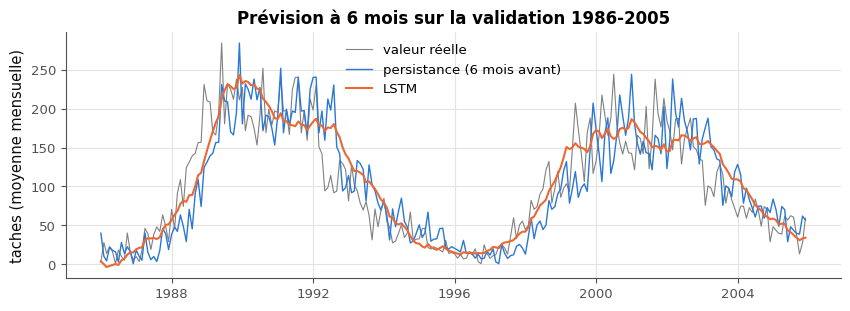

In [49]:
scale_23 = SPOTS[:I86].max()
X_train_23, y_train_23 = mylearn.sequences.make_windows(SPOTS[:I86] / scale_23, 60, horizon=6)
X_val_23, y_val_23 = mylearn.sequences.make_windows(SPOTS[I86 - 65:I06] / scale_23, 60, horizon=6)
n_train_23 = len(X_train_23)
persistence_23 = float(np.sqrt(np.mean((SPOTS[I86 - 6:I06 - 6] - SPOTS[I86:I06]) ** 2)))   # the value 6 months earlier


class SunspotLSTM_23(nn.Module):
    """nn.LSTM(1, hidden_size, batch_first=True), then nn.Linear(hidden_size, 1) on the output of the last step:
    windows (N, T, 1) -> predictions (N,)."""

    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)                # many-to-one: the last step only


def fit_23(model, X, y, epochs=20, lr=3e-3, batch_size=64, seed=0):
    """Train `model` in place with Adam(lr) and nn.MSELoss, gradient clipping at a norm of 1.0, on mini-batches in a new
    random order at each epoch (torch.randperm with torch.Generator().manual_seed(seed), created once). X (N, T, 1) and
    y (N,) are float32 tensors. Return the list of the mean training loss of each epoch (Python floats)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    generator = torch.Generator().manual_seed(seed)
    history = []
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(X), generator=generator)
        total = 0.0
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X[batch]), y[batch])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(batch)
        history.append(total / len(X))
    return history


wb.check("22.23a", n_train_23)
wb.check("22.23b", persistence_23)
model_23 = None
with checked("22.23"):
    ok_data_23 = filled(scale_23, X_train_23, y_train_23, X_val_23, y_val_23)
    if not ok_data_23:
        print("⏳ Ex 22.23 : prépare d'abord scale_23 et les fenêtres.")
    else:
        Xv_23, yv_23 = np.asarray(X_val_23), np.asarray(y_val_23)
        same("22.23", "les cibles de validation, remises à l'échelle, contre SPOTS[I86:I06]", yv_23 * scale_23, SPOTS[I86:I06],
             rtol=1e-5)                                         # float32 windows are fine
        same("22.23", "la dernière valeur de chaque fenêtre de validation : 6 mois avant sa cible",
             Xv_23[:, -1, 0] * scale_23, SPOTS[I86 - 6:I06 - 6], rtol=1e-5)
        verdict("22.23", np.asarray(y_train_23).max() * scale_23 <= SPOTS[:I86].max() and len(y_train_23) + 65 == I86,
                "les fenêtres d'entraînement, cibles comprises, restent avant 1986.",
                "les fenêtres d'entraînement doivent rester avant 1986, cible comprise : prends-les dans SPOTS[:I86].")
        torch.manual_seed(2223)
        model_23 = SunspotLSTM_23()
        to32 = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
        history_23 = fit_23(model_23, to32(X_train_23), to32(y_train_23))
        if returned("22.23", "fit_23", history_23):
            verdict("22.23", isinstance(history_23, list) and len(history_23) == 20 and history_23[-1] < history_23[0],
                    "fit_23 rend 20 loss moyennes, qui baissent.",
                    f"fit_23 doit rendre une liste de 20 loss moyennes qui baissent ; reçu {history_23!r:.120}.")
            model_23.eval()
            with torch.no_grad():
                pred_23 = model_23(to32(Xv_23)).numpy().astype(float) * scale_23
            rmse_23 = float(np.sqrt(np.mean((pred_23 - SPOTS[I86:I06]) ** 2)))
            ratio_23 = rmse_23 / float(np.sqrt(np.mean((SPOTS[I86 - 6:I06 - 6] - SPOTS[I86:I06]) ** 2)))
            print(f"RMSE de validation (1986-2005) : LSTM {rmse_23:.1f} taches · rapport à la persistance {ratio_23:.2f}")
            verdict("22.23", ratio_23 < 0.9, "le LSTM bat la persistance de plus de 10 % en validation.",
                    f"rapport {ratio_23:.2f} à la persistance : attendu moins de 0,9 ; relis le contrat de fit_23 et la mise à l'échelle.")
            fig, ax = plt.subplots(figsize=(10, 3.2))
            dates_23 = SUNSPOTS["date"].iloc[I86:I06]
            ax.plot(dates_23, SPOTS[I86:I06], lw=0.8, color="0.5", label="valeur réelle")
            ax.plot(dates_23, SPOTS[I86 - 6:I06 - 6], lw=1, label="persistance (6 mois avant)")
            ax.plot(dates_23, pred_23, lw=1.5, label="LSTM")
            ax.set_ylabel("taches (moyenne mensuelle)")
            ax.set_title("Prévision à 6 mois sur la validation 1986-2005")
            ax.legend()
            plt.show()

In [50]:
pers_h1_23 = float(np.sqrt(np.mean((SPOTS[I86 - 1:I06 - 1] - SPOTS[I86:I06]) ** 2)))
wb.record("22.23a", n_train_23, mistakes={"tu as oublié le + 1 de la formule du nombre de fenêtres": n_train_23 - 1,
          "l'horizon vaut 6 : la cible est 6 mois après la fin de la fenêtre": I86 - 60})
wb.record("22.23b", persistence_23, decimals=1, mistakes={"la persistance à 6 mois répète la valeur d'il y a 6 mois, pas celle du mois précédent": pers_h1_23,
          "en taches, pas à l'échelle de l'entraînement": persistence_23 / scale_23})

WB_ANSWER {"hash": "f24eb0e032f8f1b8b0d5778d7b030d8d73d0189a78cad8ea8b8d242662c304af", "id": "22.23a", "kind": "int", "magnitude": 3, "mistakes": {"7126c87d869d9790867c2e3bd8dffdee43eb6f36675b5f72196f85be6493085e": "l'horizon vaut 6 : la cible est 6 mois après la fin de la fenêtre", "ff924d1ca672e9a7dd3423cb36b6c6ff0fde7aab6913ddfe4fbb5b4b65824c22": "tu as oublié le + 1 de la formule du nombre de fenêtres"}, "sign": 1}
📝 Ex 22.23a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "90dc61f9ae5954ece9ea5cdcf00eba1ce6dc58e9d35b22f33f8fdf128037c2a7", "hash_coarse": "bd97683a06508ac7bcfa477541ddedb07e1da809a2a71b5bfca66591e265bd3c", "id": "22.23b", "kind": "float", "magnitude": 1, "mistakes": {"5d30ddb501829cc1f43bcb286e468eba6ebd1a71189a92b6dfdd8a24bb4fffd5": "en taches, pas à l'échelle de l'entraînement", "a453e6c9065de06b543e89e6103d02d8b2c628ec4e0a3f5219d3c11c2aebbc8f": "la persistance à 6 mois répète la valeur d'il y a 6 mois, pas celle du mois précédent"}, "sign": 1}
📝 Ex

💡 Le LSTM fait de l'ordre d'un quart de mieux que la persistance sur 1986-2005 (le rapport exact dépend de la graine) ; il gagne surtout dans les montées et les descentes du cycle, où la valeur d'il y a 6 mois est la plus fausse, et beaucoup moins au sommet, où le bruit mensuel domine. Choisir des réglages sur cette validation, puis annoncer sa RMSE, c'est la même fuite que choisir un modèle sur le test : la RMSE annoncée serait optimiste. D'où le test caché du défi 22.29, ouvert une seule fois.

### Ex 22.24 — Température : prédire l'allure du texte généré 🔮 ★ ⏱️ 10 min
**Objectif :** prédire l'effet de la température sur un générateur de texte, puis le mesurer avec ton `sample_from_logits`.  
**Prérequis :** Ex 22.20 · ✏️ 22.5 · fiche §22.9 · **Fil rouge :** Holmes · **Parcours :** C

Le plus simple des générateurs de texte : un **modèle de paires de lettres** (bigrammes, ch. 6). Pour chaque caractère de Holmes, on compte les caractères qui le suivent ; les logits du caractère suivant sont les logarithmes de ces fréquences (avec +1 partout, pour qu'aucun caractère ne soit impossible). La cellule suivante le construit et définit `generate_bigram_24(temperature)`, qui tire 2 000 caractères l'un après l'autre avec **ton** `sample_from_logits` (22.20), en partant de « T ».

Prédis, **avant** d'exécuter :
a) `greedy_distinct_24` : à la température 0, combien de caractères **distincts** parmi les 2 000 ? `"A"` de 1 à 10, `"B"` de 11 à 40, `"C"` de 41 à 80, `"D"` plus de 80 ;
b) `hot_distinct_24` : même question à la température 2 (les mêmes quatre lettres) ;
c) `cool_real_24` : à la température 0,3, la part des mots générés qui existent dans Holmes : `"A"` moins de 50 %, `"B"` de 50 à 90 %, `"C"` plus de 90 %.

L'expérience génère à 0 ; 0,3 ; 1 et 2, affiche pour chaque température le nombre de caractères distincts, la part de mots qui existent (un mot : une suite de lettres a à z) et le début du texte.

In [51]:
CHARS_24 = sorted(set(HOLMES))                               # a character vocabulary of its own (88 characters)
INDEX_24 = {c: i for i, c in enumerate(CHARS_24)}
ids_24 = np.array([INDEX_24[c] for c in HOLMES])
counts_24 = np.ones((len(CHARS_24), len(CHARS_24)))            # +1: no character is impossible after another
np.add.at(counts_24, (ids_24[:-1], ids_24[1:]), 1)
LOGITS_24 = np.log(counts_24 / counts_24.sum(axis=1, keepdims=True))   # row c: the logits of the character after c
WORDS_24 = set(re.findall(r"[a-z]+", HOLMES.lower()))           # every word of Holmes, lower case


def generate_bigram_24(temperature, n_chars=2000, seed=24):
    """2 000 characters drawn one after the other by YOUR sample_from_logits, from the bigram logits, starting at "T"."""
    rng = np.random.default_rng(seed)
    current, out = INDEX_24["T"], ["T"]
    for _ in range(n_chars):
        current = int(mylearn.sequences.sample_from_logits(LOGITS_24[current], temperature=temperature, rng=rng))
        out.append(CHARS_24[current])
    return "".join(out)

In [52]:
greedy_distinct_24, hot_distinct_24, cool_real_24 = "A", "D", "B"

In [53]:
wb.record("22.24a", "A", mistakes={"de 11 à 40 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?": "B", "de 41 à 80 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?": "C", "plus de 80 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?": "D"})
wb.record("22.24b", "D", mistakes={"de 1 à 10 caractères à température 2 ? Les logits sont divisés par 2 : un caractère rare garde-t-il une chance sur 2 000 tirages ?": "A", "de 11 à 40 caractères à température 2 ? Les logits sont divisés par 2 : un caractère rare garde-t-il une chance sur 2 000 tirages ?": "B", "de 41 à 80 caractères à température 2 ? Les logits sont divisés par 2 : un caractère rare garde-t-il une chance sur 2 000 tirages ?": "C"})
wb.record("22.24c", "B", mistakes={"à 0,3, le modèle suit surtout les paires de lettres les plus fréquentes : quels mots courts en sortent ?": "A", "un modèle de paires de lettres ne connaît pas les mots : peut-il n'écrire que des mots qui existent ?": "C"})

WB_ANSWER {"hash": "28361395f2a9bb9338b9e31be7bc48661209e179f6da2295f998d6f1079b6fde", "id": "22.24a", "kind": "str", "mistakes": {"2ba56911cc20615295b8a481ad9dca094a1370a3f2417a44453bdbe8261f7de3": "de 41 à 80 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?", "49bf735e0dff2ced103710b72fa0ef8535849d001eecbac2c3e2717ee300c5af": "plus de 80 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?", "b8bab51cd258ee5d3f8ee9b52d491ab18e72976250ea0523def0ce6414a88e87": "de 11 à 40 caractères à température 0 ? Le même caractère suit toujours le même caractère : combien de caractères avant que la suite se répète ?"}}
📝 Ex 22.24a : réponse enregistrée (str).
WB_ANSWER {"hash": "6e1c216b6936c9640395566c1e47b9ed88771766901356159487b2a82c5232a9", "id": "22.24b", "kind": "str", "mistakes": {"384800a6522a907b22ca77a8d5e385de46ec4a03da674f0

In [54]:
if any(answer is ... or answer is None for answer in [greedy_distinct_24, hot_distinct_24, cool_real_24]):
    print("⏳ Ex 22.24 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    with checked("22.24"):
        for temperature_24 in (0, 0.3, 1.0, 2.0):
            text_24 = generate_bigram_24(temperature_24)
            words_24 = re.findall(r"[a-z]+", text_24.lower())
            real_24 = np.mean([w in WORDS_24 for w in words_24]) if words_24 else 0.0
            print(f"T = {temperature_24} · {len(set(text_24))} caractères distincts · {real_24:.0%} de mots qui existent")
            print("   ", repr(text_24[:110]))
    wb.check("22.24a", greedy_distinct_24)
    wb.check("22.24b", hot_distinct_24)
    wb.check("22.24c", cool_real_24)

T = 0 · 5 caractères distincts · 100% de mots qui existent
    'The the the the the the the the the the the the the the the the the the the the the the the the the the the th'


T = 0.3 · 23 caractères distincts · 79% de mots qui existent
    'The the as the than are o than the in and he t the and t t he the the he than be wind ange be in the t the the'


T = 1.0 · 65 caractères distincts · 36% de mots qui existent
    'Thefeees sslet th f. pis, so inthatas ber cere wimacassilpe r.’ toprinat se blasoworis Tisaide omeallieroosina'
T = 2.0 · 88 caractères distincts · 27% de mots qui existent
    'TSckelks rsok£ tiEKMDndma pp(TewhavcoX91uOJ?’cavofR.\nrsoct04ierbusitkALo1ke ThPosàâgir! volT1ofiled-licoulnlla'
✅ Ex 22.24a : Bravo !
✅ Ex 22.24b : Exact !
✅ Ex 22.24c : Bien joué !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Laquelle des quatre températures choisirais-tu pour produire un texte qui « ressemble à de l'anglais », et que faudrait-il au modèle pour aller plus loin que des mots courts ?

💡 À la température 0, le choix est déterministe : après « T » vient « h », puis « e », puis l'espace, puis « t »… et la suite « the the the » se répète : une poignée de caractères. À 2, les logits divisés par 2 rapprochent les probabilités de l'uniforme : en 2 000 tirages, les 88 caractères sortent, chiffres et ponctuation compris. À 0,3, le modèle suit surtout les paires les plus fréquentes et écrit beaucoup de petits mots qui existent (« the », « he », « a »), mais aussi des fragments : un modèle de paires de lettres ne connaît pas les mots, il faut plus de contexte (le LSTM de 22.25 lit 40 caractères).

## Partie D · Générer du texte, comparer deux langues, lire une vidéo, prévoir le cycle solaire

Le générateur de caractères du livre, en PyTorch : tu l'écris et tu l'entraînes sur Holmes (22.25), tu lis sa courbe de loss sur 20 epochs (22.26), tu compares l'anglais de Holmes et le français de Verne avec le même réseau (22.27) ; puis le CNN-LSTM du livre, sur des vidéos de balle synthétiques (22.28), et le défi des taches solaires (22.29). Ces exercices utilisent ta librairie `sequences.py` (parties A et C).

### Ex 22.25 — Générer du Holmes caractère par caractère (deux LSTM, many-to-one) 📦 ★★★ ⏱️ 60 min 🚀
**Objectif :** écrire, entraîner et faire parler le générateur de texte du livre : deux couches LSTM, une couche dense, un caractère à la fois.  
**Prérequis :** Ex 22.12 · Ex 22.13 · Ex 22.20 · Ex 22.22 · ch. 20 (boucle d'entraînement) · fiche §22.9, §22.8.2 · **Fil rouge :** Holmes · **Parcours :** C

Le générateur du §22.9 : il lit 40 caractères et prédit le suivant (many-to-one) ; on le fait ensuite écrire en lui redonnant sans cesse ses propres caractères. Les données : les fenêtres de 40 caractères de Holmes, une tous les 3 caractères, chacune avec le caractère qui la suit (ta `make_windows` avec `horizon=1, stride=3`) ; l'entraînement lit les `N_TRAIN_25` premiers caractères, la validation les 10 % de la fin.

**Contrat**
- `CharLSTM_25(vocab_size, hidden_size=128, num_layers=2)` : des ids `(N, T)` int64 passent en one-hot `(N, T, V)` (`F.one_hot(...).float()`), puis dans un `nn.LSTM(V, hidden_size, num_layers, batch_first=True)` ; un `nn.Linear(hidden_size, V)` lit la sortie du **dernier** pas et rend des logits `(N, V)` (pas de softmax : `F.cross_entropy` l'applique) ;
- `train_25(model, X, y, epochs=2, batch_size=128, seed=0)` entraîne en place avec la cross-entropy, `torch.optim.RMSprop(lr=0.01, alpha=0.9)` (le réglage du code Keras du livre) et `clip_grad_norm_` à 1,0, dans un nouvel ordre à chaque epoch (un seul `torch.Generator().manual_seed(seed)`) ; chaque mini-batch va sur l'appareil du modèle ; elle rend la liste des loss moyennes de chaque epoch ;
- `generate_25(model, seed_text, n_chars, stoi, itos, temperature=1.0, rng=None)` encode l'amorce (ta `encode`), puis répète `n_chars` fois : le modèle lit les 40 derniers ids (tous, s'il y en a moins), en mode évaluation et sans autograd, et ta `sample_from_logits` tire l'id suivant (logits en `float64`) ; elle rend les `n_chars` **nouveaux** caractères (ta `decode`), sans l'amorce.

La vérification contrôle l'architecture (nombre de paramètres, formes), prépare les données avec ta librairie, entraîne (une à deux minutes sur un CPU peu chargé en mode rapide, bien plus si d'autres programmes tournent : 240 000 caractères, 2 epochs), mesure la loss de validation (attendu : moins de `TARGET_25`, 2,1 nats en mode rapide, 1,6 en mode complet), puis fait écrire le réseau à trois températures. 🚀 Le mode complet (tout l'entraînement, 20 epochs) prend une demi-heure sur un CPU : un GPU Colab est conseillé ; 📈 22.26 lit son historique.

Dans tes notes : que fait le texte à la température 0 (le choix du livre, le caractère le plus probable) ? Quelle température donne le texte le plus « Holmes » ? Pourquoi une fenêtre tous les 3 caractères, plutôt qu'à chaque caractère ?

In [55]:
WINDOW_25 = 40                                               # the network reads 40 characters...
STRIDE_25 = 3                                                # ...and a window starts every 3 characters
CUT_25 = int(0.9 * len(HOLMES))                              # the last 10 % of Holmes: the validation
N_TRAIN_25 = 240_000 if FAST_MODE else CUT_25                # characters of training text
EPOCHS_25 = 2 if FAST_MODE else 20
TARGET_25 = 2.1 if FAST_MODE else 1.6                        # validation loss expected (nats per character)
SEED_25 = "To Sherlock Holmes she is always the wom"          # 40 characters: the start of the first story
print(f"training on {N_TRAIN_25:_} characters, {EPOCHS_25} epochs · validation on {len(HOLMES) - CUT_25:_} characters".replace("_", " "))

training on 240 000 characters, 2 epochs · validation on 56 221 characters


In [56]:
class CharLSTM_25(nn.Module):
    """Character-level generator: ids (N, T) int64 -> one-hot (N, T, V) -> nn.LSTM(V, hidden_size, num_layers,
    batch_first=True) -> nn.Linear(hidden_size, V) on the output of the LAST step -> logits (N, V)."""

    def __init__(self, vocab_size, hidden_size=128, num_layers=2):
        super().__init__()
        self.vocab_size = vocab_size
        self.lstm = nn.LSTM(vocab_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, ids):
        out, _ = self.lstm(F.one_hot(ids, self.vocab_size).float())   # one-hot: (N, T) -> (N, T, V)
        return self.head(out[:, -1])                                   # many-to-one: the last step only


def train_25(model, X, y, epochs=2, batch_size=128, seed=0):
    """Train `model` in place on the windows X (N, T) int64 and their next characters y (N,) int64: cross-entropy,
    RMSprop(lr=0.01, alpha=0.9), gradient clipping at a norm of 1.0, mini-batches in a new random order at each epoch
    (torch.randperm with one torch.Generator().manual_seed(seed)), each batch moved to the device of the model.
    Return the list of the mean training loss of each epoch (Python floats)."""
    device = next(model.parameters()).device
    optimizer = torch.optim.RMSprop(model.parameters(), lr=0.01, alpha=0.9)
    generator = torch.Generator().manual_seed(seed)
    history = []
    for _ in range(epochs):
        model.train()
        total = 0.0
        for batch in torch.randperm(len(X), generator=generator).split(batch_size):
            xb, yb = X[batch].to(device), y[batch].to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(batch)
        history.append(total / len(X))
    return history


def generate_25(model, seed_text, n_chars, stoi, itos, temperature=1.0, rng=None):
    """Generate n_chars characters after seed_text, one at a time: the model reads the last 40 characters (all of
    them while there are fewer), mylearn.sequences.sample_from_logits draws the next id. Return the n_chars new
    characters as a str (without seed_text)."""
    device = next(model.parameters()).device
    rng = np.random.default_rng() if rng is None else rng
    ids = list(mylearn.sequences.encode(seed_text, stoi))
    new = []
    model.eval()
    with torch.no_grad():
        for _ in range(n_chars):
            window = torch.tensor([ids[-40:]], device=device)
            logits = model(window)[0].cpu().numpy().astype(np.float64)
            nxt = mylearn.sequences.sample_from_logits(logits, temperature=temperature, rng=rng)
            ids.append(nxt)
            new.append(nxt)
    return mylearn.sequences.decode(np.array(new, dtype=np.int64), itos)


def val_loss_25(model, X, y, batch_size=2000):
    """Given: the mean cross-entropy (nats per character) of a model on windows X and next characters y."""
    device = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        total = sum(F.cross_entropy(model(X[i:i + batch_size].to(device)), y[i:i + batch_size].to(device),
                                    reduction="sum").item() for i in range(0, len(X), batch_size))
    return total / len(X)


model_25 = None
with checked("22.25"):
    S = mylearn.sequences
    torch.manual_seed(2225)
    probe_25 = CharLSTM_25(88)
    want_params_25 = n_params(nn.LSTM(88, 128, num_layers=2)) + 128 * 88 + 88
    verdict("22.25", n_params(probe_25) == want_params_25,
            "CharLSTM_25(88) a " + f"{want_params_25:,}".replace(",", " ") + " paramètres : deux couches LSTM de 128 et la couche dense.",
            "CharLSTM_25(88) a " + f"{n_params(probe_25):,}".replace(",", " ") + " paramètres, attendu "
            + f"{want_params_25:,}".replace(",", " ") + " : relis l'architecture du contrat.")
    with torch.no_grad():
        logits_probe_25 = probe_25(torch.randint(0, 88, (3, 40)))
    verdict("22.25", tuple(logits_probe_25.shape) == (3, 88),
            "des ids (3, 40) donnent des logits (3, 88).",
            f"des ids (3, 40) donnent {shape_text(logits_probe_25)} : attendu (3, 88), un vecteur de logits par fenêtre.")

    stoi_25, itos_25 = pair("22.25", "build_vocab(HOLMES)", S.build_vocab(HOLMES), names=("stoi", "itos"))
    ids_25 = S.encode(HOLMES, stoi_25)
    X_25, y_25 = S.make_windows(ids_25[:N_TRAIN_25], WINDOW_25, horizon=1, stride=STRIDE_25)
    Xv_25, yv_25 = S.make_windows(ids_25[CUT_25:], WINDOW_25, horizon=1, stride=STRIDE_25)
    X_25, y_25, Xv_25, yv_25 = (torch.from_numpy(np.ascontiguousarray(a)) for a in (X_25[:, :, 0], y_25, Xv_25[:, :, 0], yv_25))
    print(f"{len(X_25):_} training windows · {len(Xv_25):_} validation windows · {len(itos_25)} characters".replace("_", " "))

    torch.manual_seed(2225)
    model_25 = CharLSTM_25(len(itos_25)).to(DEVICE)
    started_25 = time.perf_counter()
    losses_25 = train_25(model_25, X_25, y_25, epochs=EPOCHS_25)
    if returned("22.25", "train_25", losses_25):
        val_25 = val_loss_25(model_25, Xv_25, yv_25)
        print(f"training: {time.perf_counter() - started_25:.0f} s · mean training loss per epoch "
              f"{[round(v, 3) for v in losses_25]} · validation loss {val_25:.3f} nats")
        verdict("22.25", isinstance(losses_25, list) and len(losses_25) == EPOCHS_25,
                f"train_25 rend {EPOCHS_25} loss moyennes.", f"train_25 doit rendre une liste de {EPOCHS_25} loss moyennes.")
        verdict("22.25", val_25 < TARGET_25, f"loss de validation sous {TARGET_25} nats par caractère.",
                f"loss de validation {val_25:.3f} : attendu moins de {TARGET_25} ; relis le contrat de train_25 "
                "(optimiseur, clipping, ordre des mini-batches).")

        text_a_25 = generate_25(model_25, SEED_25, 60, stoi_25, itos_25, temperature=0)
        text_b_25 = generate_25(model_25, SEED_25, 60, stoi_25, itos_25, temperature=0)
        verdict("22.25", isinstance(text_a_25, str) and len(text_a_25) == 60 and text_a_25 == text_b_25,
                "generate_25 rend 60 nouveaux caractères, les mêmes deux fois à température 0.",
                f"generate_25(..., 60, temperature=0) doit rendre une str de 60 caractères, la même à chaque appel ; "
                f"reçu {text_a_25!r:.80}.")
        short_25 = generate_25(model_25, "Wat", 5, stoi_25, itos_25, temperature=1.0, rng=np.random.default_rng(0))
        verdict("22.25", isinstance(short_25, str) and len(short_25) == 5,
                "une amorce de 3 caractères suffit.", "une amorce plus courte que 40 caractères doit fonctionner.")
        for temperature_25 in (0, 0.5, 1.0):
            print(f"\n--- température {temperature_25} ---")
            print(SEED_25 + generate_25(model_25, SEED_25, 300, stoi_25, itos_25, temperature=temperature_25,
                                        rng=np.random.default_rng(25)))

✅ Ex 22.25 : CharLSTM_25(88) a 255 064 paramètres : deux couches LSTM de 128 et la couche dense.
✅ Ex 22.25 : des ids (3, 40) donnent des logits (3, 88).


79 987 training windows · 18 727 validation windows · 88 characters


training: 79 s · mean training loss per epoch [2.213, 1.771] · validation loss 1.754 nats
✅ Ex 22.25 : train_25 rend 2 loss moyennes.
✅ Ex 22.25 : loss de validation sous 2.1 nats par caractère.
✅ Ex 22.25 : generate_25 rend 60 nouveaux caractères, les mêmes deux fois à température 0.


✅ Ex 22.25 : une amorce de 3 caractères suffit.

--- température 0 ---


To Sherlock Holmes she is always the woman and that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that that tha

--- température 0.5 ---


To Sherlock Holmes she is always the womates a
cassion of the with the wind the trance that he carries of the reforts and he was of his rashed a fingers of ancont to be the man of the some the lead that that it is that with comperally becamition and opened my dide that when he cantrest, that is must out that my thate and him in him with h

--- température 1.0 ---


To Sherlock Holmes she is always the wome at twhe yinf interestssing had feettey upon
a matires, her had was beerirade up ne wondooh, the drearing his bery my
marrahe, he
sule of that, when becores of
e“shated vere of offeriction my clumpag, was sunge.

“Ay
liys,
and sicdady off that that when
chis that
twagding ne knowress; where
through


💡 À la température 0, le réseau finit presque toujours dans une boucle (« that that that… », ou « to the street to the street… ») : le caractère le plus probable après une suite donnée est toujours le même, et une suite qui revient ramène le même texte. Vers 0,5, le texte a des mots anglais, de la ponctuation et des guillemets à leur place, avec des phrases sans suite ; à 1, il invente des mots. Une fenêtre tous les 3 caractères divise le temps d'une epoch par 3 : des fenêtres voisines se recouvrent de 37 caractères sur 40 et apprendraient presque la même chose.

### Ex 22.26 — Lire la courbe de loss et la perplexité du générateur 📈 ★★ ⏱️ 15 min
**Objectif :** lire une courbe de loss de générateur, la traduire en perplexité et en bits par caractère, et la comparer à un modèle sans contexte.  
**Prérequis :** Ex 22.25 · ch. 6 (entropie) · ch. 19 (courbes d'apprentissage) · fiche §22.9 · **Fil rouge :** Holmes · **Parcours :** C

Le générateur de 22.25 en mode complet, entraîné 20 epochs sur 90 % de Holmes (environ 25 minutes sur un CPU, calculées à l'avance) : la cellule suivante donne ses loss moyennes d'entraînement et ses loss de validation après chaque epoch, en **nats par caractère** (la cross-entropy de PyTorch utilise le logarithme naturel), et des textes générés après quelques epochs.

La **perplexité** d'un modèle de langue est l'exponentielle de sa cross-entropy moyenne : $e^{\text{loss}}$ quand la loss est en nats. Elle se lit comme un nombre de choix : une perplexité de 5, c'est en moyenne la même incertitude qu'un choix au hasard entre 5 caractères. La même loss, en **bits par caractère**, est la loss divisée par $\ln 2$ (ch. 6).

Calcule, avec NumPy, à partir de `TRAIN_LOSS_26`, `VAL_LOSS_26` et `HOLMES` :
a) `best_epoch_26` : l'epoch (la première est 1) de la plus basse loss de validation ;
b) `perplexity_26` : la perplexité de validation à cette epoch ;
c) `bits_26` : la loss de validation à cette epoch, en bits par caractère ;
d) `unigram_26` : la perplexité d'un modèle **sans contexte**, qui donne à chaque caractère sa fréquence dans `HOLMES` (son entropie, ch. 6, passée à l'exponentielle) ;
e) `overfit_26` : `"A"` aucun signe d'overfitting en 20 epochs ; `"B"` la loss de validation cesse de baisser, ou remonte, alors que celle d'entraînement continue de baisser ; `"C"` les deux loss remontent à la fin.

Dans tes notes : combien de « choix » le contexte de 40 caractères retire-t-il, par rapport au modèle sans contexte, et par rapport à un modèle uniforme sur les 88 caractères ? Quelle epoch garderais-tu, et comment le ferais-tu automatiquement (ch. 19) ? Les textes générés s'améliorent-ils encore quand la loss de validation ne baisse plus ?

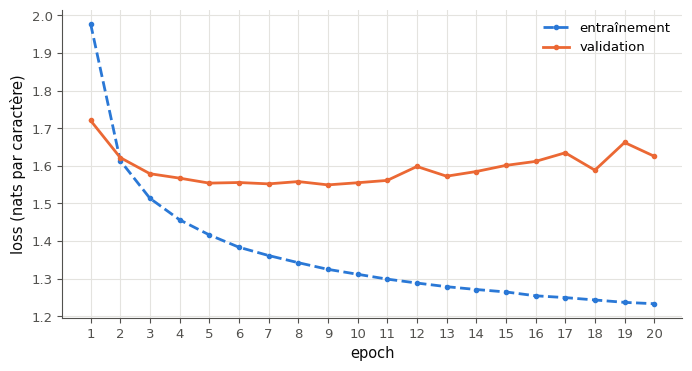

--- après l'epoch 1 ---
T = 0.0 : 'e to the street to the street to the street to the street to the street to the street to the street to the street to the'
T = 0.5 : 'e to been other countered by the coundly to his that the father to be an my fliend of the pleach come of the concerty me'
--- après l'epoch 3 ---
T = 0.0 : 'an and the street and the street and the street and the street and the street and the street and the street and the stre'
T = 0.5 : 'an that it the son’t adverly had long became last interest the largine which I had been that I could say that so that I '
--- après l'epoch 10 ---
T = 0.0 : 'an and the street of the street. I was a considerable of the street. I was a considerable of the street. I was a conside'
T = 0.5 : 'an those preferent of a coventions and not this action that we shall alport against the sight from a chair in the countr'
--- après l'epoch 20 ---
T = 0.0 : 'ent of the sight of the sight of the sight of the sight of the sight of the sight of the sigh

In [57]:
# The generator of Ex 22.25 in its full mode, 20 epochs on 90 % of Holmes (precomputed: about 25 minutes on a CPU).
# 168648 training windows, 18727 validation windows (the last 10 %).
# After each epoch: the mean training loss and the validation loss, in nats per character.
TRAIN_LOSS_26 = [1.9778, 1.6141, 1.5137, 1.4566, 1.4165, 1.3837, 1.3616, 1.3426, 1.3249, 1.3118, 1.2989, 1.2885, 1.2788, 1.2713, 1.2648, 1.2546, 1.2498, 1.2435, 1.2371, 1.2335]
VAL_LOSS_26 = [1.7206, 1.6219, 1.5791, 1.5673, 1.5541, 1.5557, 1.5521, 1.5582, 1.5494, 1.5551, 1.5613, 1.5983, 1.5725, 1.5849, 1.6012, 1.6118, 1.6347, 1.5885, 1.6621, 1.6255]
SAMPLES_26 = {   # 200 characters generated after the seed, at the temperatures 0 and 0.5, after some epochs
    1: {0.0: 'e to the street to the street to the street to the street to the street to the street to the street to the street to the street to the street to the street to the street to the street to the street to',
         0.5: 'e to been other countered by the coundly to his that the father to be an my fliend of the pleach come of the concerty me that I once to you streed of the saver to be that I had back to the was the fro'},
    3: {0.0: 'an and the street and the street and the street and the street and the street and the street and the street and the street and the street and the street and the street and the street and the street an',
         0.5: 'an that it the son’t adverly had long became last interest the largine which I had been that I could say that so that I had a both his hand of the face to say that I had away and little his name. I co'},
    10: {0.0: 'an and the street of the street. I was a considerable of the street. I was a considerable of the street. I was a considerable of the street. I was a considerable of the street. I was a considerable of',
         0.5: 'an those preferent of a coventions and not this action that we shall alport against the sight from a chair in the country beating of the winding walking in some strange of\nthe winding of mine of the m'},
    20: {0.0: 'ent of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight of the sight o',
         0.5: 'ent in the extreme of the Able to the bandle which had had the man for more than the county. And you are a permise\nand the matter of the most fact who is that the bushone before you an excellent\nof my'},
}
epochs_26 = np.arange(1, len(VAL_LOSS_26) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs_26, TRAIN_LOSS_26, "--o", ms=3, label="entraînement")
ax.plot(epochs_26, VAL_LOSS_26, "-o", ms=3, label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("loss (nats par caractère)")
ax.set_xticks(epochs_26)
ax.legend()
plt.show()
for epoch_26, texts_26 in SAMPLES_26.items():
    print(f"--- après l'epoch {epoch_26} ---")
    for temperature_26, text_26 in texts_26.items():
        print(f"T = {temperature_26} :", repr(text_26[:120]))

In [58]:
best_epoch_26 = int(np.argmin(VAL_LOSS_26)) + 1               # the epochs count from 1
perplexity_26 = float(np.exp(min(VAL_LOSS_26)))                # the loss is in nats: e to the loss
bits_26 = min(VAL_LOSS_26) / np.log(2)
freqs_26 = np.array(list(Counter(HOLMES).values())) / len(HOLMES)
unigram_26 = float(np.exp(-(freqs_26 * np.log(freqs_26)).sum()))   # e to the entropy (nats), as for the network
overfit_26 = "B"
wb.check("22.26a", best_epoch_26)
wb.check("22.26b", perplexity_26)
wb.check("22.26c", bits_26)
wb.check("22.26d", unigram_26)
wb.check("22.26e", overfit_26)

✅ Ex 22.26a : Bien joué !
✅ Ex 22.26b : C'est ça !
✅ Ex 22.26c : Parfait !
✅ Ex 22.26d : Bravo !
✅ Ex 22.26e : Exact !


In [59]:
wrong_a_26 = {"les epochs se comptent à partir de 1 : l'indice 0 est l'epoch 1": best_epoch_26 - 1}
if int(np.argmin(TRAIN_LOSS_26)) + 1 not in (best_epoch_26, best_epoch_26 - 1):
    wrong_a_26["c'est la loss de validation qui choisit l'epoch, pas celle d'entraînement"] = int(np.argmin(TRAIN_LOSS_26)) + 1
wb.record("22.26a", best_epoch_26, mistakes=wrong_a_26)
wrong_b_26 = {"la loss est en nats : la perplexité est e puissance la loss, pas 2 puissance la loss": 2 ** min(VAL_LOSS_26)}
if abs(np.exp(VAL_LOSS_26[-1]) - perplexity_26) > 0.01:
    wrong_b_26["prends l'epoch de la plus basse loss de validation, pas la dernière"] = float(np.exp(VAL_LOSS_26[-1]))
wb.record("22.26b", perplexity_26, decimals=2, mistakes=wrong_b_26)
wb.record("22.26c", bits_26, decimals=3, mistakes={"pour passer des nats aux bits, on divise par ln 2": min(VAL_LOSS_26) * np.log(2),
          "les bits se calculent sur la loss, pas sur la perplexité : log2 de la perplexité, ou loss / ln 2": float(np.log(perplexity_26))})
entropy_nats_26 = float(-(freqs_26 * np.log(freqs_26)).sum())
wb.record("22.26d", unigram_26, decimals=2, mistakes={"la perplexité est l'exponentielle de l'entropie, pas l'entropie elle-même": entropy_nats_26,
          "un modèle sans contexte utilise les fréquences des caractères, pas la même probabilité pour tous": 88.0,
          "l'entropie calculée avec ln est en nats : la perplexité est e puissance l'entropie, pas 2 puissance": 2 ** entropy_nats_26})
wb.record("22.26e", "B", mistakes={"compare les deux courbes sur les dernières epochs : l'écart entre entraînement et validation reste-t-il le même ?": "A", "regarde la loss d'entraînement des dernières epochs : monte-t-elle ?": "C"})

WB_ANSWER {"hash": "cebc42733ed80e5e3a6ebee70bd3285ed71b32b1320deff1c279db2d73fe4894", "id": "22.26a", "kind": "int", "magnitude": 0, "mistakes": {"963122a530116fe12b9322198cf23283eb1b5f90a7424e7dc72ce46c0221f76c": "les epochs se comptent à partir de 1 : l'indice 0 est l'epoch 1", "bed9a9a43a0ed4f8f803cd316f90ebc630e4b4dd57bb9a3814e88aecb1148276": "c'est la loss de validation qui choisit l'epoch, pas celle d'entraînement"}, "sign": 1}
📝 Ex 22.26a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "555e1c8f7c58649a2a575a43b1d8fc29f7354f198fe964a93e397a0cb123538a", "hash_coarse": "77b99882175ea6b97a5f09aeb94484b8752a94ee7f00f7284dffc5c7cd11f20f", "id": "22.26b", "kind": "float", "magnitude": 0, "mistakes": {"2369c8717863a927b3579fdb5c71aa504e54dee665348ef0d2d868aa11ff1ffb": "prends l'epoch de la plus basse loss de validation, pas la dernière", "c4b4721123d177a0f7381a5c66f8ecb9b673276862cb1f07c558d8a488912f10": "la loss est en nats : la perplexité est e puissance la loss, pas 

💡 La loss de validation la plus basse est atteinte à l'epoch 9 (1,549 nats, une perplexité de 4,71, soit 2,24 bits par caractère) ; ensuite elle oscille et remonte, alors que la loss d'entraînement baisse jusqu'au bout : le réseau commence à apprendre le texte d'entraînement par cœur (B). Un modèle sans contexte a une perplexité de 22,4 (une entropie de 4,49 bits), un modèle uniforme de 88 : le contexte de 40 caractères divise le nombre de « choix » par près de cinq par rapport aux seules fréquences. À la température 0, les textes tournent en boucle à toutes les epochs ; à 0,5, ils gagnent en vocabulaire même après l'epoch 9, ce qui ne veut pas dire que le modèle généralise mieux.

### Ex 22.27 — Holmes contre Verne : même réseau, deux langues 🔬 ★★★ ⏱️ 40 min 🚀
**Objectif :** comparer, en bits par caractère, ce que le même réseau apprend de l'anglais de Holmes et du français de Verne, face à un modèle sans contexte.  
**Prérequis :** Ex 22.25 · Ex 22.26 · ch. 6 (entropie) · fiche §22.9, §22.4.2 · **Fil rouge :** Holmes/Verne · **Parcours :** C

Le même générateur (`CharLSTM_25` et `train_25`, mêmes réglages, même graine) appris sur le même nombre de caractères d'anglais (Holmes) et de français (Verne) : lequel apprend le mieux ? On compare en **bits par caractère** sur les 20 000 derniers caractères de chaque texte, et face au modèle sans contexte de chaque langue.

**Contrat**
- `unigram_bits_27(text)` : l'entropie, en bits, des caractères de `text` pris un par un (leurs fréquences, ch. 6) ;
- `bits_per_char_27(model, X, y, batch_size=2000)` : la cross-entropy moyenne du modèle sur les fenêtres `X` et leurs caractères suivants `y`, **en bits**, par mini-batches, en mode évaluation et sans autograd (attention au dernier mini-batch, plus petit : c'est une moyenne sur toutes les fenêtres, pas sur les mini-batches).

**Avant d'exécuter**, écris dans tes notes ton hypothèse : quel texte aura la plus basse loss en bits par caractère ? Lequel gagnera le plus par rapport à son modèle sans contexte ? Pense à la taille du vocabulaire (accents, majuscules accentuées), à la longueur des mots, aux noms propres qui reviennent.

La vérification essaie tes deux fonctions, puis, pour chaque texte, construit son vocabulaire avec ta librairie, entraîne un réseau `EPOCHS_27` epochs sur `N_TRAIN_27` caractères (environ une minute par texte en mode rapide ; 🚀 le mode complet, 360 000 caractères et 10 epochs, prend une dizaine de minutes par texte sur un CPU), affiche un texte généré à la température 0,5 et un tableau : taille du vocabulaire $V$, entropie sans contexte, bits par caractère après chaque epoch, gain.

Dans tes notes : ton hypothèse tient-elle ? La comparaison est-elle juste (mêmes caractères d'entraînement, mais pas les mêmes livres) ? Que changerais-tu pour qu'elle le soit davantage ? Que deviennent les écarts en mode complet, si tu as pu le lancer ?

In [60]:
N_TRAIN_27 = 120_000 if FAST_MODE else 360_000   # training characters of EACH text (the same number for both)
EPOCHS_27 = 2 if FAST_MODE else 10
N_VAL_27 = 20_000                                  # the last 20 000 characters of each text: the validation
TEXTS_27 = {"Holmes (anglais)": HOLMES, "Verne (français)": VERNE}
print(f"{N_TRAIN_27:_} training characters per text, {EPOCHS_27} epochs".replace("_", " "))

120 000 training characters per text, 2 epochs


In [61]:
def unigram_bits_27(text):
    """The entropy, in bits, of the characters of `text` taken one at a time (their frequencies, ch. 6): what a model
    without context pays per character on average."""
    p = np.array(list(Counter(text).values()), dtype=float) / len(text)
    return float(-(p * np.log2(p)).sum())


def bits_per_char_27(model, X, y, batch_size=2000):
    """The mean cross-entropy of `model` on the windows X (N, T) and their next characters y (N,), in BITS per
    character, computed by mini-batches in evaluation mode without autograd."""
    device = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        total = sum(F.cross_entropy(model(X[i:i + batch_size].to(device)), y[i:i + batch_size].to(device),
                                    reduction="sum").item() for i in range(0, len(X), batch_size))
    return total / len(X) / np.log(2)                     # nats -> bits


with checked("22.27"):
    same("22.27", "unigram_bits_27 sur « aabb », « abcd » et « aaaa »",
         [unigram_bits_27("aabb"), unigram_bits_27("abcd"), unigram_bits_27("aaaa")], [1.0, 2.0, 0.0], atol=1e-9)
    from scipy.stats import entropy
    same("22.27", "unigram_bits_27(HOLMES) contre scipy.stats.entropy(effectifs, base=2)", unigram_bits_27(HOLMES),
         entropy(list(Counter(HOLMES).values()), base=2))
    torch.manual_seed(2227)
    probe_27 = nn.Sequential(nn.Embedding(5, 5), nn.Flatten(), nn.Linear(15, 5))      # windows of 3 characters
    x_probe_27, y_probe_27 = torch.randint(0, 5, (4100, 3)), torch.randint(0, 5, (4100,))
    with torch.no_grad():
        want_27 = F.cross_entropy(probe_27(x_probe_27), y_probe_27).item() / math.log(2)
    same("22.27", "bits_per_char_27 sur 4 100 fenêtres (trois mini-batches inégaux) contre la cross-entropy en bits",
         bits_per_char_27(probe_27, x_probe_27, y_probe_27), want_27, rtol=1e-5)

    S = mylearn.sequences
    rows_27 = []
    for name_27, text_27 in TEXTS_27.items():
        stoi_27, itos_27 = S.build_vocab(text_27)
        ids_27 = S.encode(text_27, stoi_27)
        X_27, y_27 = S.make_windows(ids_27[:N_TRAIN_27], 40, horizon=1, stride=3)
        Xv_27, yv_27 = S.make_windows(ids_27[-N_VAL_27:], 40, horizon=1, stride=1)
        X_27, y_27, Xv_27, yv_27 = (torch.from_numpy(np.ascontiguousarray(a)) for a in (X_27[:, :, 0], y_27, Xv_27[:, :, 0], yv_27))
        torch.manual_seed(2227)
        model_27 = CharLSTM_25(len(itos_27)).to(DEVICE)
        started_27 = time.perf_counter()
        curve_27 = []
        for epoch_27 in range(EPOCHS_27):                   # one epoch at a time, to follow the validation
            train_25(model_27, X_27, y_27, epochs=1, seed=epoch_27)
            curve_27.append(bits_per_char_27(model_27, Xv_27, yv_27))
        unigram_27 = unigram_bits_27(text_27)
        rows_27.append((name_27, len(itos_27), unigram_27, curve_27))
        print(f"{name_27}: {len(itos_27)} characters · {time.perf_counter() - started_27:.0f} s · "
              + repr(generate_25(model_27, text_27[:40], 120, stoi_27, itos_27, temperature=0.5, rng=np.random.default_rng(27))))
    print(f"\n{'texte':18} {'V':>4} {'unigramme':>10} " + " ".join(f"{'epoch ' + str(k + 1):>8}" for k in range(EPOCHS_27))
          + f" {'gain':>6}  (bits par caractère, sur les 20 000 derniers caractères)")
    for name_27, v_27, unigram_27, curve_27 in rows_27:
        print(f"{name_27:18} {v_27:4d} {unigram_27:10.3f} " + " ".join(f"{b:8.3f}" for b in curve_27)
              + f" {unigram_27 - curve_27[-1]:6.3f}")

✅ Ex 22.27 : unigram_bits_27 sur « aabb », « abcd » et « aaaa » : [1.0, 2.0, -0.0], comme attendu.
✅ Ex 22.27 : unigram_bits_27(HOLMES) contre scipy.stats.entropy(effectifs, base=2) : 4.48582644, comme attendu.


✅ Ex 22.27 : bits_per_char_27 sur 4 100 fenêtres (trois mini-batches inégaux) contre la cross-entropy en bits : 2.44826616, comme attendu.


Holmes (anglais): 88 characters · 45 s · 'gent.”\n\n“‘Was to sorels hore\nto gare a legon indon ton as to\nmont and hourd of to bund beter. Fou had bur in a stoncers,'


Verne (français): 103 characters · 45 s · '\nPassi aus ne les vous les fois peu se le\nle colle ens de les contre ses consiers vous que le wund le Sur de le le les g'

texte                 V  unigramme  epoch 1  epoch 2   gain  (bits par caractère, sur les 20 000 derniers caractères)
Holmes (anglais)     88      4.486    3.389    3.066  1.420
Verne (français)    103      4.638    3.200    2.847  1.791


💡 Lors de nos essais (mode rapide), Verne descend plus bas que Holmes (2,85 contre 3,07 bits par caractère après deux epochs) alors que son modèle sans contexte part plus haut (4,64 contre 4,49 bits : 103 caractères, avec les accents) : le gain du contexte est plus grand pour Verne (1,79 bit contre 1,42). Une explication plausible : un seul roman, aux mots et aux noms qui reviennent sans cesse (Phileas Fogg, Passepartout, Fix), contre douze nouvelles aux personnages et aux lieux changeants ; le français a aussi des mots plus longs et des terminaisons très prévisibles. La comparaison reste fragile : deux livres, pas deux langues, un seul entraînement court et une seule graine.

### Ex 22.28 — CNN-LSTM : la balle monte-t-elle ou descend-elle ? 📦 ★★★ ⏱️ 50 min
**Objectif :** assembler un CNN-LSTM : une convolution lit chaque image, un LSTM lit la suite des images.  
**Prérequis :** Ex 22.22 · ch. 21 (convolution, pooling) · 🧮 22.8 · fiche §22.8.1 · **Fil rouge :** synthétique · **Parcours :** C

Le CNN-LSTM du §22.8.1, en petit. Chaque vidéo a 16 images de 32 × 32 : une balle floue traverse l'image de gauche à droite en montant (classe 0), en descendant (1) ou à plat (2), à une hauteur moyenne tirée au hasard, avec du bruit. Une image seule ne dit donc pas la classe : il faut l'ordre des images. La cellule suivante crée 1 500 vidéos d'entraînement et 600 de test, de forme `(N, 16, 1, 32, 32)`, montre trois vidéos et définit `fit_28` (Adam, 8 epochs).

**Contrat**
- chaque image, **seule** : `nn.Conv2d(1, 8, 5, stride=2, padding=2)`, ReLU, `nn.AdaptiveMaxPool2d(4)`, aplatie en $8 \times 4 \times 4 = 128$ valeurs (le résumé de la carte que recommande la fiche, au lieu de la carte entière) ;
- les 16 vecteurs d'une vidéo, dans l'ordre : `nn.LSTM(128, 32, batch_first=True)` ; la sortie du dernier pas : `nn.Linear(32, 3)` ;
- `BallCNNLSTM_28()` transforme des vidéos `(N, T, 1, 32, 32)` en logits `(N, 3)` ;
- `params_28` : son nombre de paramètres, calculé **avant** d'écrire la classe (ch. 21 et ✏️ 22.3).

La vérification contrôle `params_28`, les formes et l'indépendance des vidéos d'un mini-batch, entraîne (quelques secondes) et mesure l'accuracy de test (attendu : au moins 90 %), puis celle des mêmes vidéos aux images mélangées (le même ordre pour toutes), et passées à l'envers.

Dans tes notes : pourquoi l'accuracy s'effondre-t-elle quand on mélange les images, alors que chaque image est intacte ? Que devient la classe d'une vidéo passée à l'envers, et pourquoi l'accuracy tombe-t-elle même sous un tiers ? Combien de poids aurait le LSTM s'il recevait la carte entière, $8 \times 16 \times 16$ valeurs par image ?

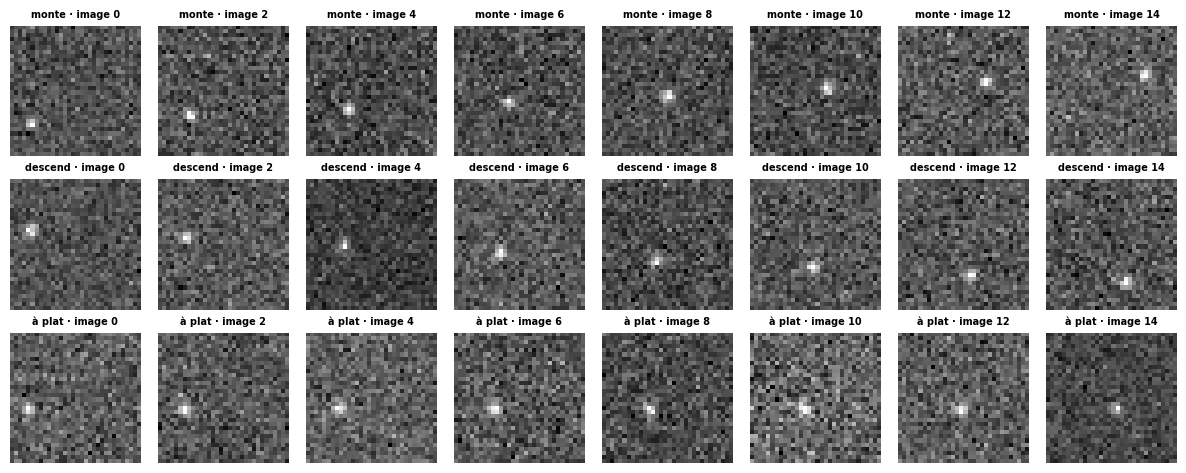

In [62]:
def make_ball_videos_28(n, frames=16, size=32, noise=0.15, seed=0):
    """n synthetic videos (n, frames, 1, size, size) of a ball crossing the image from left to right, and their labels:
    0 the ball goes up, 1 it goes down, 2 it flies flat. The middle height is random, so one frame alone cannot tell."""
    rng = np.random.default_rng(seed)
    labels = rng.integers(0, 3, n)
    t = np.arange(frames)
    xs = rng.uniform(3, 8, n)[:, None] + rng.uniform(0.9, 1.4, n)[:, None] * t           # left to right
    slope = rng.uniform(0.5, 1.0, n) * np.select([labels == 0, labels == 1], [-1, 1], 0)  # rows grow downwards
    ys = rng.uniform(10, 22, n)[:, None] + slope[:, None] * (t - (frames - 1) / 2)
    grid = np.arange(size)
    gx = np.exp(-(grid - xs[..., None]) ** 2 / 2)                                           # (n, frames, size)
    gy = np.exp(-(grid - ys[..., None]) ** 2 / 2)
    videos = gy[..., :, None] * gx[..., None, :] + noise * rng.normal(size=(n, frames, size, size))
    return torch.tensor(videos[:, :, None], dtype=torch.float32), torch.tensor(labels)


def fit_28(model, X, y, epochs=8, lr=3e-3, seed=0):
    """Given: Adam, cross-entropy, mini-batches of 64 in a new random order at each epoch."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(seed)
    model.train()
    for _ in range(epochs):
        for batch in torch.randperm(len(X), generator=generator).split(64):
            optimizer.zero_grad()
            F.cross_entropy(model(X[batch]), y[batch]).backward()
            optimizer.step()
    return model


VIDEOS_TRAIN_28, LABELS_TRAIN_28 = make_ball_videos_28(1500, seed=28)
VIDEOS_TEST_28, LABELS_TEST_28 = make_ball_videos_28(600, seed=29)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for row_28, label_28 in enumerate((0, 1, 2)):
    video_28 = VIDEOS_TRAIN_28[int(np.flatnonzero(LABELS_TRAIN_28.numpy() == label_28)[0])]
    for col_28, frame_28 in enumerate(range(0, 16, 2)):
        axes[row_28, col_28].imshow(video_28[frame_28, 0], cmap="gray")
        axes[row_28, col_28].set_title(f"{['monte', 'descend', 'à plat'][label_28]} · image {frame_28}", fontsize=7)
        axes[row_28, col_28].axis("off")
plt.tight_layout()
plt.show()

In [63]:
params_28 = (8 * 1 * 5 * 5 + 8) + 4 * (128 * 32 + 32 * 32 + 2 * 32) + (32 * 3 + 3)   # 208 + 20 736 + 99


class BallCNNLSTM_28(nn.Module):
    """Videos (N, T, 1, 32, 32) -> logits (N, 3). Each frame alone: nn.Conv2d(1, 8, 5, stride=2, padding=2), ReLU,
    nn.AdaptiveMaxPool2d(4), flattened to 128 values; the T vectors of a video: nn.LSTM(128, 32, batch_first=True);
    the output of the last step: nn.Linear(32, 3)."""

    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(nn.Conv2d(1, 8, 5, stride=2, padding=2), nn.ReLU(), nn.AdaptiveMaxPool2d(4), nn.Flatten())
        self.lstm = nn.LSTM(128, 32, batch_first=True)
        self.head = nn.Linear(32, 3)

    def forward(self, videos):
        n, t = videos.shape[:2]
        frames = videos.reshape(n * t, *videos.shape[2:])       # every frame of every video: (N T, 1, 32, 32)
        features = self.cnn(frames).reshape(n, t, -1)           # back to one sequence per video: (N, T, 128)
        out, _ = self.lstm(features)
        return self.head(out[:, -1])


wb.check("22.28a", params_28)
model_28 = None
with checked("22.28"):
    torch.manual_seed(2228)
    model_28 = BallCNNLSTM_28()
    with torch.no_grad():
        out_probe_28 = model_28(VIDEOS_TRAIN_28[:5])
    verdict("22.28", tuple(out_probe_28.shape) == (5, 3), "5 vidéos (5, 16, 1, 32, 32) donnent des logits (5, 3).",
            f"5 vidéos (5, 16, 1, 32, 32) donnent {shape_text(out_probe_28)} : attendu (5, 3).")
    verdict("22.28", n_params(model_28) == 21_043, "21 043 paramètres, comme le contrat.",
            f"{n_params(model_28):_} paramètres : le contrat en donne 21 043 ; relis les tailles des couches.".replace("_", " "))
    with torch.no_grad():                                      # a frame must be read alone by the convolution
        moved_28 = VIDEOS_TRAIN_28[:2].clone()
        moved_28[1] = VIDEOS_TRAIN_28[2]
        same_first_28 = torch.allclose(model_28(moved_28)[0], out_probe_28[0], atol=1e-6)
    verdict("22.28", same_first_28, "la prédiction d'une vidéo ne dépend que de cette vidéo.",
            "changer la vidéo 1 d'un mini-batch change la prédiction de la vidéo 0 : regarde comment tu remets les "
            "images en (N, T, features) après la convolution.")
    started_28 = time.perf_counter()
    fit_28(model_28, VIDEOS_TRAIN_28, LABELS_TRAIN_28)
    model_28.eval()
    with torch.no_grad():
        acc_28 = (model_28(VIDEOS_TEST_28).argmax(1) == LABELS_TEST_28).float().mean().item()
        order_28 = torch.randperm(16, generator=torch.Generator().manual_seed(1))
        acc_shuffled_28 = (model_28(VIDEOS_TEST_28[:, order_28]).argmax(1) == LABELS_TEST_28).float().mean().item()
        acc_reversed_28 = (model_28(VIDEOS_TEST_28.flip(1)).argmax(1) == LABELS_TEST_28).float().mean().item()
    print(f"training: {time.perf_counter() - started_28:.0f} s")
    print(f"test accuracy: {acc_28:.3f} · frames shuffled (same order for every video): {acc_shuffled_28:.3f} · "
          f"frames reversed: {acc_reversed_28:.3f}")
    verdict("22.28", acc_28 >= 0.9, "au moins 90 % d'accuracy sur les 600 vidéos de test.",
            f"accuracy {acc_28:.3f} : attendu au moins 0,9 ; relis le contrat (le LSTM lit la sortie du dernier pas).")

✅ Ex 22.28a : Parfait !
✅ Ex 22.28 : 5 vidéos (5, 16, 1, 32, 32) donnent des logits (5, 3).
✅ Ex 22.28 : 21 043 paramètres, comme le contrat.
✅ Ex 22.28 : la prédiction d'une vidéo ne dépend que de cette vidéo.


training: 5 s
test accuracy: 0.980 · frames shuffled (same order for every video): 0.498 · frames reversed: 0.247
✅ Ex 22.28 : au moins 90 % d'accuracy sur les 600 vidéos de test.


In [64]:
wb.record("22.28a", 21_043, mistakes={"PyTorch donne deux vecteurs de biais à chaque porte du LSTM": 21_043 - 4 * 32,
          "le LSTM reçoit toute la carte aplatie de chaque image, pas une valeur par filtre": 208 + 4 * (8 * 32 + 32 * 32 + 64) + 99,
          "n'oublie pas les biais de la convolution et de la couche dense": 21_043 - 8 - 3})

WB_ANSWER {"hash": "597f48d810f65cc7b227ff56d4ff6ea5def4c9fa4419082281c51127b682cb0d", "id": "22.28a", "kind": "int", "magnitude": 4, "mistakes": {"327b576af0528be4a6e80028552c81bc0ae1af7e263797ca8c2337e360a9ce3c": "PyTorch donne deux vecteurs de biais à chaque porte du LSTM", "62ad86b52275643555c065c7e6f84c4effda50ff8bc8fc4112867691ef6c507a": "n'oublie pas les biais de la convolution et de la couche dense", "7579e3c001b252a90df20138b643c36c93274c421415d3a7c4f7d14b590b2bf7": "le LSTM reçoit toute la carte aplatie de chaque image, pas une valeur par filtre"}, "sign": 1}
📝 Ex 22.28a : réponse enregistrée (int).


💡 Le réseau atteint environ 98 % : la convolution trouve la balle dans chaque image, le LSTM suit sa hauteur d'une image à l'autre. Mélanger les images garde chaque image intacte mais détruit le mouvement : le réseau ne voit plus qu'une suite de positions sans ordre et tombe autour de 50 % (il reconnaît encore une partie des vols à plat). À l'envers, une balle qui monte devient une balle qui descend, et elle va de droite à gauche, ce que le réseau n'a jamais vu : il confond les deux pentes et même le vol à plat, d'où un quart environ. Avec la carte entière, le LSTM recevrait 2 048 valeurs par image : $4 \times (2\,048 \times 32 + 32^2 + 64) = 266\,496$ poids, treize fois plus, pour une information que le max pooling garde.

### Ex 22.29 — Défi taches solaires : battre la persistance de 20 % à six mois 🏆 ★★★★ ⏱️ 120 min
**Objectif :** construire la meilleure prévision à six mois des taches solaires, jugée sur une période qu'on ne voit qu'une fois.  
**Prérequis :** Ex 22.23 · Ex 22.21 · ch. 8 et 15 (validation) · fiche « Au-delà du livre » · **Fil rouge :** taches solaires · **Parcours :** C

Le défi : prévoir la moyenne mensuelle des taches solaires **6 mois** à l'avance mieux que la persistance, avec la méthode de ton choix (un LSTM, un GRU, un modèle de scikit-learn, un mélange…).

**Contrat**
- `make_forecaster_29(train)` reçoit les valeurs mensuelles d'une période (un tableau de `float`) et ajuste ta méthode **sur elles seules** ; elle rend une fonction `forecast(past)` ;
- `forecast(past)` reçoit tous les mois connus jusqu'ici (au moins ceux de `train`, et ceux qui ont suivi) et rend la valeur prévue **6 mois après** la dernière valeur de `past`, un nombre. Elle ne réajuste rien : elle lit `past`.

La vérification calcule le **score public** : `make_forecaster_29(SPOTS[:I86])`, puis une prévision pour chaque mois de 1986 à 2005, comparée à la persistance (le rapport des RMSE ; la persistance vaut 1). Si ce score vaut au plus 0,80, elle révèle le **test caché** : la même chose avec un entraînement jusqu'à fin 2005 et les cibles de 2006 à la fin de la série. Le défi est réussi avec un rapport d'au plus `GOAL_29` = 0,80 sur les deux périodes ; palier 🌟 : au plus `STAR_29` = 0,78 sur le test caché.

Règles d'honneur : ta fonction n'utilise que `train` et `past` (pendant l'évaluation, `SPOTS` et `SUNSPOTS` cachent les mois à venir : les lire donne des NaN) ; le test caché n'est révélé qu'**une fois par session**, et le résultat est figé ; règle tes choix sur la période publique, ou mieux, sur une validation prise dans `train` (ch. 15), car un réglage poussé sur 1986-2005 risque de ne pas tenir sur 2006-2026 (le cycle 24 a été le plus faible depuis un siècle).

Dans tes notes : quelle méthode as-tu retenue, pourquoi, et quels essais ont échoué ? Ton score public et ton score caché sont-ils proches ? Sinon, qu'est-ce que cela dit de la façon dont tu as réglé ta méthode ?

In [65]:
SERIES_29 = SPOTS.copy()                       # a private copy: the evaluation reads this one
GOAL_29, STAR_29 = 0.80, 0.78
HORIZON_29 = 6


def score_29(make_forecaster, train_end, start, stop):
    """RMSE ratio to persistence of the forecasts of the targets start..stop-1, by a forecaster made from the months
    before train_end. While it runs, the global SPOTS and SUNSPOTS hide every month from train_end on (NaN)."""
    global SPOTS, SUNSPOTS
    saved = SPOTS, SUNSPOTS
    SPOTS = np.where(np.arange(len(SERIES_29)) < train_end, SERIES_29, np.nan)
    SUNSPOTS = saved[1].assign(sunspots=SPOTS)
    try:
        forecast = make_forecaster(SERIES_29[:train_end].copy())
        preds = np.array([float(forecast(SERIES_29[:t - HORIZON_29 + 1].copy())) for t in range(start, stop)])
    finally:
        SPOTS, SUNSPOTS = saved
    truth = SERIES_29[start:stop]
    rmse = np.sqrt(np.mean((preds - truth) ** 2))
    persistence = np.sqrt(np.mean((SERIES_29[start - HORIZON_29:stop - HORIZON_29] - truth) ** 2))
    return rmse / persistence, preds

public score (trained before 1986, targets 1986-2005): 0.740 of the persistence RMSE (1 s)


hidden test (trained before 2006, targets 2006-01 to 2026-03): 0.786 (revealed once per session: a new run shows the same frozen result)
✅ Ex 22.29 : défi réussi : au plus 0,80 de la RMSE de la persistance sur les deux périodes.


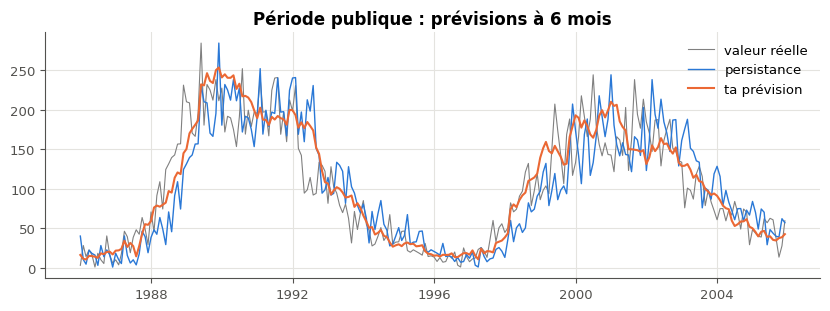

In [66]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def features_29(v):
    """Features of a past v (square-root scale, at least 132 months): the recent level at several scales, the trend
    over a year, and the level 9 to 11 years ago (the cycle lasts about 11 years)."""
    return np.array([v[-1], v[-2:].mean(), v[-3:].mean(), v[-6:].mean(), v[-12:].mean(), v[-24:].mean(), v[-48:].mean(),
                     v[-1] - v[-13], v[-120:-108].mean(), v[-132:-120].mean()])


def make_forecaster_29(train):
    """Fit a forecaster on `train` (the monthly values of a period, a float array) and return forecast(past): the
    value 6 months after the last value of `past` (all the months known so far, at least those of `train`)."""
    s = np.sqrt(np.asarray(train, dtype=float))                 # the square root tames the peaks of the cycle
    first = 132 + HORIZON_29 - 1                                # the first target with 132 months of past
    X = np.array([features_29(s[:t - HORIZON_29 + 1]) for t in range(first, len(s))])
    y = s[first:]
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X, y)
    trees = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0).fit(X, y)

    def forecast(past):
        f = features_29(np.sqrt(np.asarray(past, dtype=float)))[None]
        return float(max((ridge.predict(f)[0] + trees.predict(f)[0]) / 2, 0.0) ** 2)

    return forecast


with checked("22.29"):
    started_29 = time.perf_counter()
    public_29, preds_29 = score_29(make_forecaster_29, I86, I86, I06)
    print(f"public score (trained before 1986, targets 1986-2005): {public_29:.3f} of the persistence RMSE "
          f"({time.perf_counter() - started_29:.0f} s)")
    if not np.all(np.isfinite(preds_29)):
        print("❌ Ex 22.29 : des prévisions ne sont pas des nombres finis (NaN) : ta fonction lit-elle SPOTS ou "
              "SUNSPOTS au lieu de train et past ?")
    elif public_29 > GOAL_29:
        print(f"❌ Ex 22.29 : {public_29:.3f} sur la période publique : il faut au plus {fr(GOAL_29, 2)} avant de révéler le test caché.")
    else:
        REVEALED_29 = globals().get("REVEALED_29")
        if REVEALED_29 is None:                                 # revealed once per session (an honour rule)
            REVEALED_29 = score_29(make_forecaster_29, I06, I06, len(SERIES_29))[0]
        hidden_29 = REVEALED_29
        print(f"hidden test (trained before 2006, targets {SUNSPOTS['date'].iloc[I06]:%Y-%m} to "
              f"{SUNSPOTS['date'].iloc[-1]:%Y-%m}): {hidden_29:.3f} (revealed once per session: a new run shows the "
              "same frozen result)")
        verdict("22.29", hidden_29 <= GOAL_29,
                f"défi réussi : au plus {fr(GOAL_29, 2)} de la RMSE de la persistance sur les deux périodes."
                + (f" 🌟 Palier atteint : au plus {fr(STAR_29, 2)} sur le test caché." if hidden_29 <= STAR_29 else ""),
                f"pas encore : {hidden_29:.3f} sur le test caché, il faut au plus {fr(GOAL_29, 2)}. Le résultat est figé "
                "pour cette session : repense ta méthode sur une validation prise dans train, sans la régler au plus près de la période publique.")
    fig, ax = plt.subplots(figsize=(10, 3.2))
    dates_29 = SUNSPOTS["date"].iloc[I86:I06]
    ax.plot(dates_29, SERIES_29[I86:I06], lw=0.8, color="0.5", label="valeur réelle")
    ax.plot(dates_29, SERIES_29[I86 - 6:I06 - 6], lw=1, label="persistance")
    ax.plot(dates_29, preds_29, lw=1.5, label="ta prévision")
    ax.set_title("Période publique : prévisions à 6 mois")
    ax.legend()
    plt.show()

💡 Le corrigé n'utilise pas de réseau : des moyennes des derniers mois à plusieurs échelles, la tendance sur un an et le niveau d'il y a 9 à 11 ans (la durée du cycle), sur la racine carrée de la série (qui calme les pics), passés à une régression ridge et à un gradient boosting dont on moyenne les prévisions. Il obtient environ 0,74 sur la période publique et 0,79 sur le test caché. Le LSTM de 22.23, utilisé comme prévision, fait 0,77 sur la période publique mais près de 0,9 sur le test caché : réglé sur 1986-2005, il ne tient pas sur un cycle bien plus faible que ceux qu'il a vus. C'est la leçon du défi : le score qu'on annonce est celui d'une période qu'on n'a pas utilisée pour choisir.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire les équations d'une cellule RNN, LSTM et GRU, et compter leurs paramètres ?
2. Sais-tu expliquer pourquoi le gradient d'un RNN s'évanouit ou explose, et ce que change le chemin additif du LSTM ?
3. Sais-tu préparer une série temporelle sans fuite, et régler la température d'un générateur ?

**Pour aller plus loin** : le billet de C. Olah sur les LSTM et celui d'A. Karpathy sur les RNN, cités dans la fiche. La suite : le ch. 23, Keras, traduit en PyTorch.